<a href="https://colab.research.google.com/github/Nerucho2005/RedesNeuronales/blob/main/TPs_1_2_y_3_Actualizados_Ramiro_Grin.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Ramiro Grin - Legajo 65014**

# TP - Clasificación Multiclase de Texto con Regresión Softmax
### Redes Neuronales / Deep Learning

Dataset: **20 Newsgroups** (~18.000 posts de foros de Usenet, clasificados en 20 categorías).

## Objetivos
- Implementar un pipeline de preprocesamiento de texto **configurable** (stopwords, stemming, lematización, n-gramas).
- Implementar una **Regresión Softmax** (regresión logística multinomial) en PyTorch: una única capa lineal + `CrossEntropyLoss`, sin capas ocultas.
- Trackear el entrenamiento con **TensorBoard** y **MLflow**.
- Usar **Optuna** para buscar la mejor combinación de hiperparámetros de preprocesamiento *y* de entrenamiento en conjunto.

## Qué hay que completar
Los bloques marcados `# TODO` son los que tienen que completar ustedes. El resto ya está resuelto.

Esta notebook es individual/standalone: no tiene una sección de defensa grupal asociada.


In [ ]:
from google.colab import drive
drive.mount("/content/drive")
import os
os.makedirs("/content/drive/MyDrive/RedesTP", exist_ok=True)
os.chdir("/content/drive/MyDrive/RedesTP")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Registro de correcciones (reentrega)

Esta versión corrige los puntos de la devolución de TP1, TP2 y TP3. Cada cambio está marcado en el notebook con **🔧 Corrección**.


## 0. Setup

In [ ]:
!pip install -q mlflow optuna


**Qué hace este código:** importa las librerías y fija la configuración global del experimento.

- `set_seed(seed)` fija las semillas de `random`, NumPy y PyTorch. Se llama antes de crear cada modelo, así la inicialización de pesos y el orden de los batches son reproducibles.
- 🔧 **Corrección:** el presupuesto de búsqueda (`N_TRIALS`, `EPOCHS_SEARCH`) se define una sola vez y se usa en la Parte 1 y en la Parte 2, para que la comparación softmax vs. MLP sea justa.
- `SEEDS` son las semillas con las que se repiten los modelos finales para estimar el ruido entre corridas.
- Los resultados se guardan en `results/`, así la Parte 2 lee los números de la Parte 1 desde disco y no depende de variables en memoria.

In [ ]:
import os
import re
import json
import time
import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler, MaxAbsScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

from torch.utils.tensorboard import SummaryWriter
import mlflow
import mlflow.pytorch
import optuna

# ------------------------------------------------------------------
# Configuración global (compartida por la Parte 1 y la Parte 2)
# ------------------------------------------------------------------
SEED = 42                # semilla principal: split train/val, sampler de Optuna, modelos finales
SEEDS = [0, 1, 2, 3, 4]  # semillas para repetir los modelos finales y medir el ruido entre corridas
N_TRIALS = 40            # MISMO número de trials para softmax y MLP
EPOCHS_SEARCH = 10       # épocas máximas por trial de Optuna
PATIENCE_SEARCH = 3      # early stopping dentro de cada trial
MAX_EPOCHS_FINAL = 50    # épocas máximas de los entrenamientos finales
PATIENCE_FINAL = 5       # early stopping de los entrenamientos finales
RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)

Usando dispositivo: cuda


In [ ]:
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("punkt")
nltk.download("punkt_tab")


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

## 1. Datos: 20 Newsgroups

Usamos `remove=('headers', 'footers', 'quotes')` para sacar metadata que haría el problema "demasiado fácil" (por ejemplo, el header a veces incluye el nombre del newsgroup).

In [ ]:
newsgroups_train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
newsgroups_test  = fetch_20newsgroups(subset="test",  remove=("headers", "footers", "quotes"))

class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)
print(f"Clases ({NUM_CLASSES}):", class_names)
print(f"\nTrain: {len(newsgroups_train.data)} documentos | Test: {len(newsgroups_test.data)} documentos")

print("\n--- Ejemplo de documento ---")
print("Categoría:", class_names[newsgroups_train.target[0]])
print(newsgroups_train.data[0][:500])


Clases (20): ['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']

Train: 11314 documentos | Test: 7532 documentos

--- Ejemplo de documento ---
Categoría: rec.autos
I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, history, or whatever info you
have on this funky looking car, please e-mail.


**Qué hace este código:** descarga el split oficial de train/test de 20 Newsgroups, sin headers, footers ni citas, y muestra las clases, la cantidad de documentos y un ejemplo. El test oficial se reserva para la evaluación final. La validación se arma más adelante, con una partición del train.

## 2. Preprocesamiento configurable

Vamos a armar una función de preprocesamiento con estos hiperparámetros (todos van a formar parte de la búsqueda de Optuna más adelante):

- `remove_stopwords` (`True`/`False`): sacar palabras muy frecuentes y poco informativas (`the`, `is`, `and`, ...).
- `normalization` (`"none"` / `"stem"` / `"lemmatize"`):
  - `"none"`: no se normaliza la palabra.
  - `"stem"`: **stemming** con Porter Stemmer — corta la palabra a una raíz heurística (`"running"` → `"run"`, a veces resultados no son palabras reales: `"studies"` → `"studi"`).
  - `"lemmatize"`: **lematización** con WordNet — lleva la palabra a su forma de diccionario (`"running"` → `"run"`, `"studies"` → `"study"`), más lenta pero más "correcta" lingüísticamente.

### TODO 1: completar `preprocess_text`

Pasos esperados:
1. Tokenizar el texto con `word_tokenize`.
2. Pasar todo a minúsculas y quedarse solo con tokens alfabéticos (`token.isalpha()`), para descartar números y puntuación.
3. Si `remove_stopwords` es `True`, sacar los tokens que estén en el set de stopwords.
4. Según `normalization`, aplicar `stemmer.stem(token)`, `lemmatizer.lemmatize(token)`, o dejar el token igual.
5. Devolver los tokens unidos con espacios (un string, para poder pasárselo después a `TfidfVectorizer`).

In [ ]:
STOP_WORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()
LEMMATIZER = WordNetLemmatizer()


def preprocess_text(text, remove_stopwords, normalization):
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha()]

    # TODO: si remove_stopwords es True, filtrar los tokens que están en STOP_WORDS
    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]

    # TODO: aplicar la normalización correspondiente según el valor de `normalization`
    if normalization == "stem":
        tokens = [STEMMER.stem(t) for t in tokens]
    elif normalization == "lemmatize":
        tokens = [LEMMATIZER.lemmatize(t) for t in tokens]
    # si normalization == "none", no se hace nada más

    return " ".join(tokens)

**Qué hace este código:** `preprocess_text` recibe un documento y devuelve un string con los tokens limpios.

1. `word_tokenize(text.lower())` separa en palabras y pasa todo a minúsculas.
2. `t.isalpha()` descarta números, puntuación y tokens mixtos.
3. Si `remove_stopwords=True`, se filtran las palabras de `STOP_WORDS` (set de NLTK, con búsqueda O(1)).
4. Según `normalization`, se aplica el stemmer de Porter, el lematizador de WordNet o nada.
5. Los tokens se unen con espacios porque `TfidfVectorizer` espera strings.

La celda siguiente es un *sanity check* con las 6 combinaciones sobre una misma oración.

In [ ]:
# Sanity check: probamos las distintas combinaciones sobre una oración de ejemplo
ejemplo = "The researchers were studying the running processes and stopping conditions of the engines."
for norm in ["none", "stem", "lemmatize"]:
    for rm_sw in [False, True]:
        resultado = preprocess_text(ejemplo, remove_stopwords=rm_sw, normalization=norm)
        print(f"normalization={norm:10s} remove_stopwords={str(rm_sw):5s} -> {resultado}")


normalization=none       remove_stopwords=False -> the researchers were studying the running processes and stopping conditions of the engines
normalization=none       remove_stopwords=True  -> researchers studying running processes stopping conditions engines
normalization=stem       remove_stopwords=False -> the research were studi the run process and stop condit of the engin
normalization=stem       remove_stopwords=True  -> research studi run process stop condit engin
normalization=lemmatize  remove_stopwords=False -> the researcher were studying the running process and stopping condition of the engine
normalization=lemmatize  remove_stopwords=True  -> researcher studying running process stopping condition engine


## 3. Vectorización TF-IDF

Convertimos los textos preprocesados en vectores numéricos con `TfidfVectorizer`. Como el preprocesamiento (tokenización, stopwords, normalización) ya lo hicimos nosotros, acá solo controlamos:

- `ngram_range`: `(1,1)` solo unigramas, o `(1,2)` unigramas + bigramas (captura algo de contexto, ej. `"new york"`).
- `max_features`: tamaño máximo del vocabulario (se queda con los términos más frecuentes).
- `min_df`: un término tiene que aparecer en al menos `min_df` documentos para entrar al vocabulario (filtra términos rarísimos / errores de tipeo).
- `norm`: normalización por documento (ver 3.1).

### TODO 2: completar `vectorize_data`

**Qué hace este código:** el vectorizador se ajusta (`fit_transform`) **solo** con los textos de entrenamiento: el vocabulario y los IDF salen de train. Después se aplica (`transform`) a val/test. Así no se filtra información de los conjuntos de evaluación. Devuelve matrices esparsas `scipy.sparse` y el vectorizador ajustado.

In [ ]:
def vectorize_data(train_texts, test_texts, ngram_range, max_features, min_df, norm="l2"):
    # norm="l2" es el default de sklearn; lo dejamos explícito (ver 3.1)
    vectorizer = TfidfVectorizer(ngram_range=ngram_range, max_features=max_features,
                                 min_df=min_df, norm=norm)
    X_train = vectorizer.fit_transform(train_texts)
    X_test = vectorizer.transform(test_texts)
    return X_train, X_test, vectorizer

In [ ]:
# Sanity check rápido con pocos documentos
_sample_train = ["the cat sat on the mat", "dogs are running in the park", "cats and dogs are pets"]
_sample_test = ["the dog sat on the mat"]
_Xtr, _Xte, _vec = vectorize_data(_sample_train, _sample_test, ngram_range=(1, 1), max_features=50, min_df=1)
assert _Xtr is not None, "Completá vectorize_data"
print("Shape train:", _Xtr.shape, "| Shape test:", _Xte.shape)
print("Vocabulario (parcial):", list(_vec.vocabulary_.keys())[:10])

# 🔧 Verificación de la normalización: cada documento debe tener norma L2 = 1
_row_norms = np.sqrt(np.asarray(_Xtr.multiply(_Xtr).sum(axis=1))).ravel()
print("Norma L2 de cada documento de train:", np.round(_row_norms, 4))
assert np.allclose(_row_norms, 1.0), "Las filas de TF-IDF deberían tener norma 1"

Shape train: (3, 13) | Shape test: (1, 13)
Vocabulario (parcial): ['the', 'cat', 'sat', 'on', 'mat', 'dogs', 'are', 'running', 'in', 'park']
Norma L2 de cada documento de train: [1. 1. 1.]


### 3.1 🔧 Normalización de los datos

**Los datos sí están normalizados**, aunque en la entrega original quedaba implícito. `TfidfVectorizer` usa `norm="l2"` por defecto, así que cada documento (fila) queda con norma euclídea 1. Ahora el parámetro está explícito y la celda anterior lo verifica.

Por qué hace falta normalizar en este problema:

- **El largo del documento no debería definir la escala de la entrada.** Sin normalización, un post largo tiene valores TF-IDF más grandes que uno corto aunque trate el mismo tema. Las pre-activaciones $z = Wx + b$ de la primera capa crecen con el largo del texto. Eso satura sigmoid/tanh, achica los gradientes y obliga a usar un learning rate más chico para no divergir con los documentos largos.
- **Con entradas acotadas** (componentes en $[0, 1]$ y $\|x\|_2 = 1$), el producto interno con los pesos mide similitud de contenido (coseno), y un mismo learning rate funciona bien para todos los documentos.

Por qué **no** estandarizamos por columna con centrado (`StandardScaler` con media): restar la media de cada feature convierte la matriz esparsa en densa, porque todos los ceros pasan a valer $-\mu_j$. Además la media está dominada por los ceros, así que no representa bien la distribución del término. Si se quiere escalar por columna, las opciones que preservan la esparsidad son `StandardScaler(with_mean=False)` (dividir por el desvío) o `MaxAbsScaler` (llevar cada columna a $[0, 1]$). Cualquiera de los dos se ajusta **solo con train**.

En la sección 7.2 se comparan empíricamente: sin normalizar, L1 por documento, L2 por documento (default) y L2 + escalado por columna.

## 4. Modelo: Regresión Softmax

La regresión softmax (regresión logística multinomial) es el modelo más simple posible para clasificación multiclase: **una sola capa lineal** que mapea el vector de entrada a un score (logit) por clase, sin ninguna no-linealidad ni capa oculta.

`CrossEntropyLoss` de PyTorch ya incluye internamente un `log_softmax` + `NLLLoss`, así que el modelo **no debe aplicar softmax en el forward** — hay que devolver los logits crudos.

### TODO 3: completar `SoftmaxRegression`

In [ ]:
class SoftmaxRegression(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        # definir una única capa lineal de input_dim a num_classes
        self.linear = nn.Linear(input_dim, num_classes)

    def forward(self, x):
        # devolver los logits (salida de self.linear), SIN aplicar softmax
        return self.linear(x)


**Qué hace este código:** `SoftmaxRegression` tiene una sola capa `nn.Linear(input_dim, num_classes)`, es decir, $W \in \mathbb{R}^{20 \times d}$ y $b \in \mathbb{R}^{20}$. El `forward` devuelve los logits sin softmax, porque `CrossEntropyLoss` aplica `log_softmax` internamente. La celda siguiente comprueba que la salida tenga forma `(batch, 20)`.

In [ ]:
# Sanity check
_dummy = torch.randn(4, 50)
_model_check = SoftmaxRegression(input_dim=50, num_classes=20)
_out = _model_check(_dummy)
assert _out is not None and _out.shape == (4, 20), "Revisá SoftmaxRegression"
print("Shape de salida OK:", _out.shape)


Shape de salida OK: torch.Size([4, 20])


## 5. Entrenamiento

Como los datos vectorizados entran en memoria sin problema, armamos `DataLoader`s a partir de tensores densos. Logueamos loss y accuracy (train y validación) por época a TensorBoard, y a MLflow también los hiperparámetros y el modelo final.

🔧 **Corrección:** la función de entrenamiento original se reemplazó por `train_model`, que usan tanto la softmax como el MLP. Agrega:

- **Medición de tiempos:** `history["epoch_time_sec"]` guarda el tiempo de cada época (train + val) y `history["train_time_sec"]` el total. Con eso se arma la tabla de épocas vs. segundos y se calcula `time_to_best_sec`, el tiempo hasta alcanzar la mejor validación (tiempo de convergencia).
- **Early stopping** con `patience`: si `val_acc` no mejora durante `patience` épocas seguidas, se corta el entrenamiento y **se restauran los pesos de la mejor época**.
- **Pruning de Optuna** (se usa en la Parte 2): si recibe un `trial`, reporta `val_acc` en cada época y lo corta si el pruner lo indica.

In [ ]:
%load_ext tensorboard


In [ ]:
def make_dataset(X, y):
    # X esparsa -> tensor denso float32; y -> long
    X_dense = torch.tensor(X.toarray(), dtype=torch.float32)
    y_tensor = torch.tensor(np.asarray(y), dtype=torch.long)
    return TensorDataset(X_dense, y_tensor)


def make_loader(dataset, batch_size, shuffle, seed=SEED):
    # Generador con semilla propia: el orden de los batches es reproducible
    g = torch.Generator()
    g.manual_seed(seed)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, generator=g if shuffle else None)


def split_train_val(texts, labels):
    # MISMO split en todo el notebook (Parte 1 y Parte 2): 80/20 estratificado con SEED
    return train_test_split(texts, labels, test_size=0.2, random_state=SEED, stratify=labels)


def run_epoch(model, loader, criterion, optimizer=None):
    # Una pasada por el loader. Si hay optimizer, entrena; si no, solo evalúa.
    training = optimizer is not None
    model.train(training)
    running_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            running_loss += loss.item() * xb.size(0)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)
    return running_loss / total, correct / total


def train_model(model, train_loader, val_loader, optimizer, epochs, patience=None,
                writer=None, run_name="model", trial=None, log_mlflow=False, verbose=True):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "epoch_time_sec": []}
    best_val_acc, best_epoch, best_state = -1.0, -1, None
    epochs_without_improvement = 0
    t_start = time.perf_counter()

    def _finish():
        history["train_time_sec"] = time.perf_counter() - t_start
        history["best_val_acc"] = best_val_acc
        history["best_epoch"] = best_epoch + 1                       # 1-indexado
        history["epochs_run"] = len(history["val_acc"])
        history["time_to_best_sec"] = float(np.sum(history["epoch_time_sec"][:best_epoch + 1]))
        if trial is not None:
            for k in ["train_time_sec", "best_epoch", "epochs_run", "time_to_best_sec"]:
                trial.set_user_attr(k, history[k])
            trial.set_user_attr("sec_per_epoch", float(np.mean(history["epoch_time_sec"])))

    for epoch in range(epochs):
        t_epoch = time.perf_counter()
        train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc = run_epoch(model, val_loader, criterion)
        if device.type == "cuda":
            torch.cuda.synchronize()
        history["epoch_time_sec"].append(time.perf_counter() - t_epoch)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc, best_epoch = val_acc, epoch
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if verbose:
            print(f"[{run_name}] Epoch {epoch+1}/{epochs} - "
                  f"train_loss: {train_loss:.4f} train_acc: {train_acc:.4f} - "
                  f"val_loss: {val_loss:.4f} val_acc: {val_acc:.4f} - "
                  f"{history['epoch_time_sec'][-1]:.2f}s")
        if writer is not None:
            writer.add_scalars("loss", {"train": train_loss, "val": val_loss}, epoch)
            writer.add_scalars("accuracy", {"train": train_acc, "val": val_acc}, epoch)
        if log_mlflow:
            mlflow.log_metrics({"train_loss": train_loss, "val_loss": val_loss,
                                "train_acc": train_acc, "val_acc": val_acc,
                                "epoch_time_sec": history["epoch_time_sec"][-1]}, step=epoch)

        if trial is not None:
            trial.report(val_acc, epoch)
            if trial.should_prune():
                _finish()
                raise optuna.TrialPruned()

        if patience is not None and epochs_without_improvement >= patience:
            if verbose:
                print(f"[{run_name}] Early stopping en la época {epoch+1} "
                      f"(mejor val_acc={best_val_acc:.4f} en la época {best_epoch+1})")
            break

    _finish()
    if best_state is not None:
        model.load_state_dict(best_state)   # nos quedamos con los pesos de la mejor época
    return history


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    preds, labels = [], []
    for xb, yb in loader:
        logits = model(xb.to(device))
        preds.extend(logits.argmax(dim=1).cpu().numpy())
        labels.extend(yb.numpy())
    return accuracy_score(labels, preds), np.array(preds), np.array(labels)

**Qué hace este código:**

- `make_dataset` / `make_loader`: pasan la matriz esparsa a un tensor denso y arman el `DataLoader`. El `torch.Generator` con semilla hace que el *shuffle* sea reproducible.
- `split_train_val`: define **el** split de validación del notebook (80/20 estratificado, `random_state=SEED`). Se usa en todas las búsquedas y entrenamientos, de la Parte 1 y de la Parte 2.
- `run_epoch`: una pasada por los datos. Con optimizador hace `zero_grad → forward → loss → backward → step`; sin optimizador solo evalúa, sin gradientes.
- `train_model`: el loop de épocas. Mide los tiempos, guarda las curvas, aplica early stopping y restaura la mejor época, reporta a Optuna para el pruning y loguea a TensorBoard/MLflow.
- `evaluate`: accuracy y predicciones sobre un loader. Se usa **solo** para el test final.

## 6. Búsqueda de hiperparámetros con Optuna

La búsqueda incluye **hiperparámetros de preprocesamiento** (`remove_stopwords`, `normalization`, `ngram_range`, `max_features`, `min_df`) y **de entrenamiento** (`lr`, `batch_size`), todos en un mismo `objective`.

**Optimización de tiempo**: como la tokenización + stopwords + normalización es lo más lento del pipeline (y solo depende de `remove_stopwords` y `normalization`, que tienen pocas combinaciones posibles), la precalculamos una sola vez para las 6 combinaciones posibles y la cacheamos. Así, cada trial de Optuna solo repite la parte rápida (vectorizar + entrenar).

🔧 **Correcciones respecto de la entrega original:**
- `N_TRIALS = 40` (antes 15) y hasta `EPOCHS_SEARCH = 10` épocas por trial (antes 5 fijas), con early stopping (`PATIENCE_SEARCH = 3`). El valor que devuelve cada trial es la mejor `val_acc`, que corresponde a los pesos restaurados.
- Sampler `TPESampler(seed=SEED)`: con la misma semilla la búsqueda propone la misma secuencia de configuraciones, así que es reproducible.
- Cada trial guarda por separado el **tiempo de vectorización** y el **tiempo de entrenamiento** (`user_attrs`), además del tiempo por época y la época de la mejor validación.
- Al no indicar `pruner`, `optuna.create_study` usa por defecto un `MedianPruner`: los trials que en una época van peor que la mediana de los anteriores se cortan. En esta corrida cortó 18 de los 40 trials.
- El test **no** se usa en la búsqueda: se valida sobre el 20 % de train definido por `split_train_val`.

**Qué hace este código:** precalcula el preprocesamiento de train y test para las 6 combinaciones (`remove_stopwords` × `normalization`) y lo guarda en un diccionario. También cronometra cuánto tarda cada combinación, que es un costo fijo que no se repite en cada trial.

In [ ]:
print("Precalculando preprocesamiento para las 6 combinaciones posibles (puede tardar unos minutos)...")
preprocessed_cache = {}
preprocess_times = {}
for remove_stopwords in [False, True]:
    for normalization in ["none", "stem", "lemmatize"]:
        key = (remove_stopwords, normalization)
        t0 = time.perf_counter()
        train_proc = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_train.data]
        test_proc  = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_test.data]
        preprocess_times[key] = time.perf_counter() - t0
        preprocessed_cache[key] = (train_proc, test_proc)
        print(f"  listo: {key}  ({preprocess_times[key]:.1f} s)")

Precalculando preprocesamiento para las 6 combinaciones posibles (puede tardar unos minutos)...
  listo: (False, 'none')  (23.8 s)
  listo: (False, 'stem')  (60.7 s)
  listo: (False, 'lemmatize')  (34.0 s)
  listo: (True, 'none')  (24.4 s)
  listo: (True, 'stem')  (45.8 s)
  listo: (True, 'lemmatize')  (29.4 s)


**Qué hace este código:** `objective` es la función que Optuna maximiza.

1. Muestrea los HP de preprocesamiento y de entrenamiento. El `lr` va en escala logarítmica porque su efecto es multiplicativo.
2. Toma los textos ya preprocesados del cache y hace el split train/val de siempre.
3. Vectoriza (ajustando solo con train) y arma los loaders, cronometrando este paso aparte.
4. Entrena la softmax con Adam, con early stopping, y devuelve la mejor `val_acc`.

Después se corre el estudio con `N_TRIALS` trials y semilla fija, se mide el tiempo total de la búsqueda y se guarda la tabla de trials en `results/`.

In [ ]:
def objective(trial):
    remove_stopwords = trial.suggest_categorical("remove_stopwords", [False, True])
    normalization = trial.suggest_categorical("normalization", ["none", "stem", "lemmatize"])
    ngram_range = trial.suggest_categorical("ngram_range", ["1gram", "1_2gram"])
    ngram_range_tuple = (1, 1) if ngram_range == "1gram" else (1, 2)
    max_features = trial.suggest_categorical("max_features", [2000, 5000, 10000])
    min_df = trial.suggest_categorical("min_df", [1, 2, 5])
    lr = trial.suggest_float("lr", 1e-3, 1e-1, log=True)
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128])

    train_texts, _ = preprocessed_cache[(remove_stopwords, normalization)]
    # Partimos una porción de train como validación para la búsqueda (no usamos el test acá)
    tr_texts, val_texts, tr_labels, val_labels = split_train_val(train_texts, newsgroups_train.target)

    t0 = time.perf_counter()
    X_tr, X_val, _ = vectorize_data(tr_texts, val_texts, ngram_range_tuple, max_features, min_df)
    ds_tr, ds_val = make_dataset(X_tr, tr_labels), make_dataset(X_val, val_labels)
    trial.set_user_attr("vectorize_time_sec", time.perf_counter() - t0)
    train_loader = make_loader(ds_tr, batch_size, shuffle=True)
    val_loader = make_loader(ds_val, batch_size, shuffle=False)

    set_seed(SEED)
    model = SoftmaxRegression(input_dim=X_tr.shape[1], num_classes=NUM_CLASSES)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    history = train_model(model, train_loader, val_loader, optimizer, epochs=EPOCHS_SEARCH,
                          patience=PATIENCE_SEARCH, run_name=f"trial_{trial.number}",
                          trial=trial, verbose=False)
    return history["best_val_acc"]


mlflow.end_run()
study = optuna.create_study(direction="maximize", study_name="softmax",
                            sampler=optuna.samplers.TPESampler(seed=SEED))
t0 = time.perf_counter()
study.optimize(objective, n_trials=N_TRIALS)
wall_time_softmax = time.perf_counter() - t0

print("Mejores hiperparámetros:", study.best_params)
print("Mejor accuracy de validación:", study.best_value)
print(f"Tiempo total de la búsqueda: {wall_time_softmax:.1f} s")

df_softmax_trials = study.trials_dataframe()
df_softmax_trials.to_csv(f"{RESULTS_DIR}/tp1_softmax_trials.csv", index=False)

[I 2026-11-19 17:35:02,739] A new study created in memory with name: softmax
[I 2026-11-19 17:35:12,933] Trial 0 finished with value: 0.6173221387538665 and parameters: {'remove_stopwords': True, 'normalization': 'none', 'ngram_range': '1gram', 'max_features': 2000, 'min_df': 2, 'lr': 0.0026587543983272706, 'batch_size': 128}. Best is trial 0 with value: 0.6173221387538665.
[I 2026-11-19 17:35:19,959] Trial 1 finished with value: 0.650022094564737 and parameters: {'remove_stopwords': False, 'normalization': 'stem', 'ngram_range': '1_2gram', 'max_features': 5000, 'min_df': 2, 'lr': 0.016409286730647923, 'batch_size': 128}. Best is trial 1 with value: 0.650022094564737.
[I 2026-11-19 17:35:25,013] Trial 2 finished with value: 0.7229341581970835 and parameters: {'remove_stopwords': False, 'normalization': 'lemmatize', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 2, 'lr': 0.010968217207529524, 'batch_size': 128}. Best is trial 2 with value: 0.7229341581970835.
[I 2026-11-19 17:

Mejores hiperparámetros: {'remove_stopwords': True, 'normalization': 'stem', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 2, 'lr': 0.019747319318076214, 'batch_size': 64}
Mejor accuracy de validación: 0.7428192664604507
Tiempo total de la búsqueda: 179.6 s


### 6.1 🔧 Tiempos de la búsqueda

Tabla por trial: tiempo de vectorización, tiempo de entrenamiento, segundos por época, épocas corridas (con early stopping), época de la mejor validación y tiempo hasta alcanzarla.

**Qué hace este código:** toma `study.trials_dataframe()`, renombra las columnas relevantes y muestra la tabla ordenada por `val_acc`. Después calcula correlaciones de Spearman para ver qué HP explican el costo por época (`max_features`, `batch_size`) y cuáles el tiempo hasta converger (`lr`).

,trial,val_acc,lr,batch_size,max_features,ngram,norm_texto,t_vectorizar_s,t_entrenar_s,s_por_epoca,epocas_corridas,epoca_mejor_val,t_hasta_mejor_s
37,37,0.7428,0.0197,64,10000,1gram,stem,1.6286,2.7010,0.4496,6,3,1.3243
18,18,0.7424,0.0184,64,10000,1gram,stem,1.5907,2.6940,0.4484,6,3,1.3518
26,26,0.7402,0.0104,64,10000,1gram,stem,2.0119,3.5946,0.5128,7,4,2.1117
15,15,0.7397,0.0125,64,10000,1gram,stem,2.1497,4.6260,0.4619,10,7,3.2244
19,19,0.7397,0.0331,64,10000,1gram,stem,1.6245,2.5385,0.5071,5,2,0.9796
16,16,0.7393,0.0141,64,10000,1gram,stem,2.3392,4.0319,0.5032,8,5,2.5720
31,31,0.7357,0.0274,64,10000,1gram,stem,2.9093,2.7239,0.4533,6,3,1.3745
21,21,0.7357,0.0300,64,10000,1gram,stem,1.5219,2.2708,0.4536,5,2,0.9047
29,29,0.7353,0.0240,32,10000,1gram,stem,2.1859,3.5453,0.7084,5,2,1.3998
35,35,0.7353,0.0719,128,10000,1gram,stem,2.1681,1.6742,0.3343,5,2,0.6770


Totales de la búsqueda softmax:
  vectorización: 103.0 s | entrenamiento: 69.0 s | pared (wall-clock): 179.6 s

Correlación de Spearman (rho, p-valor):
  max_features vs s_por_epoca     : rho=+0.45  p=0.003
  batch_size   vs s_por_epoca     : rho=-0.73  p=0.000
  lr           vs epoca_mejor_val : rho=+0.36  p=0.024
  lr           vs t_hasta_mejor_s : rho=+0.29  p=0.069


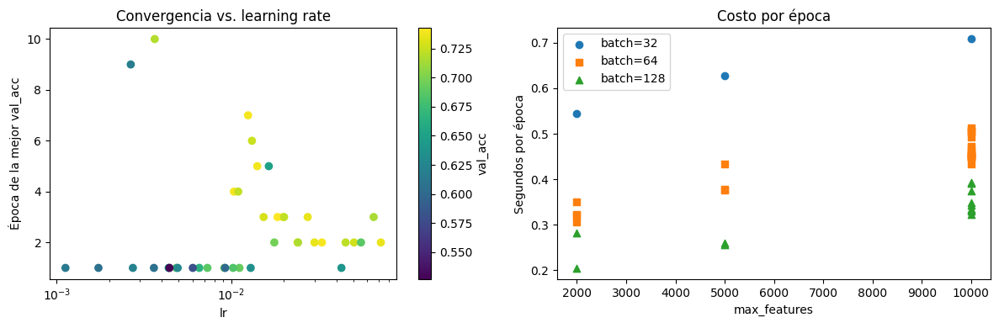

In [ ]:
cols = {
    "number": "trial", "value": "val_acc", "params_lr": "lr", "params_batch_size": "batch_size",
    "params_max_features": "max_features", "params_ngram_range": "ngram", "params_normalization": "norm_texto",
    "user_attrs_vectorize_time_sec": "t_vectorizar_s", "user_attrs_train_time_sec": "t_entrenar_s",
    "user_attrs_sec_per_epoch": "s_por_epoca", "user_attrs_epochs_run": "epocas_corridas",
    "user_attrs_best_epoch": "epoca_mejor_val", "user_attrs_time_to_best_sec": "t_hasta_mejor_s",
}
tabla_trials_softmax = df_softmax_trials[list(cols)].rename(columns=cols).sort_values("val_acc", ascending=False)
display(tabla_trials_softmax.round(4))

print("Totales de la búsqueda softmax:")
print(f"  vectorización: {tabla_trials_softmax['t_vectorizar_s'].sum():.1f} s | "
      f"entrenamiento: {tabla_trials_softmax['t_entrenar_s'].sum():.1f} s | "
      f"pared (wall-clock): {wall_time_softmax:.1f} s")

print("\nCorrelación de Spearman (rho, p-valor):")
for hp, met in [("max_features", "s_por_epoca"), ("batch_size", "s_por_epoca"),
                ("lr", "epoca_mejor_val"), ("lr", "t_hasta_mejor_s")]:
    rho, p = stats.spearmanr(tabla_trials_softmax[hp], tabla_trials_softmax[met])
    print(f"  {hp:12s} vs {met:16s}: rho={rho:+.2f}  p={p:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sc = axes[0].scatter(tabla_trials_softmax["lr"], tabla_trials_softmax["epoca_mejor_val"],
                     c=tabla_trials_softmax["val_acc"], cmap="viridis")
axes[0].set_xscale("log"); axes[0].set_xlabel("lr"); axes[0].set_ylabel("Época de la mejor val_acc")
axes[0].set_title("Convergencia vs. learning rate"); plt.colorbar(sc, ax=axes[0], label="val_acc")
for bs, mk in zip([32, 64, 128], ["o", "s", "^"]):
    sub = tabla_trials_softmax[tabla_trials_softmax["batch_size"] == bs]
    axes[1].scatter(sub["max_features"], sub["s_por_epoca"], marker=mk, label=f"batch={bs}")
axes[1].set_xlabel("max_features"); axes[1].set_ylabel("Segundos por época")
axes[1].set_title("Costo por época"); axes[1].legend()
plt.tight_layout(); plt.show()

## 7. Entrenamiento final

🔧 **Corrección:** antes se entrenaba 20 épocas fijas usando **el test como validación** y se reportaba la época 20. Ahora:

1. Se usa el mismo split 80/20 de train: el modelo se entrena con el 80 % y la validación (20 %) se usa para early stopping (`PATIENCE_FINAL = 5`, hasta `MAX_EPOCHS_FINAL = 50` épocas), restaurando los pesos de la mejor época.
2. El **test oficial se usa una sola vez**, en la sección 8, con el modelo ya elegido.
3. Se muestra la tabla **época vs. segundos** (tiempo por época y acumulado).

**Qué hace este código:** lee `study.best_params`, vectoriza con esos HP (ajustando con el 80 % de train), arma los datasets de train, val y test una sola vez (se reutilizan en 7.1 a 7.3), entrena con early stopping, loguea a MLflow/TensorBoard y arma la tabla de tiempos.

In [ ]:
mlflow.end_run()

best = study.best_params
BEST_REMOVE_SW = best["remove_stopwords"]
BEST_NORM = best["normalization"]
BEST_NGRAM = (1, 1) if best["ngram_range"] == "1gram" else (1, 2)
BEST_MAX_FEATURES = best["max_features"]
BEST_MIN_DF = best["min_df"]
BEST_LR = best["lr"]
BEST_BATCH_SIZE = best["batch_size"]

train_texts_full, test_texts_full = preprocessed_cache[(BEST_REMOVE_SW, BEST_NORM)]
tr_texts_sm, val_texts_sm, y_tr_sm, y_val_sm = split_train_val(train_texts_full, newsgroups_train.target)
X_tr_sm, X_val_sm, vectorizer_final = vectorize_data(tr_texts_sm, val_texts_sm, BEST_NGRAM,
                                                     BEST_MAX_FEATURES, BEST_MIN_DF)
X_test_sm = vectorizer_final.transform(test_texts_full)
y_test = newsgroups_test.target

ds_tr_sm, ds_val_sm, ds_test_sm = (make_dataset(X_tr_sm, y_tr_sm), make_dataset(X_val_sm, y_val_sm),
                                   make_dataset(X_test_sm, y_test))
train_loader_final = make_loader(ds_tr_sm, BEST_BATCH_SIZE, shuffle=True, seed=SEED)
val_loader_final = make_loader(ds_val_sm, BEST_BATCH_SIZE, shuffle=False)
test_loader_final = make_loader(ds_test_sm, BEST_BATCH_SIZE, shuffle=False)

set_seed(SEED)
model = SoftmaxRegression(input_dim=X_tr_sm.shape[1], num_classes=NUM_CLASSES)
optimizer = optim.Adam(model.parameters(), lr=BEST_LR)
writer = SummaryWriter(log_dir="runs/softmax_final")

mlflow.set_experiment("softmax_20newsgroups")
with mlflow.start_run(run_name="softmax_final"):
    mlflow.log_params({**best, "ngram_range": str(BEST_NGRAM), "max_epochs": MAX_EPOCHS_FINAL,
                       "patience": PATIENCE_FINAL, "seed": SEED})
    history = train_model(model, train_loader_final, val_loader_final, optimizer,
                          epochs=MAX_EPOCHS_FINAL, patience=PATIENCE_FINAL, writer=writer,
                          run_name="softmax_final", log_mlflow=True)
    mlflow.log_metrics({"best_val_acc": history["best_val_acc"], "best_epoch": history["best_epoch"],
                        "train_time_sec": history["train_time_sec"],
                        "time_to_best_sec": history["time_to_best_sec"]})
    sample_input, _ = next(iter(test_loader_final))
    mlflow.pytorch.log_model(model, "model", input_example=sample_input.to(device),
                             serialization_format="pickle")
writer.close()

tabla_epocas_softmax = pd.DataFrame({
    "época": np.arange(1, history["epochs_run"] + 1),
    "seg_época": history["epoch_time_sec"],
    "seg_acumulados": np.cumsum(history["epoch_time_sec"]),
    "train_loss": history["train_loss"], "val_loss": history["val_loss"],
    "train_acc": history["train_acc"], "val_acc": history["val_acc"],
})
display(tabla_epocas_softmax.round(4))
print(f"Mejor val_acc = {history['best_val_acc']:.4f} en la época {history['best_epoch']} "
      f"(alcanzada a los {history['time_to_best_sec']:.1f} s); se cortó en la época {history['epochs_run']} "
      f"tras {history['train_time_sec']:.1f} s. Se restauraron los pesos de la época {history['best_epoch']}.")

2026/11/19 17:38:08 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/19 17:38:08 INFO mlflow.store.db.utils: Updating database tables
2026/11/19 17:38:12 INFO mlflow.tracking.fluent: Experiment with name 'softmax_20newsgroups' does not exist. Creating a new experiment.


[softmax_final] Epoch 1/50 - train_loss: 2.0367 train_acc: 0.5957 - val_loss: 1.4237 val_acc: 0.7154 - 0.53s
[softmax_final] Epoch 2/50 - train_loss: 0.8980 train_acc: 0.8707 - val_loss: 1.1323 val_acc: 0.7384 - 0.52s
[softmax_final] Epoch 3/50 - train_loss: 0.5729 train_acc: 0.9218 - val_loss: 1.0332 val_acc: 0.7428 - 0.49s
[softmax_final] Epoch 4/50 - train_loss: 0.4161 train_acc: 0.9444 - val_loss: 0.9866 val_acc: 0.7371 - 0.52s
[softmax_final] Epoch 5/50 - train_loss: 0.3238 train_acc: 0.9574 - val_loss: 0.9651 val_acc: 0.7362 - 0.52s
[softmax_final] Epoch 6/50 - train_loss: 0.2651 train_acc: 0.9627 - val_loss: 0.9538 val_acc: 0.7366 - 0.47s
[softmax_final] Epoch 7/50 - train_loss: 0.2255 train_acc: 0.9666 - val_loss: 0.9489 val_acc: 0.7349 - 0.44s


2026/11/19 17:38:16 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/19 17:38:16 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.


[softmax_final] Epoch 8/50 - train_loss: 0.1974 train_acc: 0.9693 - val_loss: 0.9486 val_acc: 0.7300 - 0.44s
[softmax_final] Early stopping en la época 8 (mejor val_acc=0.7428 en la época 3)


2026/11/19 17:38:17 WARNING mlflow.utils.requirements_utils: Found torch version (2.14.1+cu130) contains a local version label (+cu130). MLflow logged a pip requirement for this package as 'torch==2.14.1' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/11/19 17:38:25 WARNING mlflow.utils.requirements_utils: Found torch version (2.14.1+cu130) contains a local version label (+cu130). MLflow logged a pip requirement for this package as 'torch==2.14.1' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.


,época,seg_época,seg_acumulados,train_loss,val_loss,train_acc,val_acc
0,1,0.5339,0.5339,2.0367,1.4237,0.5957,0.7154
1,2,0.5246,1.0585,0.8980,1.1323,0.8707,0.7384
2,3,0.4872,1.5457,0.5729,1.0332,0.9218,0.7428
3,4,0.5233,2.0690,0.4161,0.9866,0.9444,0.7371
4,5,0.5185,2.5874,0.3238,0.9651,0.9574,0.7362
5,6,0.4666,3.0540,0.2651,0.9538,0.9627,0.7366
6,7,0.4390,3.4930,0.2255,0.9489,0.9666,0.7349
7,8,0.4396,3.9326,0.1974,0.9486,0.9693,0.7300


Mejor val_acc = 0.7428 en la época 3 (alcanzada a los 1.5 s); se cortó en la época 8 tras 4.2 s. Se restauraron los pesos de la época 3.


In [ ]:
%tensorboard --logdir runs


<IPython.core.display.Javascript object>

### 7.1 🔧 Tiempo de convergencia según el learning rate

Se toma la mejor configuración de preprocesamiento y `batch_size` y se entrena la softmax con distintos `lr`, con la misma semilla y el mismo early stopping. Para cada caso se mide la **época** y el **tiempo (s)** en que se alcanza la mejor validación, el costo por época y la accuracy.

**Qué hace este código:** reutiliza los datasets de la sección 7 (sin re-vectorizar), crea un loader nuevo con la misma semilla en cada corrida (todas ven los batches en el mismo orden) y grafica `val_acc` y `val_loss` contra el tiempo acumulado.

,lr,mejor_val_acc,epoca_mejor_val,t_hasta_mejor_s,epocas_corridas,t_total_s,s_por_epoca,train_acc_en_mejor,min_val_loss
0,0.001,0.7362,20,9.6904,25,11.9365,0.4772,0.9130,1.3168
1,0.003,0.7415,15,6.7962,20,9.2708,0.4633,0.9423,1.0225
2,0.010,0.7415,6,2.9493,11,5.1880,0.4714,0.9434,0.9568
3,0.030,0.7397,2,0.9254,7,3.1519,0.4502,0.8859,0.9479
4,0.100,0.7185,1,0.5014,6,2.7643,0.4606,0.6232,0.9723


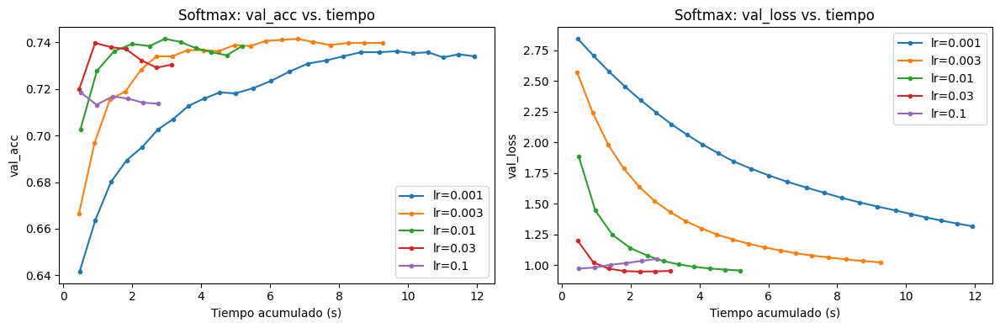

In [ ]:
LRS = [1e-3, 3e-3, 1e-2, 3e-2, 1e-1]
conv_rows, conv_hist = [], {}
for lr in LRS:
    set_seed(SEED)
    m = SoftmaxRegression(input_dim=X_tr_sm.shape[1], num_classes=NUM_CLASSES)
    h = train_model(m, make_loader(ds_tr_sm, BEST_BATCH_SIZE, shuffle=True, seed=SEED), val_loader_final,
                    optim.Adam(m.parameters(), lr=lr), epochs=MAX_EPOCHS_FINAL, patience=PATIENCE_FINAL,
                    run_name=f"lr={lr:g}", verbose=False)
    conv_hist[lr] = h
    conv_rows.append({"lr": lr, "mejor_val_acc": h["best_val_acc"], "epoca_mejor_val": h["best_epoch"],
                      "t_hasta_mejor_s": h["time_to_best_sec"], "epocas_corridas": h["epochs_run"],
                      "t_total_s": h["train_time_sec"], "s_por_epoca": np.mean(h["epoch_time_sec"]),
                      "train_acc_en_mejor": h["train_acc"][h["best_epoch"] - 1],
                      "min_val_loss": min(h["val_loss"])})
tabla_conv_lr = pd.DataFrame(conv_rows)
display(tabla_conv_lr.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for lr, h in conv_hist.items():
    t = np.cumsum(h["epoch_time_sec"])
    axes[0].plot(t, h["val_acc"], marker=".", label=f"lr={lr:g}")
    axes[1].plot(t, h["val_loss"], marker=".", label=f"lr={lr:g}")
axes[0].set_xlabel("Tiempo acumulado (s)"); axes[0].set_ylabel("val_acc"); axes[0].legend()
axes[1].set_xlabel("Tiempo acumulado (s)"); axes[1].set_ylabel("val_loss"); axes[1].legend()
axes[0].set_title("Softmax: val_acc vs. tiempo"); axes[1].set_title("Softmax: val_loss vs. tiempo")
plt.tight_layout(); plt.show()

**Análisis de tiempos**

- **Costo por época.** En la búsqueda (6.1) el tiempo por época fue de 0,20 s a 0,71 s y depende del tamaño de la entrada y de la cantidad de pasos por época. La correlación de Spearman es de +0,45 con `max_features` (p = 0,003) y de −0,73 con `batch_size` (p < 0,001). El trial más rápido fue el 12 (2000 features, batch 128) y el más lento el 29 (10000 features, batch 32). En 7.1, con la misma entrada y el mismo batch, todos los lr tardaron entre 0,45 y 0,48 s por época: el lr no cambia el costo de una época.
- **Tiempo de convergencia.** Lo que sí cambia con el lr es cuántas épocas hacen falta:

| lr | época de la mejor val | tiempo hasta la mejor val | mejor val_acc | val_loss mínima |
|---|---|---|---|---|
| 0,001 | 20 | 9,7 s | 0,7362 | 1,317 |
| 0,003 | 15 | 6,8 s | 0,7415 | 1,023 |
| 0,01 | 6 | 2,9 s | 0,7415 | 0,957 |
| 0,03 | 2 | 0,9 s | 0,7397 | 0,948 |
| 0,1 | 1 | 0,5 s | 0,7185 | 0,972 |

  Entre 0,003 y 0,03 la accuracy es prácticamente la misma (diferencias de 0,2 pp, menores que el desvío entre semillas de 0,39 pp), pero el tiempo hasta converger baja de 6,8 s a 0,9 s. Con lr = 0,1 la mejor validación llega en la primera época, con train_acc de apenas 0,62, y después empeora: el paso es tan grande que el modelo pasa de largo. Con lr = 0,001 hacen falta 20 épocas y no llega a la misma val_loss. El lr que eligió Optuna (≈0,02) está en la zona de convergencia rápida.
- **La correlación lr–época de la búsqueda engaña.** En 6.1 la correlación entre lr y época de la mejor validación dio positiva (ρ = +0,36), al revés de lo que muestra 7.1. Es un artefacto de la búsqueda: el pruner cortó 17 trials en la primera época, 14 de ellos con lr menor a 0,011, y quedaron registrados con "mejor época = 1". Por eso, para hablar de convergencia usamos el experimento controlado de 7.1 y no la tabla de trials.
- **Costo total.** De los 179,6 s que tardó la búsqueda, 103,0 s fueron vectorización y 69,0 s entrenamiento: vectorizar (TF-IDF y pasar a tensor denso) cuesta más que entrenar un modelo lineal. Aparte está el preprocesamiento, que se calcula una sola vez y se cachea: de 24 a 61 s por combinación, y el stemming es lo más lento.

### 7.2 🔧 Efecto de la normalización de la entrada

Se comparan distintas normalizaciones del TF-IDF con la mejor configuración (mismo vocabulario, `lr`, `batch_size` y early stopping), repitiendo con 3 semillas:

| Variante | Qué hace |
|---|---|
| sin normalizar | `norm=None`: TF-IDF crudo, la escala depende del largo del documento |
| L1 por documento | cada fila suma 1 |
| L2 por documento (default) | cada fila tiene norma euclídea 1 |
| L2 + `StandardScaler(with_mean=False)` | además divide cada columna por su desvío (ajustado con train) |
| L2 + `MaxAbsScaler` | además lleva cada columna a [0, 1] (ajustado con train) |

Las dos últimas preservan la esparsidad. **Importante:** se usa el mismo `lr` para todas las variantes. Como cambia la escala de la entrada, un `lr` óptimo para L2 puede ser demasiado grande o demasiado chico para otra variante; ese efecto es justamente parte de lo que se mide.

**Qué hace este código:** para cada variante vectoriza, aplica el escalador (si corresponde, ajustado solo con train), mide la escala de la entrada (norma media por documento y máximo absoluto) y entrena con 3 semillas. Reporta media ± desvío de `val_acc`, épocas y tiempo.

In [ ]:
def apply_scaler(kind, X_train, *others):
    if kind is None:
        return (X_train, *others)
    scaler = StandardScaler(with_mean=False) if kind == "std" else MaxAbsScaler()
    scaler.fit(X_train)                      # solo con train
    return (scaler.transform(X_train), *[scaler.transform(X) for X in others])


NORM_VARIANTS = [
    ("sin normalizar", None, None),
    ("L1 por documento", "l1", None),
    ("L2 por documento (default)", "l2", None),
    ("L2 + StandardScaler(with_mean=False)", "l2", "std"),
    ("L2 + MaxAbsScaler", "l2", "maxabs"),
]
N_SEEDS_NORM = 3

norm_rows = []
for name, norm, scaler_kind in NORM_VARIANTS:
    Xa, Xb, _ = vectorize_data(tr_texts_sm, val_texts_sm, BEST_NGRAM, BEST_MAX_FEATURES, BEST_MIN_DF, norm=norm)
    Xa, Xb = apply_scaler(scaler_kind, Xa, Xb)
    mean_norm = float(np.mean(np.sqrt(np.asarray(Xa.multiply(Xa).sum(axis=1)))))
    max_abs = float(abs(Xa).max())
    ds_a, ds_b = make_dataset(Xa, y_tr_sm), make_dataset(Xb, y_val_sm)
    for seed in SEEDS[:N_SEEDS_NORM]:
        set_seed(seed)
        m = SoftmaxRegression(input_dim=Xa.shape[1], num_classes=NUM_CLASSES)
        h = train_model(m, make_loader(ds_a, BEST_BATCH_SIZE, True, seed), make_loader(ds_b, BEST_BATCH_SIZE, False),
                        optim.Adam(m.parameters(), lr=BEST_LR), epochs=MAX_EPOCHS_FINAL,
                        patience=PATIENCE_FINAL, verbose=False)
        norm_rows.append({"variante": name, "seed": seed, "norma_media_doc": mean_norm, "max_abs": max_abs,
                          "val_acc": h["best_val_acc"], "epoca_mejor_val": h["best_epoch"],
                          "t_hasta_mejor_s": h["time_to_best_sec"], "min_val_loss": min(h["val_loss"])})
    del ds_a, ds_b

df_norm = pd.DataFrame(norm_rows)
tabla_norm = df_norm.groupby("variante", sort=False).agg(
    norma_media_doc=("norma_media_doc", "first"), max_abs=("max_abs", "first"),
    val_acc_media=("val_acc", "mean"), val_acc_std=("val_acc", "std"),
    epoca_mejor_media=("epoca_mejor_val", "mean"), t_hasta_mejor_media_s=("t_hasta_mejor_s", "mean"),
    min_val_loss_media=("min_val_loss", "mean"))
display(tabla_norm.round(4))
df_norm.to_csv(f"{RESULTS_DIR}/tp1_normalizacion.csv", index=False)

,norma_media_doc,max_abs,val_acc_media,val_acc_std,epoca_mejor_media,t_hasta_mejor_media_s,min_val_loss_media
variante,,,,,,,
sin normalizar,57.6821,4774.0850,0.6494,0.0042,3.0000,1.4538,4.1192
L1 por documento,0.2182,1.0000,0.7355,0.0014,16.3333,7.4883,1.0335
L2 por documento (default),0.9714,1.0000,0.7383,0.0039,2.6667,1.1990,0.9498
L2 + StandardScaler(with_mean=False),93.6049,95.1362,0.6164,0.0061,1.3333,0.6487,7.8396
L2 + MaxAbsScaler,2.2373,1.0000,0.7195,0.0037,2.0000,0.9320,1.0006


**Análisis**

| Variante | norma media por documento | máx. valor | val_acc (3 semillas) | época de la mejor val | val_loss mínima |
|---|---|---|---|---|---|
| sin normalizar | 57,7 | 4774 | 0,6494 ± 0,0042 | 3,0 | 4,12 |
| L1 por documento | 0,22 | 1,0 | 0,7355 ± 0,0014 | 16,3 | 1,03 |
| **L2 por documento (default)** | 0,97 | 1,0 | **0,7383 ± 0,0039** | 2,7 | **0,95** |
| L2 + StandardScaler(with_mean=False) | 93,6 | 95,1 | 0,6164 ± 0,0061 | 1,3 | 7,84 |
| L2 + MaxAbsScaler | 2,24 | 1,0 | 0,7195 ± 0,0037 | 2,0 | 1,00 |

- **L2 por documento**, que es lo que ya usábamos, dio la mejor val_acc y converge en menos de 3 épocas.
- **L1** da casi lo mismo (la diferencia, 0,3 pp, es menor que el desvío), pero tarda 16 épocas en vez de 3. La norma euclídea media de las filas queda en 0,22 en vez de 1, así que con el mismo lr los pasos efectivos son más chicos.
- **Sin normalizar**, la norma media es 57,7 y hay valores de hasta 4774 (frecuencias crudas de términos repetidos). La val_acc cae a 0,6494 y la val_loss mínima es 4,12, más de cuatro veces la de L2. El modelo produce logits enormes y es "demasiado seguro" de predicciones que en validación están mal. Es lo mismo que muestra la cátedra con la sigmoidea: valores grandes llevan a probabilidades extremas.
- **L2 + StandardScaler(with_mean=False)** es la peor (0,6164, val_loss mínima 7,84). Al dividir por el desvío de cada columna, los términos raros, que tienen desvío chico, pasan a valores de hasta 95 y dominan el gradiente.
- **L2 + MaxAbsScaler** queda 1,9 pp por debajo de L2 solo.

La recomendación de la cátedra de restar media y dividir por desvío apunta a que todas las features estén en escalas comparables. En TF-IDF eso ya lo resuelve la normalización por documento, y escalar además por columna empeora el resultado.

Un detalle: la norma media con L2 es 0,97 y no 1 porque cerca del 3 % de los documentos quedan vacíos después del preprocesamiento (posts muy cortos o que solo tenían citas, que se eliminaron), y su vector es cero.

### 7.3 🔧 Repeticiones con semillas (softmax)

Se reentrena la mejor softmax con las 5 semillas de `SEEDS` (inicialización y orden de batches distintos, mismo split y mismos HP), con el mismo protocolo de la sección 7. La media ± desvío estima cuánto varía el resultado solo por azar. Esto se usa en la Parte 2 para decidir si las diferencias entre modelos son reales.

**Qué hace este código:** para cada semilla entrena con early stopping, evalúa en test (el modelo ya está fijado, así que el test solo se usa para reportar) y guarda val, test y tiempos.

In [ ]:
seed_rows_softmax = []
for seed in SEEDS:
    set_seed(seed)
    m = SoftmaxRegression(input_dim=X_tr_sm.shape[1], num_classes=NUM_CLASSES)
    h = train_model(m, make_loader(ds_tr_sm, BEST_BATCH_SIZE, True, seed), val_loader_final,
                    optim.Adam(m.parameters(), lr=BEST_LR), epochs=MAX_EPOCHS_FINAL,
                    patience=PATIENCE_FINAL, verbose=False)
    test_acc_seed, _, _ = evaluate(m, test_loader_final)
    seed_rows_softmax.append({"seed": seed, "val_acc": h["best_val_acc"], "test_acc": test_acc_seed,
                              "best_epoch": h["best_epoch"], "train_time_sec": h["train_time_sec"],
                              "time_to_best_sec": h["time_to_best_sec"]})
df_seeds_softmax = pd.DataFrame(seed_rows_softmax)
display(df_seeds_softmax.round(4))
print(f"Softmax — val: {df_seeds_softmax.val_acc.mean():.4f} ± {df_seeds_softmax.val_acc.std():.4f} | "
      f"test: {df_seeds_softmax.test_acc.mean():.4f} ± {df_seeds_softmax.test_acc.std():.4f} | "
      f"tiempo: {df_seeds_softmax.train_time_sec.mean():.1f} ± {df_seeds_softmax.train_time_sec.std():.1f} s")
df_seeds_softmax.to_csv(f"{RESULTS_DIR}/tp1_softmax_seeds.csv", index=False)

,seed,val_acc,test_acc,best_epoch,train_time_sec,time_to_best_sec
0,0,0.7415,0.6695,3,3.5995,1.3838
1,1,0.7340,0.6711,2,3.3339,0.8671
2,2,0.7393,0.6668,3,3.9532,1.5796
3,3,0.7446,0.6693,3,3.5355,1.3227
4,4,0.7411,0.6689,3,3.5381,1.3364


Softmax — val: 0.7401 ± 0.0039 | test: 0.6691 ± 0.0016 | tiempo: 3.6 ± 0.2 s


## 8. Evaluación final

**Qué hace este código:** evalúa en el test oficial el modelo de la sección 7 (semilla `SEED`, pesos de la mejor época de validación) e imprime el `classification_report`. La celda siguiente grafica la matriz de confusión, y la tercera lista las confusiones más frecuentes y guarda un resumen en `results/tp1_summary.json`, que la Parte 2 lee para la comparación.

In [ ]:
test_accuracy, all_preds, all_labels = evaluate(model, test_loader_final)
print(f"Accuracy en test: {test_accuracy:.4f}\n")
print(classification_report(all_labels, all_preds, target_names=class_names))
report_softmax = classification_report(all_labels, all_preds, target_names=class_names, output_dict=True)

Accuracy en test: 0.6697

                          precision    recall  f1-score   support

             alt.atheism       0.45      0.48      0.46       319
           comp.graphics       0.60      0.66      0.62       389
 comp.os.ms-windows.misc       0.65      0.54      0.59       394
comp.sys.ibm.pc.hardware       0.60      0.63      0.62       392
   comp.sys.mac.hardware       0.67      0.64      0.66       385
          comp.windows.x       0.76      0.70      0.73       395
            misc.forsale       0.75      0.76      0.76       390
               rec.autos       0.75      0.67      0.71       396
         rec.motorcycles       0.46      0.78      0.58       398
      rec.sport.baseball       0.88      0.81      0.85       397
        rec.sport.hockey       0.89      0.87      0.88       399
               sci.crypt       0.78      0.71      0.75       396
         sci.electronics       0.63      0.57      0.60       393
                 sci.med       0.78      0.76    

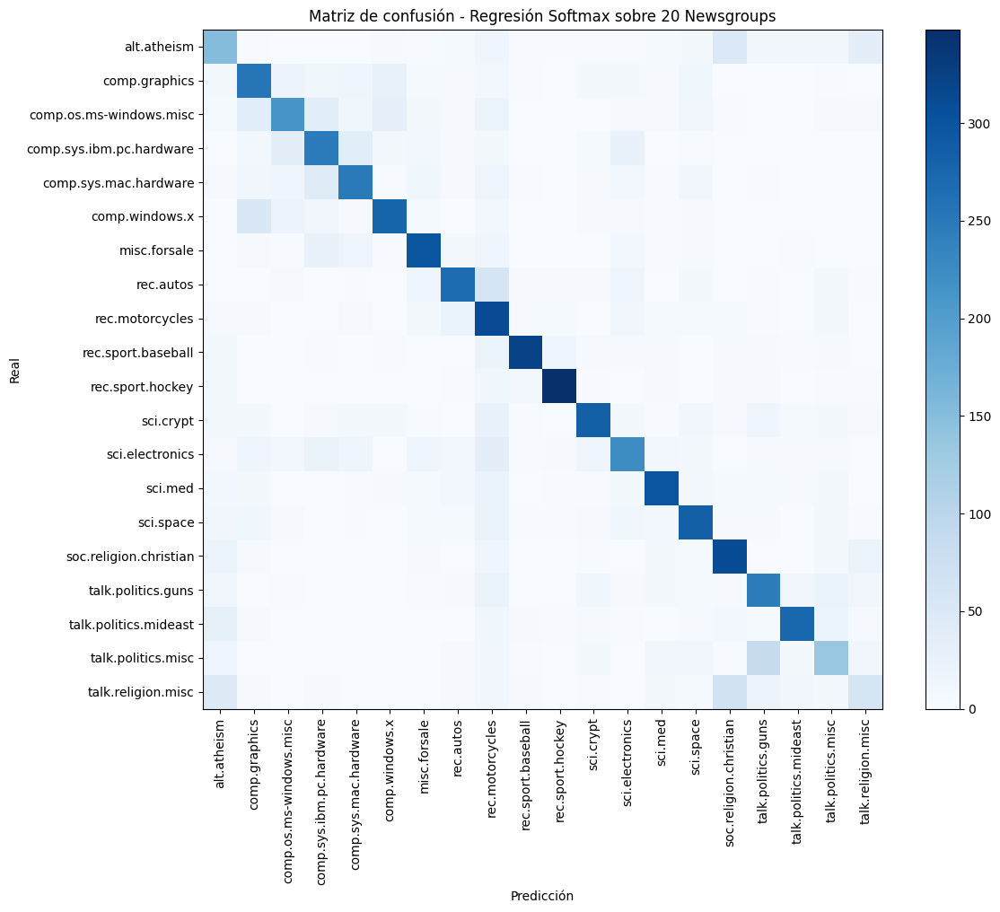

In [ ]:
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(12, 10))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names, rotation=90)
plt.yticks(range(NUM_CLASSES), class_names)
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Matriz de confusión - Regresión Softmax sobre 20 Newsgroups")
plt.tight_layout()
plt.show()


In [ ]:
# Confusiones más frecuentes (fuera de la diagonal) y f1 por clase
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)
top_conf = sorted(((cm_off[i, j], class_names[i], class_names[j])
                   for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if cm_off[i, j] > 0), reverse=True)[:10]
print("Top-10 confusiones (real -> predicho):")
for n, real, pred in top_conf:
    print(f"  {n:4d}  {real:26s} -> {pred}")

f1_softmax = pd.Series({c: report_softmax[c]["f1-score"] for c in class_names}).sort_values()
print("\nf1 por clase (de peor a mejor):")
print(f1_softmax.round(3).to_string())

tp1_summary = {
    "best_params": study.best_params,
    "best_val_search": study.best_value,
    "n_trials": N_TRIALS,
    "wall_time_search_s": wall_time_softmax,
    "final": {"val_acc": history["best_val_acc"], "test_acc": test_accuracy,
              "best_epoch": history["best_epoch"], "train_time_sec": history["train_time_sec"],
              "time_to_best_sec": history["time_to_best_sec"]},
    "per_class": {c: {k: report_softmax[c][k] for k in ["precision", "recall", "f1-score"]} for c in class_names},
}
with open(f"{RESULTS_DIR}/tp1_summary.json", "w") as f:
    json.dump(tp1_summary, f, indent=2)
print(f"\nResumen guardado en {RESULTS_DIR}/tp1_summary.json")

Top-10 confusiones (real -> predicho):
    85  talk.politics.misc         -> talk.politics.guns
    67  talk.religion.misc         -> soc.religion.christian
    58  rec.autos                  -> rec.motorcycles
    51  comp.windows.x             -> comp.graphics
    48  alt.atheism                -> soc.religion.christian
    44  talk.religion.misc         -> alt.atheism
    41  comp.sys.mac.hardware      -> comp.sys.ibm.pc.hardware
    38  comp.os.ms-windows.misc    -> comp.sys.ibm.pc.hardware
    37  comp.sys.ibm.pc.hardware   -> comp.sys.mac.hardware
    37  comp.os.ms-windows.misc    -> comp.graphics

f1 por clase (de peor a mejor):
talk.religion.misc          0.284
alt.atheism                 0.463
talk.politics.misc          0.480
rec.motorcycles             0.582
comp.os.ms-windows.misc     0.586
sci.electronics             0.599
comp.sys.ibm.pc.hardware    0.615
comp.graphics               0.625
talk.politics.guns          0.633
comp.sys.mac.hardware       0.659
rec.autos      

## 9. Preguntas de reflexión

**Sobre Regresión Softmax (teoría)**
1. ¿Por qué la regresión softmax es una generalización de la regresión logística binaria? ¿Qué pasaría si `NUM_CLASSES = 2`?
2. ¿Por qué `CrossEntropyLoss` en PyTorch no necesita que se le aplique `softmax` antes en el forward? ¿Qué pasaría si igual lo aplicaran (softmax + CrossEntropyLoss)?
3. ¿Qué tipo de frontera de decisión puede aprender un modelo de regresión softmax? ¿Qué limitación tiene frente a un problema que no es linealmente separable?
4. ¿En qué se diferencia este modelo de una red neuronal con capas ocultas? ¿En qué situación elegirían una sobre la otra?

**Sobre frameworks y herramientas**
5. ¿Qué ventajas y desventajas tiene implementar esto en PyTorch (como hicimos) comparado con usar directamente `sklearn.linear_model.LogisticRegression(multi_class="multinomial")`?
6. ¿Para qué sirvió específicamente MLflow en este TP? ¿En qué se diferencia de lo que loguea TensorBoard?
7. ¿Qué ventaja concreta les dio Optuna frente a probar combinaciones de hiperparámetros a mano?

**Sobre el experimento**
8. ¿Qué combinación de preprocesamiento (stopwords, stemming/lematización, n-gramas) encontró Optuna como mejor? ¿Tiene sentido para este dataset?
9. ¿En qué categorías del dataset se confunde más el modelo (según la matriz de confusión)? ¿Por qué creen que pasa (piensen en el contenido temático de esas categorías)?
10. ¿Cambiaría su respuesta a la pregunta anterior si usaran un modelo con capas ocultas en vez de regresión softmax? ¿Por qué sí o por qué no?


1. La softmax generaliza a la logística binaria porque hace lo mismo pero para más de dos clases. En vez de un solo score y una sigmoide, calcula un score por clase y los pasa por softmax para que las probabilidades sumen 1. Si NUM_CLASSES = 2 termina siendo lo mismo que la logística: la probabilidad queda como una sigmoide de la diferencia entre los dos scores, así que en el fondo hay un solo vector de pesos efectivo. Tendría parámetros de más, pero el modelo es equivalente.

2. Porque CrossEntropyLoss ya hace el log_softmax y el NLLLoss por dentro, y lo hace de forma numéricamente estable. Por eso el modelo tiene que devolver logits crudos. Si igual le aplicás softmax en el forward, queda aplicada dos veces. Las salidas quedan entre 0 y 1, la loss nunca llega a acercarse a 0, los gradientes se achatan y aprende más lento y peor.

3. Aprende fronteras de decisión lineales, o sea hiperplanos que dividen el espacio en regiones. La limitación es que si los datos no son linealmente separables (el ejemplo clásico es XOR) no los puede separar bien. Con TF-IDF esto pesa menos, porque en espacios de miles de dimensiones los datos suelen ser casi separables linealmente, y por eso es un baseline tan fuerte para texto.

4. La red con capas ocultas mete transformaciones no lineales (ReLU, etc.) entre capas lineales, y eso le permite aprender representaciones intermedias y fronteras no lineales. La softmax es como una red sin capas ocultas. Yo usaría softmax si tengo pocos datos, features que ya son buenas (como TF-IDF), si quiero interpretar los pesos o si necesito algo rápido o un baseline. Usaría una red con capas ocultas si hay muchos datos o relaciones no lineales, o si el modelo tiene que aprender la representación solo, como con embeddings o imágenes.

5. Con PyTorch tenés control total del entrenamiento (optimizador, loop, batches), podés usar GPU, y el código después se puede extender a una red más profunda. En contra, es bastante más código para lo mismo, hay que elegir a mano lr y épocas, y acá además se hace toarray(), que pasa la matriz esparsa a densa y gasta mucha memoria. LogisticRegression de sklearn trabaja directo con matrices esparsas, converge sola, ya trae regularización L2 y es más simple. Para un modelo lineal sobre TF-IDF sklearn es más práctico, pero PyTorch sirve para entender cómo funciona por dentro y para escalar después a modelos más complejos.

6. MLflow lo usamos para registrar los experimentos: guarda los hiperparámetros de cada corrida, las métricas y el modelo final, y después se pueden comparar corridas y reproducir la que salió mejor. TensorBoard es más para ver el entrenamiento en sí, o sea las curvas de loss y accuracy por época para detectar overfitting o problemas de convergencia. Resumiendo, TensorBoard muestra cómo evolucionó el entrenamiento y MLflow guarda qué configuración dio qué resultado.

7. Había muchísimas combinaciones posibles (solo entre las categóricas son 324, sin contar el lr continuo), y probar a mano era inviable. Optuna automatiza la búsqueda y usa un sampler que aprende de los trials anteriores, así que va probando zonas prometedoras en vez de ir a ciegas. Además permite buscar el preprocesamiento y el entrenamiento juntos, que se influyen entre sí, y deja registrado todo lo que probó.

8. Optuna encontró como mejor combinación: sacar las stopwords, stemming, solo unigramas, `max_features` = 10000, `min_df` = 2, `lr` ≈ 0,0197 y `batch_size` = 64, con accuracy de validación 0,7428. La búsqueda fue de 40 trials con sampler TPE y semilla 42, con hasta 10 épocas por trial y early stopping; el pruner cortó 18 de los 40 trials.

  Mirando la tabla de 6.1 y no solo el mejor trial, los 10 mejores usan todos unigramas y 10000 features, 9 de 10 usan stemming y casi todos batch 64, con lr entre 0,01 y 0,07. Lo que más pesa es el vocabulario: ningún trial con 2000 features pasó de 0,64, y con 5000 el mejor fue 0,7163. Tiene sentido: con pocos términos el modelo pierde palabras que distinguen entre 20 categorías, y un modelo lineal sobre TF-IDF maneja bien muchas dimensiones. Los bigramas no ayudaron (el mejor trial con bigramas dio 0,7212), probablemente porque con `max_features` fijo los bigramas desplazan unigramas útiles del vocabulario. Sacar o no las stopwords casi no cambia nada: entre los 10 mejores hay trials de los dos tipos, con diferencias de décimas de punto, porque TF-IDF ya les baja el peso a los términos que aparecen en todos los documentos. El stemming sí parece mejor que lematizar: el mejor trial con cada uno dio 0,7428 contra 0,7256, una diferencia de 1,7 pp, unas 4 veces el desvío entre semillas. Probablemente es porque agrupa más variantes de cada palabra.

  **Tiempos (6.1 y 7.1).** El costo por época depende de `max_features` y de `batch_size`, no del `lr` (en 7.1 todos los lr tardaron 0,45–0,48 s por época). El `lr` determina en cuántas épocas se llega a la mejor validación: 20 épocas (9,7 s) con lr = 0,001, 6 épocas (2,9 s) con 0,01 y 2 épocas (0,9 s) con 0,03, con prácticamente la misma accuracy. Con 0,1 llega en una época, pero a una accuracy menor, y después sobreajusta.

  Igual hay que tomar el resultado con cuidado. El desvío de val entre semillas de la mejor configuración es 0,0039 (7.3), y los 6 mejores trials están todos dentro de 0,4 pp entre sí. Más que "la configuración óptima", encontramos una zona buena del espacio.

9. Las categorías donde peor le va al modelo son talk.religion.misc (f1 0,28), alt.atheism (0,46) y talk.politics.misc (0,48). Las confusiones más marcadas en esta corrida son:

- talk.politics.misc → talk.politics.guns (85 documentos).
- talk.religion.misc → soc.religion.christian (67) y → alt.atheism (44), y alt.atheism → soc.religion.christian (48).
- rec.autos → rec.motorcycles (58). Por eso rec.motorcycles tiene precision 0,46 aunque su recall sea 0,78.
- Los comp.* entre sí: windows.x → graphics (51), mac.hardware → ibm.pc.hardware (41), ms-windows.misc → ibm.pc.hardware (38) y → graphics (37).

Creo que pasa porque el modelo es una bolsa de palabras: solo mira qué términos aparecen, sin importar el orden ni el contexto. Las categorías que se confunden comparten mucho vocabulario (dios, fe, moral en las de religión; armas, gobierno y leyes en las de política; motor, ruedas o seguro en autos y motos; términos como driver, windows o card en las de computación), así que sus vectores TF-IDF se parecen y una frontera lineal no las separa bien. En religion.misc y politics.misc influye además que son categorías que mezclan temas de las vecinas, y religion.misc es la que tiene menos ejemplos (251 en test). Al sacar headers, footers y quotes también perdimos la metadata que ayudaba a distinguirlas. En cambio, al modelo le va bien en las categorías con vocabulario muy propio, como hockey (f1 0,88) y baseball (0,85), cuyas palabras casi no aparecen en otros temas.

10. Creo que en gran parte no cambiaría. Los errores más fuertes que vimos (talk.religion.misc, alt.atheism, talk.politics.misc y los comp.* entre sí) vienen de que las categorías se parecen mucho en contenido, y eso es un problema de los datos y no solo del modelo. Categorías como religion.misc o politics.misc mezclan temas de las vecinas, y muchos posts son ambiguos incluso para una persona, así que difícilmente una capa oculta los resuelva.

# Parte 2 - MLP con búsqueda de hiperparámetros (Optuna)

Objetivo: reemplazar la regresión softmax por un **MLP** (perceptrón multicapa) sobre los mismos datos (TF-IDF de 20 Newsgroups), buscando con Optuna:

- Funciones de activación.
- Cantidad de capas ocultas (1, 2 o 3) y neuronas por capa.
- Optimizador (Adam, RMSProp, SGD) con sus propios parámetros (momentos de primer y segundo orden).
- Los hiperparámetros ya buscados en la Parte 1 (preprocesamiento, `lr`, `batch_size`).

Además, vamos a forzar una configuración que overfitee a propósito, y al final comparamos todo (performance y tiempos) contra la regresión softmax.

🔧 **Corrección (dependencia de la Parte 1):** la celda de setup siguiente verifica que estén definidas las funciones de la Parte 1 (secciones 0 a 5, que son solo definiciones y se ejecutan en segundos). Si faltan los datos o el cache de preprocesamiento, los **recrea**. Los **resultados** de la Parte 1 (tabla de trials, semillas, test) se leen desde `results/` y no desde variables en memoria, así los números de la comparación salen siempre de la corrida guardada y no de una re-ejecución distinta.

In [ ]:
# --- Setup de la Parte 2 ---
_needed = ["preprocess_text", "vectorize_data", "make_dataset", "make_loader", "split_train_val",
           "train_model", "evaluate", "set_seed", "SoftmaxRegression"]
_missing = [n for n in _needed if n not in globals()]
assert not _missing, f"Ejecutar primero las secciones 0-5 de la Parte 1 (definiciones). Faltan: {_missing}"

if "newsgroups_train" not in globals():
    newsgroups_train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
    newsgroups_test = fetch_20newsgroups(subset="test", remove=("headers", "footers", "quotes"))
    class_names = newsgroups_train.target_names
    NUM_CLASSES = len(class_names)
if "preprocessed_cache" not in globals():
    print("Recreando el cache de preprocesamiento...")
    preprocessed_cache = {
        (rsw, nrm): ([preprocess_text(t, rsw, nrm) for t in newsgroups_train.data],
                     [preprocess_text(t, rsw, nrm) for t in newsgroups_test.data])
        for rsw in [False, True] for nrm in ["none", "stem", "lemmatize"]
    }

# Resultados de la Parte 1, leídos de disco
with open(f"{RESULTS_DIR}/tp1_summary.json") as f:
    tp1_summary = json.load(f)
df_softmax_trials_disk = pd.read_csv(f"{RESULTS_DIR}/tp1_softmax_trials.csv")
df_seeds_softmax_disk = pd.read_csv(f"{RESULTS_DIR}/tp1_softmax_seeds.csv")
y_test = newsgroups_test.target
print("Parte 1 cargada: mejor val softmax =", round(tp1_summary["best_val_search"], 4),
      "| test softmax (semilla 42) =", round(tp1_summary["final"]["test_acc"], 4))

Parte 1 cargada: mejor val softmax = 0.7428 | test softmax (semilla 42) = 0.6697


## 10. Modelo: MLP

A diferencia de `SoftmaxRegression` (una sola capa lineal), acá armamos una secuencia de `Linear -> Activación` por cada capa oculta, y una última `Linear` sin activación (los logits, igual que antes — `CrossEntropyLoss` sigue esperando logits crudos).

`hidden_dims` es una lista: por ejemplo `[128, 64]` arma dos capas ocultas, la primera de 128 neuronas y la segunda de 64.

In [ ]:
ACTIVATIONS = {
    "relu": nn.ReLU,
    "tanh": nn.Tanh,
    "sigmoid": nn.Sigmoid,
    "leaky_relu": nn.LeakyReLU,
}


class MLP(nn.Module):
    def __init__(self, input_dim, hidden_dims, activation, num_classes):
        super().__init__()
        act_cls = ACTIVATIONS[activation]

        layers = []
        prev_dim = input_dim
        for h in hidden_dims:
            layers.append(nn.Linear(prev_dim, h))
            layers.append(act_cls())
            prev_dim = h
        layers.append(nn.Linear(prev_dim, num_classes))  # logits, sin activación

        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


**Qué hace este código:** `MLP` arma la red a partir de la lista `hidden_dims`. Por cada capa oculta agrega `Linear → activación`, y al final una `Linear` de salida sin activación, que devuelve los logits. La activación se elige por nombre desde el diccionario `ACTIVATIONS`.

In [ ]:
# Sanity check
_dummy = torch.randn(4, 50)
_model_check = MLP(input_dim=50, hidden_dims=[32, 16], activation="relu", num_classes=20)
_out = _model_check(_dummy)
assert _out.shape == (4, 20), "Revisá MLP"
print("Shape de salida OK:", _out.shape)
print(_model_check)


Shape de salida OK: torch.Size([4, 20])
MLP(
  (net): Sequential(
    (0): Linear(in_features=50, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=20, bias=True)
  )
)


## 11. Entrenamiento genérico (con soporte de *pruning*)

🔧 Se usa la misma `train_model` de la sección 5, que ya mide tiempos por época, aplica early stopping y soporta pruning. Así la softmax y el MLP se entrenan exactamente con el mismo loop.

**Qué hace este código:** define dos helpers para el optimizador.

- `suggest_optimizer(trial)` muestrea el optimizador y sus hiperparámetros. 🔧 **Corrección:** los coeficientes de los momentos se muestrean como `1-β` **en escala logarítmica**. Lo que importa de β es la "memoria" del promedio móvil, que es aproximadamente $1/(1-β)$ pasos: β₂ = 0.99 promedia unos 100 pasos, 0.999 unos 1000 y 0.9999 unos 10 000. En escala lineal, casi todo el rango [0.9, 0.999] cae en memorias cortas y la zona de 0.999 (el default de Adam) casi no se explora. Rangos: β₁ ∈ [0.7, 0.99], β₂ ∈ [0.9, 0.9999], α de RMSProp ∈ [0.8, 0.999] y momentum ∈ [0, 0.99] (con `1-momentum` = 1 se obtiene momentum 0).
- `build_optimizer` arma el optimizador de PyTorch a partir del nombre y de esos valores (o de `best_params`).

In [ ]:
def suggest_optimizer(trial):
    name = trial.suggest_categorical("optimizer", ["adam", "rmsprop", "sgd"])
    if name == "adam":
        p = {"one_minus_beta1": trial.suggest_float("adam_one_minus_beta1", 1e-2, 3e-1, log=True),
             "one_minus_beta2": trial.suggest_float("adam_one_minus_beta2", 1e-4, 1e-1, log=True)}
    elif name == "rmsprop":
        p = {"one_minus_alpha": trial.suggest_float("rmsprop_one_minus_alpha", 1e-3, 2e-1, log=True),
             "one_minus_momentum": trial.suggest_float("rmsprop_one_minus_momentum", 1e-2, 1.0, log=True)}
    else:
        p = {"one_minus_momentum": trial.suggest_float("sgd_one_minus_momentum", 1e-2, 1.0, log=True)}
    return name, p


def optimizer_params_from_best(bp):
    # Reconstruye (nombre, params) a partir de study.best_params
    name = bp["optimizer"]
    prefix = f"{name}_"
    return name, {k[len(prefix):]: v for k, v in bp.items() if k.startswith(prefix)}


def build_optimizer(name, p, params, lr):
    if name == "adam":
        return optim.Adam(params, lr=lr, betas=(1 - p["one_minus_beta1"], 1 - p["one_minus_beta2"]))
    if name == "rmsprop":
        return optim.RMSprop(params, lr=lr, alpha=1 - p["one_minus_alpha"], momentum=1 - p["one_minus_momentum"])
    return optim.SGD(params, lr=lr, momentum=1 - p["one_minus_momentum"])

## 12. Búsqueda de hiperparámetros para el MLP

El espacio de búsqueda incluye:

**Preprocesamiento (igual que en la Parte 1):** `remove_stopwords`, `normalization`, `ngram_range`, `max_features`, `min_df`.

**Arquitectura:** `n_layers` (1 a 3), y para cada capa `n_units_l{i}` (cantidad de neuronas), más la `activation` (compartida entre todas las capas del trial, para no explotar el espacio de búsqueda).

**Optimizador y sus propios parámetros** (ver sección 11): Adam (β₁, β₂), RMSProp (α, momentum) y SGD (momentum), todos con `1-β` en escala log.

**Entrenamiento:** `lr` (escala log) y `batch_size`.

🔧 **Correcciones:**
- **Mismo presupuesto que la softmax:** `N_TRIALS` trials de hasta `EPOCHS_SEARCH` épocas con el mismo early stopping, el mismo split de validación y `TPESampler(seed=SEED)`.
- **Pruning medido, no estimado:** se corren **dos** estudios con la misma semilla, uno con `MedianPruner` y otro sin pruning (`NopPruner`), y se cronometran los dos. El estudio **sin pruning** tiene los 40 trials completos, y el estudio con pruning sirve para medir cuánto tiempo ahorra y si llega a una solución igual de buena. La búsqueda de la softmax (Parte 1) se creó sin indicar `pruner`, así que usó el `MedianPruner` por defecto de Optuna: la comparación con la misma regla de poda es softmax contra MLP con pruning. De todas formas, la comparación que decide es la de las 5 semillas (14.2), que no depende de la búsqueda.
- **Tiempos separados:** cada trial guarda el tiempo de vectorización y el de entrenamiento por separado (`duration` de Optuna incluye ambos).

**Qué hace este código:** `objective_mlp` muestrea todos los HP, vectoriza (cronometrado aparte), arma el MLP y el optimizador, y entrena con `train_model` pasándole el `trial`. Con `NopPruner`, `should_prune()` siempre da `False`, así que el mismo `objective` sirve para los dos estudios. `run_mlp_study` crea el estudio con la semilla fija y mide el tiempo de pared.

In [ ]:
def objective_mlp(trial):
    # --- Preprocesamiento (mismo espacio que en la Parte 1) ---
    remove_stopwords = trial.suggest_categorical("remove_stopwords", [False, True])
    normalization = trial.suggest_categorical("normalization", ["none", "stem", "lemmatize"])
    ngram_range = trial.suggest_categorical("ngram_range", ["1gram", "1_2gram"])
    ngram_range_tuple = (1, 1) if ngram_range == "1gram" else (1, 2)
    max_features = trial.suggest_categorical("max_features", [2000, 5000, 10000])
    min_df = trial.suggest_categorical("min_df", [1, 2, 5])

    # --- Arquitectura ---
    n_layers = trial.suggest_int("n_layers", 1, 3)
    hidden_dims = [trial.suggest_categorical(f"n_units_l{i}", [32, 64, 128, 256]) for i in range(n_layers)]
    activation = trial.suggest_categorical("activation", ["relu", "tanh", "sigmoid", "leaky_relu"])

    # --- Entrenamiento y optimizador ---
    lr = trial.suggest_float("lr", 1e-4, 1e-1, log=True)
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128])
    opt_name, opt_params = suggest_optimizer(trial)

    train_texts, _ = preprocessed_cache[(remove_stopwords, normalization)]
    tr_texts, val_texts, tr_labels, val_labels = split_train_val(train_texts, newsgroups_train.target)

    t0 = time.perf_counter()
    X_tr, X_val, _ = vectorize_data(tr_texts, val_texts, ngram_range_tuple, max_features, min_df)
    ds_tr, ds_val = make_dataset(X_tr, tr_labels), make_dataset(X_val, val_labels)
    trial.set_user_attr("vectorize_time_sec", time.perf_counter() - t0)

    set_seed(SEED)
    model = MLP(input_dim=X_tr.shape[1], hidden_dims=hidden_dims, activation=activation, num_classes=NUM_CLASSES)
    optimizer = build_optimizer(opt_name, opt_params, model.parameters(), lr)
    trial.set_user_attr("n_params", sum(p.numel() for p in model.parameters()))

    history = train_model(model, make_loader(ds_tr, batch_size, True), make_loader(ds_val, batch_size, False),
                          optimizer, epochs=EPOCHS_SEARCH, patience=PATIENCE_SEARCH,
                          run_name=f"mlp_trial_{trial.number}", trial=trial, verbose=False)
    return history["best_val_acc"]


def run_mlp_study(pruner, name):
    study_ = optuna.create_study(direction="maximize", study_name=name, pruner=pruner,
                                 sampler=optuna.samplers.TPESampler(seed=SEED))
    t0 = time.perf_counter()
    study_.optimize(objective_mlp, n_trials=N_TRIALS)
    return study_, time.perf_counter() - t0


study_mlp, wall_time_mlp = run_mlp_study(optuna.pruners.NopPruner(), "mlp_sin_pruning")
print("Sin pruning — mejor val:", round(study_mlp.best_value, 4), "| tiempo:", round(wall_time_mlp, 1), "s")
print("Mejores hiperparámetros (MLP):", study_mlp.best_params)

study_mlp_pruning, wall_time_mlp_pruning = run_mlp_study(
    optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=2), "mlp_con_pruning")
print("Con pruning — mejor val:", round(study_mlp_pruning.best_value, 4),
      "| tiempo:", round(wall_time_mlp_pruning, 1), "s")

df_mlp_trials = study_mlp.trials_dataframe()
df_mlp_pruning_trials = study_mlp_pruning.trials_dataframe()
df_mlp_trials.to_csv(f"{RESULTS_DIR}/tp2_mlp_trials.csv", index=False)
df_mlp_pruning_trials.to_csv(f"{RESULTS_DIR}/tp2_mlp_pruning_trials.csv", index=False)

[I 2026-11-19 17:40:47,356] A new study created in memory with name: mlp_sin_pruning
[I 2026-11-19 17:40:51,237] Trial 0 finished with value: 0.05302695536897923 and parameters: {'remove_stopwords': True, 'normalization': 'none', 'ngram_range': '1gram', 'max_features': 2000, 'min_df': 2, 'n_layers': 1, 'n_units_l0': 256, 'activation': 'sigmoid', 'lr': 0.0007523742884534858, 'batch_size': 128, 'optimizer': 'sgd', 'sgd_one_minus_momentum': 0.012385137298860933}. Best is trial 0 with value: 0.05302695536897923.
[I 2026-11-19 17:40:56,126] Trial 1 finished with value: 0.5422006186478127 and parameters: {'remove_stopwords': False, 'normalization': 'lemmatize', 'ngram_range': '1gram', 'max_features': 5000, 'min_df': 2, 'n_layers': 3, 'n_units_l0': 64, 'n_units_l1': 128, 'n_units_l2': 32, 'activation': 'leaky_relu', 'lr': 0.001465655388622534, 'batch_size': 64, 'optimizer': 'rmsprop', 'rmsprop_one_minus_alpha': 0.07012604000905365, 'rmsprop_one_minus_momentum': 0.01409617514981587}. Best is t

Sin pruning — mejor val: 0.7517 | tiempo: 258.1 s
Mejores hiperparámetros (MLP): {'remove_stopwords': False, 'normalization': 'stem', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 1, 'n_layers': 1, 'n_units_l0': 256, 'activation': 'tanh', 'lr': 0.0006950121809596989, 'batch_size': 64, 'optimizer': 'adam', 'adam_one_minus_beta1': 0.01612890255517946, 'adam_one_minus_beta2': 0.009754791258426364}


[I 2026-11-19 17:45:09,249] Trial 0 finished with value: 0.05302695536897923 and parameters: {'remove_stopwords': True, 'normalization': 'none', 'ngram_range': '1gram', 'max_features': 2000, 'min_df': 2, 'n_layers': 1, 'n_units_l0': 256, 'activation': 'sigmoid', 'lr': 0.0007523742884534858, 'batch_size': 128, 'optimizer': 'sgd', 'sgd_one_minus_momentum': 0.012385137298860933}. Best is trial 0 with value: 0.05302695536897923.
[I 2026-11-19 17:45:13,930] Trial 1 finished with value: 0.5422006186478127 and parameters: {'remove_stopwords': False, 'normalization': 'lemmatize', 'ngram_range': '1gram', 'max_features': 5000, 'min_df': 2, 'n_layers': 3, 'n_units_l0': 64, 'n_units_l1': 128, 'n_units_l2': 32, 'activation': 'leaky_relu', 'lr': 0.001465655388622534, 'batch_size': 64, 'optimizer': 'rmsprop', 'rmsprop_one_minus_alpha': 0.07012604000905365, 'rmsprop_one_minus_momentum': 0.01409617514981587}. Best is trial 1 with value: 0.5422006186478127.
[I 2026-11-19 17:45:21,538] Trial 2 finished w

Con pruning — mejor val: 0.7517 | tiempo: 231.5 s


## 13. Experimento de overfitting — barrido de capacidad

🔧 **Corrección:** antes el overfitting se mostraba con una sola arquitectura (3×1024). Ahora se barre la **capacidad** (de 1×64 a 3×1024 neuronas) con todo lo demás fijo: el mejor preprocesamiento del MLP, ReLU, Adam con lr = 1e-3, batch 64, `EPOCHS_OVERFIT = 30` épocas **sin** early stopping ni regularización y la misma semilla. Para cada arquitectura se mide la brecha train−val al final, el mínimo de `val_loss` y cuánto sube después.

**Qué hace este código:** vectoriza una sola vez con el preprocesamiento de `study_mlp.best_params`, construye los datasets `ds_tr_of` y `ds_val_of` (que se reutilizan en la Parte 3) y entrena cada arquitectura. `patience=None` desactiva el early stopping. Como `train_model` restaura los pesos de la mejor época, las métricas "finales" se toman del historial y no del modelo.

In [ ]:
best_mlp = study_mlp.best_params
OF_REMOVE_SW = best_mlp["remove_stopwords"]
OF_NORM = best_mlp["normalization"]
OF_NGRAM = (1, 1) if best_mlp["ngram_range"] == "1gram" else (1, 2)
OF_MAX_FEATURES = best_mlp["max_features"]
OF_MIN_DF = best_mlp["min_df"]
EPOCHS_OVERFIT = 30
BATCH_OF = 64

train_texts_of, test_texts_of = preprocessed_cache[(OF_REMOVE_SW, OF_NORM)]
tr_texts_of, val_texts_of, tr_labels_of, val_labels_of = split_train_val(train_texts_of, newsgroups_train.target)
X_tr_of, X_val_of, vectorizer_of = vectorize_data(tr_texts_of, val_texts_of, OF_NGRAM, OF_MAX_FEATURES, OF_MIN_DF)
X_test_of = vectorizer_of.transform(test_texts_of)
ds_tr_of, ds_val_of, ds_test_of = (make_dataset(X_tr_of, tr_labels_of), make_dataset(X_val_of, val_labels_of),
                                   make_dataset(X_test_of, y_test))
val_loader_of = make_loader(ds_val_of, BATCH_OF, shuffle=False)

CAPACITY_ARCHS = {"1x64": [64], "1x256": [256], "1x1024": [1024], "2x1024": [1024, 1024], "3x1024": [1024, 1024, 1024]}
capacity_rows, capacity_hist = [], {}
writer_of = SummaryWriter(log_dir="runs/mlp_overfit")
for name, dims in CAPACITY_ARCHS.items():
    set_seed(SEED)
    m = MLP(input_dim=X_tr_of.shape[1], hidden_dims=dims, activation="relu", num_classes=NUM_CLASSES)
    h = train_model(m, make_loader(ds_tr_of, BATCH_OF, True), val_loader_of, optim.Adam(m.parameters(), lr=1e-3),
                    epochs=EPOCHS_OVERFIT, patience=None, run_name=f"overfit_{name}", verbose=False,
                    writer=writer_of if name == "3x1024" else None)
    capacity_hist[name] = h
    i_min = int(np.argmin(h["val_loss"]))
    capacity_rows.append({
        "arquitectura": name, "n_params": sum(p.numel() for p in m.parameters()),
        "train_acc_final": h["train_acc"][-1], "val_acc_final": h["val_acc"][-1],
        "mejor_val_acc": h["best_val_acc"], "epoca_mejor_val": h["best_epoch"],
        "brecha_acc_final": h["train_acc"][-1] - h["val_acc"][-1],
        "min_val_loss": h["val_loss"][i_min], "epoca_min_val_loss": i_min + 1,
        "val_loss_final": h["val_loss"][-1], "suba_val_loss": h["val_loss"][-1] - h["val_loss"][i_min],
        "s_por_epoca": np.mean(h["epoch_time_sec"]), "t_total_s": h["train_time_sec"],
    })
    print(f"{name}: listo ({h['train_time_sec']:.1f} s)")
writer_of.close()
overfit_history = capacity_hist["3x1024"]
tabla_capacidad = pd.DataFrame(capacity_rows)
display(tabla_capacidad.round(4))
tabla_capacidad.to_csv(f"{RESULTS_DIR}/tp2_capacidad.csv", index=False)

1x64: listo (15.3 s)
1x256: listo (17.1 s)
1x1024: listo (27.7 s)
2x1024: listo (30.0 s)
3x1024: listo (32.5 s)


,arquitectura,n_params,train_acc_final,val_acc_final,mejor_val_acc,epoca_mejor_val,brecha_acc_final,min_val_loss,epoca_min_val_loss,val_loss_final,suba_val_loss,s_por_epoca,t_total_s
0,1x64,641364,0.9746,0.7256,0.7499,9,0.2490,0.8768,10,1.0256,0.1488,0.5112,15.3417
1,1x256,2565396,0.9746,0.7234,0.7472,4,0.2512,0.8727,5,1.1384,0.2657,0.5694,17.0859
2,1x1024,10261524,0.9743,0.7181,0.7424,2,0.2562,0.8803,3,1.2685,0.3881,0.9228,27.6859
3,2x1024,11311124,0.9745,0.6969,0.7159,26,0.2776,1.0242,2,1.8384,0.8141,0.9999,29.9996
4,3x1024,12360724,0.9748,0.6597,0.6695,10,0.3151,1.1489,2,3.2519,2.1030,1.0813,32.4881


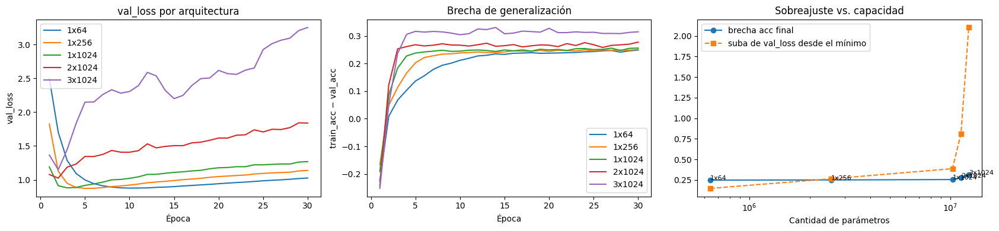

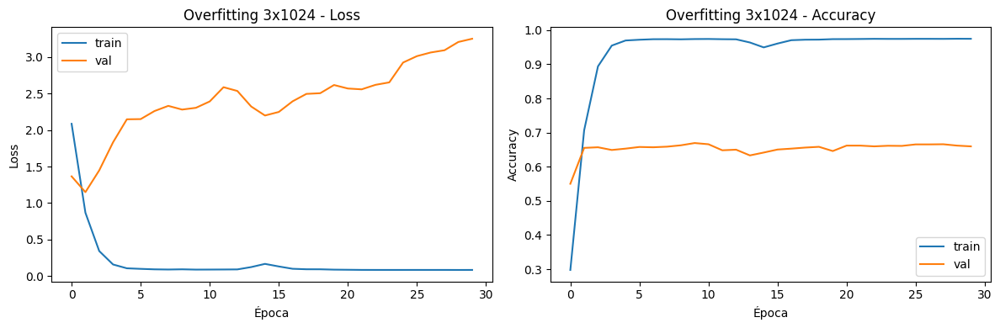

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for name, h in capacity_hist.items():
    axes[0].plot(range(1, len(h["val_loss"]) + 1), h["val_loss"], label=name)
    axes[1].plot(range(1, len(h["val_acc"]) + 1), np.array(h["train_acc"]) - np.array(h["val_acc"]), label=name)
axes[0].set_xlabel("Época"); axes[0].set_ylabel("val_loss"); axes[0].set_title("val_loss por arquitectura"); axes[0].legend()
axes[1].set_xlabel("Época"); axes[1].set_ylabel("train_acc − val_acc"); axes[1].set_title("Brecha de generalización"); axes[1].legend()
axes[2].plot(tabla_capacidad["n_params"], tabla_capacidad["brecha_acc_final"], "o-", label="brecha acc final")
axes[2].plot(tabla_capacidad["n_params"], tabla_capacidad["suba_val_loss"], "s--", label="suba de val_loss desde el mínimo")
for _, r in tabla_capacidad.iterrows():
    axes[2].annotate(r["arquitectura"], (r["n_params"], r["brecha_acc_final"]), fontsize=8)
axes[2].set_xscale("log"); axes[2].set_xlabel("Cantidad de parámetros"); axes[2].set_title("Sobreajuste vs. capacidad"); axes[2].legend()
plt.tight_layout(); plt.show()

# Detalle del caso más grande (3x1024)
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(overfit_history["train_loss"], label="train"); plt.plot(overfit_history["val_loss"], label="val")
plt.xlabel("Época"); plt.ylabel("Loss"); plt.title("Overfitting 3x1024 - Loss"); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(overfit_history["train_acc"], label="train"); plt.plot(overfit_history["val_acc"], label="val")
plt.xlabel("Época"); plt.ylabel("Accuracy"); plt.title("Overfitting 3x1024 - Accuracy"); plt.legend()
plt.tight_layout(); plt.show()

**Qué se ve en estos gráficos:** en todas las arquitecturas `train_loss` sigue bajando, mientras que `val_loss` llega a un mínimo y después sube. Esa separación creciente entre las curvas de train y validación es la firma clásica de overfitting: el modelo deja de aprender patrones generales y empieza a memorizar ejemplos puntuales del train set.

| Arquitectura | parámetros | mejor val_acc (época) | val_acc final | brecha final | val_loss mínima → final | s/época |
|---|---|---|---|---|---|---|
| 1×64 | 641.364 | 0,7499 (9) | 0,7256 | 0,249 | 0,877 → 1,026 | 0,51 |
| 1×256 | 2.565.396 | 0,7472 (4) | 0,7234 | 0,251 | 0,873 → 1,138 | 0,57 |
| 1×1024 | 10.261.524 | 0,7424 (2) | 0,7181 | 0,256 | 0,880 → 1,269 | 0,92 |
| 2×1024 | 11.311.124 | 0,7159 (26) | 0,6969 | 0,278 | 1,024 → 1,838 | 1,00 |
| 3×1024 | 12.360.724 | 0,6695 (10) | 0,6597 | 0,315 | 1,149 → 3,252 | 1,08 |

- **El sobreajuste crece con la capacidad.** La brecha final pasa de 0,249 a 0,315, y sobre todo la val_loss: en 1×64 sube 0,15 desde su mínimo y en 3×1024 sube 2,10 (de 1,15 a 3,25). Además, cuanto más grande la red, antes llega al mínimo de val_loss: en la época 10 con 1×64 y en la época 2 con 2 y 3 capas de 1024.
- **La capacidad extra empeora la generalización.** A diferencia de lo que concluimos en la entrega anterior, la mejor val_acc no se mantiene: baja de 0,7499 con 1×64 a 0,6695 con 3×1024. Es lo mismo que muestra la cátedra en el ejemplo de unidades en la capa oculta: a medida que aumenta la cantidad de unidades, aumenta el overfitting y la accuracy en validación cae.
- **Todas llegan al mismo techo en train.** La train_acc final es ≈0,975 en todas las arquitecturas. Creo que ese techo viene de los documentos que quedan vacíos después del preprocesamiento (cerca del 3 %, ver 7.2), que ningún modelo puede clasificar.

## 14. Entrenamiento final del mejor MLP

🔧 **Corrección:** igual que en la Parte 1, el modelo final **ya no usa el test como validación**. Se entrena con el 80 % de train, con early stopping sobre la validación (`PATIENCE_FINAL`) y restauración de la mejor época. El test se usa una sola vez al final. Antes se corrían 20 épocas fijas aunque `val_acc` dejaba de mejorar alrededor de la época 15; ahora el corte lo decide la validación.

**Qué hace este código:** toma `study_mlp.best_params`, re-vectoriza con ese preprocesamiento, reconstruye arquitectura y optimizador con los helpers de la sección 11, entrena con early stopping, loguea a MLflow y muestra la tabla época vs. segundos.

In [ ]:
mlflow.end_run()
BEST_NGRAM_MLP = (1, 1) if best_mlp["ngram_range"] == "1gram" else (1, 2)
BEST_HIDDEN_DIMS_MLP = [best_mlp[f"n_units_l{i}"] for i in range(best_mlp["n_layers"])]
BEST_OPT_MLP = optimizer_params_from_best(best_mlp)

train_texts_mlp, test_texts_mlp = preprocessed_cache[(best_mlp["remove_stopwords"], best_mlp["normalization"])]
tr_texts_mlp, val_texts_mlp, y_tr_mlp, y_val_mlp = split_train_val(train_texts_mlp, newsgroups_train.target)
X_tr_mlp, X_val_mlp, vectorizer_final_mlp = vectorize_data(tr_texts_mlp, val_texts_mlp, BEST_NGRAM_MLP,
                                                           best_mlp["max_features"], best_mlp["min_df"])
X_test_mlp = vectorizer_final_mlp.transform(test_texts_mlp)
ds_tr_mlp, ds_val_mlp, ds_test_mlp = (make_dataset(X_tr_mlp, y_tr_mlp), make_dataset(X_val_mlp, y_val_mlp),
                                      make_dataset(X_test_mlp, y_test))
BS_MLP = best_mlp["batch_size"]
val_loader_final_mlp = make_loader(ds_val_mlp, BS_MLP, False)
test_loader_final_mlp = make_loader(ds_test_mlp, BS_MLP, False)


def new_best_mlp(activation=None, seed=SEED):
    set_seed(seed)
    m = MLP(input_dim=X_tr_mlp.shape[1], hidden_dims=BEST_HIDDEN_DIMS_MLP,
            activation=activation or best_mlp["activation"], num_classes=NUM_CLASSES)
    return m, build_optimizer(*BEST_OPT_MLP, m.parameters(), best_mlp["lr"])


final_mlp_model, final_optimizer_mlp = new_best_mlp()
writer_mlp = SummaryWriter(log_dir="runs/mlp_final")
mlflow.set_experiment("mlp_20newsgroups")
with mlflow.start_run(run_name="mlp_final"):
    mlflow.log_params({**best_mlp, "hidden_dims": str(BEST_HIDDEN_DIMS_MLP), "max_epochs": MAX_EPOCHS_FINAL,
                       "patience": PATIENCE_FINAL, "seed": SEED})
    history_final_mlp = train_model(final_mlp_model, make_loader(ds_tr_mlp, BS_MLP, True), val_loader_final_mlp,
                                    final_optimizer_mlp, epochs=MAX_EPOCHS_FINAL, patience=PATIENCE_FINAL,
                                    writer=writer_mlp, run_name="mlp_final", log_mlflow=True)
    mlflow.log_metrics({"best_val_acc": history_final_mlp["best_val_acc"],
                        "best_epoch": history_final_mlp["best_epoch"],
                        "train_time_sec": history_final_mlp["train_time_sec"]})
    sample_input_mlp, _ = next(iter(test_loader_final_mlp))
    mlflow.pytorch.log_model(final_mlp_model, "model", input_example=sample_input_mlp.to(device),
                             serialization_format="pickle")
writer_mlp.close()

tabla_epocas_mlp = pd.DataFrame({
    "época": np.arange(1, history_final_mlp["epochs_run"] + 1),
    "seg_época": history_final_mlp["epoch_time_sec"], "seg_acumulados": np.cumsum(history_final_mlp["epoch_time_sec"]),
    "train_acc": history_final_mlp["train_acc"], "val_acc": history_final_mlp["val_acc"],
    "val_loss": history_final_mlp["val_loss"]})
display(tabla_epocas_mlp.round(4))
print(f"Mejor val_acc = {history_final_mlp['best_val_acc']:.4f} en la época {history_final_mlp['best_epoch']} "
      f"({history_final_mlp['time_to_best_sec']:.1f} s); corte en la época {history_final_mlp['epochs_run']}.")

2026/11/19 17:51:09 INFO mlflow.tracking.fluent: Experiment with name 'mlp_20newsgroups' does not exist. Creating a new experiment.


[mlp_final] Epoch 1/50 - train_loss: 2.7286 train_acc: 0.4278 - val_loss: 2.2847 val_acc: 0.6191 - 0.56s
[mlp_final] Epoch 2/50 - train_loss: 1.7044 train_acc: 0.7417 - val_loss: 1.4127 val_acc: 0.7057 - 0.57s
[mlp_final] Epoch 3/50 - train_loss: 0.9641 train_acc: 0.8192 - val_loss: 1.0475 val_acc: 0.7274 - 0.55s
[mlp_final] Epoch 4/50 - train_loss: 0.6182 train_acc: 0.8665 - val_loss: 0.9198 val_acc: 0.7415 - 0.56s
[mlp_final] Epoch 5/50 - train_loss: 0.4281 train_acc: 0.9084 - val_loss: 0.8693 val_acc: 0.7446 - 0.55s
[mlp_final] Epoch 6/50 - train_loss: 0.3043 train_acc: 0.9359 - val_loss: 0.8565 val_acc: 0.7517 - 0.56s
[mlp_final] Epoch 7/50 - train_loss: 0.2205 train_acc: 0.9560 - val_loss: 0.8612 val_acc: 0.7450 - 0.57s
[mlp_final] Epoch 8/50 - train_loss: 0.1658 train_acc: 0.9655 - val_loss: 0.8869 val_acc: 0.7419 - 0.57s
[mlp_final] Epoch 9/50 - train_loss: 0.1319 train_acc: 0.9713 - val_loss: 0.9133 val_acc: 0.7424 - 0.57s
[mlp_final] Epoch 10/50 - train_loss: 0.1115 train_acc:

2026/11/19 17:51:15 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/19 17:51:16 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.
2026/11/19 17:51:16 WARNING mlflow.utils.requirements_utils: Found torch version (2.14.1+cu130) contains a local version label (+cu130). MLflow logged a pip requirement for this package as 'torch==2.14.1' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.


[mlp_final] Epoch 11/50 - train_loss: 0.0992 train_acc: 0.9739 - val_loss: 0.9944 val_acc: 0.7327 - 0.57s
[mlp_final] Early stopping en la época 11 (mejor val_acc=0.7517 en la época 6)


2026/11/19 17:51:22 WARNING mlflow.utils.requirements_utils: Found torch version (2.14.1+cu130) contains a local version label (+cu130). MLflow logged a pip requirement for this package as 'torch==2.14.1' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.


,época,seg_época,seg_acumulados,train_acc,val_acc,val_loss
0,1,0.5563,0.5563,0.4278,0.6191,2.2847
1,2,0.5688,1.1251,0.7417,0.7057,1.4127
2,3,0.5544,1.6795,0.8192,0.7274,1.0475
3,4,0.5598,2.2393,0.8665,0.7415,0.9198
4,5,0.5518,2.7911,0.9084,0.7446,0.8693
5,6,0.5626,3.3537,0.9359,0.7517,0.8565
6,7,0.5685,3.9222,0.9560,0.7450,0.8612
7,8,0.5728,4.4950,0.9655,0.7419,0.8869
8,9,0.5651,5.0602,0.9713,0.7424,0.9133
9,10,0.5584,5.6186,0.9724,0.7371,0.9529


Mejor val_acc = 0.7517 en la época 6 (3.4 s); corte en la época 11.


In [ ]:
test_accuracy_mlp, all_preds_mlp, all_labels_mlp = evaluate(final_mlp_model, test_loader_final_mlp)
print(f"Accuracy en test (MLP): {test_accuracy_mlp:.4f}\n")
print(classification_report(all_labels_mlp, all_preds_mlp, target_names=class_names))
report_mlp = classification_report(all_labels_mlp, all_preds_mlp, target_names=class_names, output_dict=True)

Accuracy en test (MLP): 0.6883

                          precision    recall  f1-score   support

             alt.atheism       0.51      0.50      0.51       319
           comp.graphics       0.63      0.66      0.65       389
 comp.os.ms-windows.misc       0.65      0.59      0.62       394
comp.sys.ibm.pc.hardware       0.66      0.64      0.65       392
   comp.sys.mac.hardware       0.70      0.71      0.70       385
          comp.windows.x       0.80      0.67      0.73       395
            misc.forsale       0.79      0.79      0.79       390
               rec.autos       0.50      0.76      0.60       396
         rec.motorcycles       0.75      0.74      0.74       398
      rec.sport.baseball       0.88      0.80      0.84       397
        rec.sport.hockey       0.89      0.89      0.89       399
               sci.crypt       0.81      0.70      0.75       396
         sci.electronics       0.58      0.61      0.60       393
                 sci.med       0.80      0.

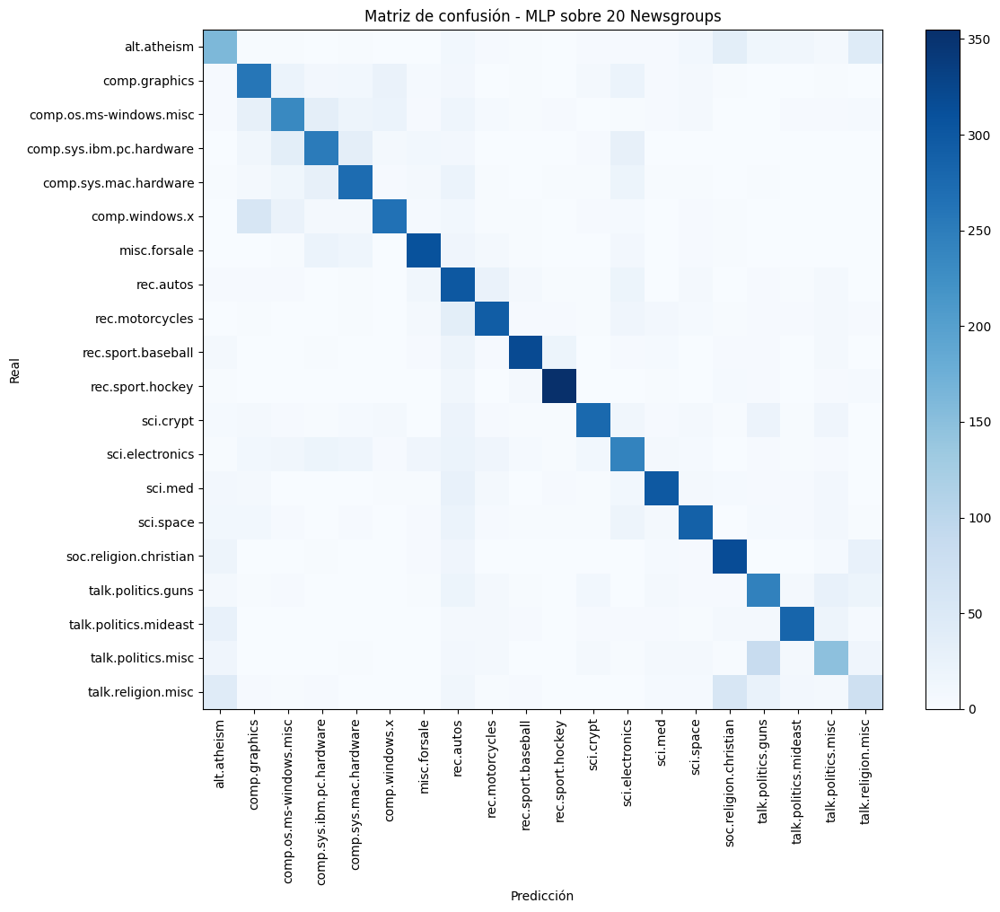

In [ ]:
cm_mlp = confusion_matrix(all_labels_mlp, all_preds_mlp)
plt.figure(figsize=(12, 10))
plt.imshow(cm_mlp, cmap="Blues")
plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names, rotation=90)
plt.yticks(range(NUM_CLASSES), class_names)
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Matriz de confusión - MLP sobre 20 Newsgroups")
plt.tight_layout()
plt.show()


### 14.1 🔧 Control de activación: ¿la diferencia se explica por la activación?

En la entrega original se atribuía el resultado a la saturación de sigmoid sin ponerlo a prueba. Acá se fija **todo** lo demás (preprocesamiento, arquitectura, optimizador, lr, batch, split) en el mejor trial y se cambia **solo** la activación, con 5 semillas. Se prueban dos presupuestos:

- **Corto:** `EPOCHS_SEARCH` épocas con early stopping, el mismo que tuvo cada trial de Optuna. Si una activación pierde acá pero no con el presupuesto largo, el problema era de velocidad de convergencia (saturación y gradientes chicos) y no de capacidad final.
- **Largo:** el protocolo final (`MAX_EPOCHS_FINAL` con early stopping).

**Qué hace este código:** para cada activación y semilla reconstruye el mejor MLP (`new_best_mlp`) cambiando solo la activación, entrena con los dos presupuestos y registra la mejor `val_acc` y la época en que se alcanza. Después resume media ± desvío y compara cada activación contra ReLU con un test de Welch.

In [ ]:
act_rows = []
for act in ["relu", "leaky_relu", "tanh", "sigmoid"]:
    for budget, (ep, pat) in {"corto": (EPOCHS_SEARCH, PATIENCE_SEARCH),
                              "largo": (MAX_EPOCHS_FINAL, PATIENCE_FINAL)}.items():
        for seed in SEEDS:
            m, opt = new_best_mlp(activation=act, seed=seed)
            h = train_model(m, make_loader(ds_tr_mlp, BS_MLP, True, seed), val_loader_final_mlp, opt,
                            epochs=ep, patience=pat, verbose=False)
            act_rows.append({"activacion": act, "presupuesto": budget, "seed": seed, "val_acc": h["best_val_acc"],
                             "epoca_mejor_val": h["best_epoch"], "t_total_s": h["train_time_sec"]})
df_act = pd.DataFrame(act_rows)
tabla_act = df_act.groupby(["presupuesto", "activacion"]).agg(
    val_media=("val_acc", "mean"), val_std=("val_acc", "std"),
    epoca_mejor_media=("epoca_mejor_val", "mean"), t_media_s=("t_total_s", "mean"))
display(tabla_act.round(4))

print("Test de Welch de cada activación contra relu (mismo presupuesto):")
for budget in ["corto", "largo"]:
    ref = df_act[(df_act.presupuesto == budget) & (df_act.activacion == "relu")]["val_acc"]
    for act in ["leaky_relu", "tanh", "sigmoid"]:
        other = df_act[(df_act.presupuesto == budget) & (df_act.activacion == act)]["val_acc"]
        t, p = stats.ttest_ind(other, ref, equal_var=False)
        print(f"  [{budget}] {act:10s} - relu = {other.mean() - ref.mean():+.4f}  (p = {p:.3f})")
df_act.to_csv(f"{RESULTS_DIR}/tp2_control_activacion.csv", index=False)

val_media  val_std  epoca_mejor_media  t_media_s
presupuesto activacion                                                  
corto       leaky_relu     0.7521   0.0019                6.4     5.2925
            relu           0.7513   0.0033                7.0     5.4738
            sigmoid        0.7106   0.0065                9.6     5.8348
            tanh           0.7504   0.0012                6.0     5.1018
largo       leaky_relu     0.7521   0.0019                6.4     6.4904
            relu           0.7513   0.0033                7.0     6.9310
            sigmoid        0.7509   0.0010               22.4    15.8112
            tanh           0.7504   0.0012                6.0     6.3880

Test de Welch de cada activación contra relu (mismo presupuesto):
  [corto] leaky_relu - relu = +0.0008  (p = 0.657)
  [corto] tanh       - relu = -0.0009  (p = 0.600)
  [corto] sigmoid    - relu = -0.0407  (p = 0.000)
  [largo] leaky_relu - relu = +0.0008  (p = 0.657)
  [largo] tanh       - relu = -0.0009  (p = 0.600)
  [largo] sigmoid    - relu = -0.0004  (p = 0.788)


**Análisis**

| | relu | leaky_relu | tanh | sigmoid |
|---|---|---|---|---|
| presupuesto corto: val_acc | 0,7513 ± 0,0033 | 0,7521 ± 0,0019 | 0,7504 ± 0,0012 | 0,7106 ± 0,0065 |
| presupuesto corto: época de la mejor val | 7,0 | 6,4 | 6,0 | 9,6 |
| presupuesto largo: val_acc | 0,7513 ± 0,0033 | 0,7521 ± 0,0019 | 0,7504 ± 0,0012 | 0,7509 ± 0,0010 |
| presupuesto largo: época de la mejor val | 7,0 | 6,4 | 6,0 | 22,4 |
| presupuesto largo: tiempo | 6,9 s | 6,5 s | 6,4 s | 15,8 s |

Con el presupuesto corto (10 épocas, el mismo que tuvo cada trial de Optuna) sigmoid queda 4,1 pp por debajo de ReLU (p < 0,001), y su mejor época promedio es 9,6: casi siempre seguía mejorando cuando se cortó el entrenamiento. Con el presupuesto largo la diferencia desaparece (−0,04 pp, p = 0,79), pero sigmoid necesita 22 épocas en vez de 6 o 7 y más del doble de tiempo. Esto **confirma** la hipótesis de la entrega anterior: la saturación de la sigmoidea (derivada máxima de 0,25) hace que converja más lento, pero no limita el resultado final. ReLU, Leaky ReLU y tanh no se distinguen entre sí (p > 0,6).

Esto también explica algo de la búsqueda: con solo 10 épocas por trial, Optuna penaliza a las activaciones lentas aunque al final lleguen al mismo lugar. Sigmoid se probó en un solo trial, que además usaba SGD y quedó en nivel azar (0,053), y TPE concentró 26 de los 40 trials en tanh. Que el mejor MLP use tanh no quiere decir que tanh sea mejor que ReLU: con esta arquitectura de una capa son equivalentes.

### 14.2 🔧 Ruido entre semillas: ¿la diferencia softmax vs. MLP es real?

Con una sola corrida no se puede afirmar que una diferencia de 1 a 2 pp sea real. Acá se repite el mejor MLP con las mismas 5 semillas que la softmax (sección 7.3) y el mismo protocolo (mismo split, early stopping y test usado solo para reportar), y se compara con un **test de Welch** (t de dos muestras sin asumir varianzas iguales).

**Qué hace este código:** entrena el mejor MLP con cada semilla, evalúa en test y lo compara con las semillas de la softmax leídas de `results/tp1_softmax_seeds.csv`.

In [ ]:
seed_rows_mlp = []
for seed in SEEDS:
    m, opt = new_best_mlp(seed=seed)
    h = train_model(m, make_loader(ds_tr_mlp, BS_MLP, True, seed), val_loader_final_mlp, opt,
                    epochs=MAX_EPOCHS_FINAL, patience=PATIENCE_FINAL, verbose=False)
    acc_t, _, _ = evaluate(m, test_loader_final_mlp)
    seed_rows_mlp.append({"seed": seed, "val_acc": h["best_val_acc"], "test_acc": acc_t, "best_epoch": h["best_epoch"],
                          "train_time_sec": h["train_time_sec"], "time_to_best_sec": h["time_to_best_sec"]})
df_seeds_mlp = pd.DataFrame(seed_rows_mlp)
df_seeds_mlp.to_csv(f"{RESULTS_DIR}/tp2_mlp_seeds.csv", index=False)

comparacion_semillas = pd.DataFrame({
    m_name: {"val_media": d.val_acc.mean(), "val_std": d.val_acc.std(), "test_media": d.test_acc.mean(),
             "test_std": d.test_acc.std(), "t_entrenamiento_media_s": d.train_time_sec.mean(),
             "epoca_mejor_media": d.best_epoch.mean()}
    for m_name, d in [("softmax", df_seeds_softmax_disk), ("mlp", df_seeds_mlp)]}).T
display(comparacion_semillas.round(4))
for split in ["val_acc", "test_acc"]:
    t, p = stats.ttest_ind(df_seeds_mlp[split], df_seeds_softmax_disk[split], equal_var=False)
    diff = df_seeds_mlp[split].mean() - df_seeds_softmax_disk[split].mean()
    print(f"{split}: MLP - softmax = {diff*100:+.2f} pp | Welch t = {t:.2f}, p = {p:.3f}")

,val_media,val_std,test_media,test_std,t_entrenamiento_media_s,epoca_mejor_media
softmax,0.7401,0.0039,0.6691,0.0016,3.5920,2.8
mlp,0.7504,0.0012,0.6871,0.0035,6.3737,6.0


val_acc: MLP - softmax = +1.03 pp | Welch t = 5.66, p = 0.003
test_acc: MLP - softmax = +1.80 pp | Welch t = 10.53, p = 0.000


## 15. Comparación: Softmax vs. MLP (performance y tiempos)

Se usan las tablas de trials de los tres estudios: softmax (leída de `results/`), MLP sin pruning y MLP con pruning. Todos tienen `N_TRIALS` trials, la misma semilla del sampler, el mismo split y las mismas épocas máximas. A los trials podados (`state == "PRUNED"`) Optuna no les asigna `value`: no se comparan en accuracy, pero sí entran en el tiempo.

🔧 Los tiempos se separan en **vectorización** (TF-IDF + paso a tensor denso) y **entrenamiento** (`train_model`).

**Qué hace este código:** concatena las tres tablas, cuenta trials por estado, suma los tiempos de vectorización, entrenamiento y pared, calcula el tiempo por época y grafica performance vs. tiempo de entrenamiento por trial.

In [ ]:
def _prep(df, name):
    d = df.copy()
    d["modelo"] = name
    d["duration_sec"] = pd.to_timedelta(d["duration"]).dt.total_seconds()
    return d

df_compare = pd.concat([_prep(df_softmax_trials_disk, "softmax"), _prep(df_mlp_trials, "mlp"),
                        _prep(df_mlp_pruning_trials, "mlp_pruning")], ignore_index=True, sort=False)
wall = {"softmax": tp1_summary["wall_time_search_s"], "mlp": wall_time_mlp, "mlp_pruning": wall_time_mlp_pruning}

print("Cantidad de trials por modelo y estado:")
print(df_compare.groupby(["modelo", "state"]).size())

resumen_busquedas = df_compare.groupby("modelo").agg(
    mejor_val=("value", "max"),
    t_vectorizar_total_s=("user_attrs_vectorize_time_sec", "sum"),
    t_entrenar_total_s=("user_attrs_train_time_sec", "sum"),
    s_por_epoca_media=("user_attrs_sec_per_epoch", "mean"),
    epocas_corridas_total=("user_attrs_epochs_run", "sum"))
resumen_busquedas["t_pared_s"] = pd.Series(wall)
display(resumen_busquedas.round(3))

print("\nTiempo medio por trial COMPLETO (s):")
display(df_compare[df_compare.state == "COMPLETE"].groupby("modelo")[
    ["user_attrs_vectorize_time_sec", "user_attrs_train_time_sec", "duration_sec"]].mean().round(2))

Cantidad de trials por modelo y estado:
modelo       state   
mlp          COMPLETE    40
mlp_pruning  COMPLETE    30
             PRUNED      10
softmax      COMPLETE    22
             PRUNED      18
dtype: int64


,mejor_val,t_vectorizar_total_s,t_entrenar_total_s,s_por_epoca_media,epocas_corridas_total,t_pared_s
modelo,,,,,,
mlp,0.752,103.177,152.729,0.585,273,258.063
mlp_pruning,0.752,102.667,126.898,0.590,228,231.528
softmax,0.743,102.950,68.965,0.413,164,179.573



Tiempo medio por trial COMPLETO (s):


,user_attrs_vectorize_time_sec,user_attrs_train_time_sec,duration_sec
modelo,,,
mlp,2.58,3.82,6.45
mlp_pruning,2.54,3.53,6.12
softmax,2.38,2.80,5.51


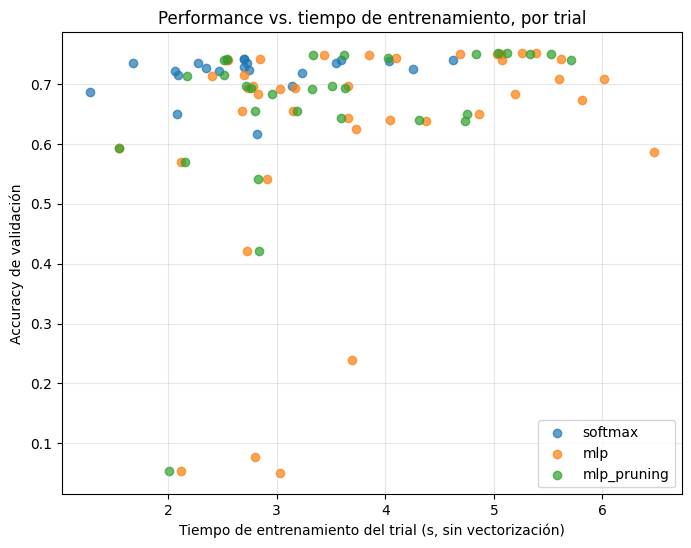

In [ ]:
df_complete = df_compare[df_compare["state"] == "COMPLETE"]
plt.figure(figsize=(8, 6))
for m_name, color in [("softmax", "tab:blue"), ("mlp", "tab:orange"), ("mlp_pruning", "tab:green")]:
    sub = df_complete[df_complete["modelo"] == m_name]
    plt.scatter(sub["user_attrs_train_time_sec"], sub["value"], label=m_name, color=color, alpha=0.7)
plt.xlabel("Tiempo de entrenamiento del trial (s, sin vectorización)")
plt.ylabel("Accuracy de validación")
plt.title("Performance vs. tiempo de entrenamiento, por trial")
plt.legend(); plt.grid(alpha=0.3); plt.show()

### 15.1 🔧 Efecto del pruning (medido)

Se comparan los dos estudios del MLP, con la misma semilla y el mismo espacio, uno con `MedianPruner` y otro sin pruning. Se mide el tiempo de pared, el tiempo de entrenamiento, las épocas totales corridas y la **mejor `val_acc` acumulada en función del tiempo**: si con pruning se llega al mismo nivel en menos tiempo, el ahorro es real.

**Qué hace este código:** ordena los trials por orden de ejecución, acumula el tiempo (`duration`, que incluye la vectorización) y el máximo de `value` hasta cada trial, y grafica las dos curvas.

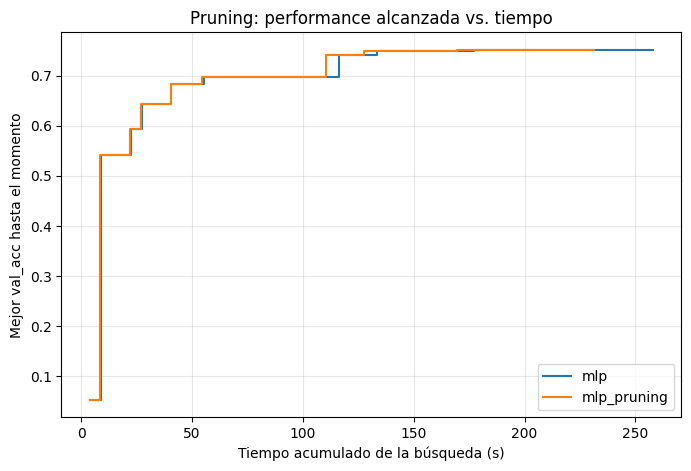

Trials podados: 10/40
Tiempo de pared: sin pruning 258.1 s | con pruning 231.5 s | ahorro 26.5 s (10.3 %)
Épocas totales entrenadas: sin pruning 273 | con pruning 228
Mejor val: sin pruning 0.7517 | con pruning 0.7517


In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
for m_name in ["mlp", "mlp_pruning"]:
    d = df_compare[df_compare.modelo == m_name].sort_values("number")
    t_acc = d["duration_sec"].cumsum()
    best_so_far = d["value"].fillna(-np.inf).cummax().replace(-np.inf, np.nan)
    ax.step(t_acc, best_so_far, where="post", label=m_name)
ax.set_xlabel("Tiempo acumulado de la búsqueda (s)"); ax.set_ylabel("Mejor val_acc hasta el momento")
ax.set_title("Pruning: performance alcanzada vs. tiempo"); ax.legend(); ax.grid(alpha=0.3); plt.show()

ahorro_pared = wall_time_mlp - wall_time_mlp_pruning
ep_sin = df_mlp_trials["user_attrs_epochs_run"].sum()
ep_con = df_mlp_pruning_trials["user_attrs_epochs_run"].sum()
n_pruned = (df_mlp_pruning_trials.state == "PRUNED").sum()
print(f"Trials podados: {n_pruned}/{N_TRIALS}")
print(f"Tiempo de pared: sin pruning {wall_time_mlp:.1f} s | con pruning {wall_time_mlp_pruning:.1f} s "
      f"| ahorro {ahorro_pared:.1f} s ({100*ahorro_pared/wall_time_mlp:.1f} %)")
print(f"Épocas totales entrenadas: sin pruning {ep_sin} | con pruning {ep_con}")
print(f"Mejor val: sin pruning {study_mlp.best_value:.4f} | con pruning {study_mlp_pruning.best_value:.4f}")

### 15.2 Matrices de confusión / classification_report

**Qué hace este código:** compara el f1 por clase de la softmax (leído de `results/tp1_summary.json`) y del MLP final, ordenado por la diferencia.

In [ ]:
f1_cmp = pd.DataFrame({
    "f1_softmax": {c: tp1_summary["per_class"][c]["f1-score"] for c in class_names},
    "f1_mlp": {c: report_mlp[c]["f1-score"] for c in class_names},
    "prec_mlp": {c: report_mlp[c]["precision"] for c in class_names},
    "recall_mlp": {c: report_mlp[c]["recall"] for c in class_names},
})
f1_cmp["dif_mlp_menos_softmax"] = f1_cmp.f1_mlp - f1_cmp.f1_softmax
display(f1_cmp.sort_values("dif_mlp_menos_softmax").round(3))

,f1_softmax,f1_mlp,prec_mlp,recall_mlp,dif_mlp_menos_softmax
rec.autos,0.709,0.599,0.496,0.758,-0.110
talk.politics.guns,0.633,0.620,0.579,0.668,-0.013
rec.sport.baseball,0.845,0.837,0.876,0.801,-0.008
sci.electronics,0.599,0.598,0.584,0.613,-0.001
comp.windows.x,0.728,0.730,0.796,0.673,0.002
sci.med,0.770,0.775,0.795,0.755,0.005
sci.crypt,0.747,0.752,0.812,0.699,0.005
rec.sport.hockey,0.882,0.890,0.890,0.890,0.008
talk.politics.mideast,0.770,0.789,0.832,0.750,0.019
comp.graphics,0.625,0.645,0.628,0.663,0.020


### 15.3 🔧 Resumen numérico de esta corrida

Todos los números del análisis salen de esta celda, que solo usa resultados de **esta** ejecución (variables de la Parte 2 y archivos de `results/` escritos por la Parte 1 en la misma corrida). También se guarda en `results/tp2_summary.json`.

In [ ]:
tp2_summary = {
    "softmax": {"mejor_val_busqueda": tp1_summary["best_val_search"], "test_semilla42": tp1_summary["final"]["test_acc"],
                "val_semillas": [df_seeds_softmax_disk.val_acc.mean(), df_seeds_softmax_disk.val_acc.std()],
                "test_semillas": [df_seeds_softmax_disk.test_acc.mean(), df_seeds_softmax_disk.test_acc.std()],
                "t_pared_busqueda_s": tp1_summary["wall_time_search_s"]},
    "mlp": {"best_params": best_mlp, "mejor_val_busqueda": study_mlp.best_value, "test_semilla42": test_accuracy_mlp,
            "val_semillas": [df_seeds_mlp.val_acc.mean(), df_seeds_mlp.val_acc.std()],
            "test_semillas": [df_seeds_mlp.test_acc.mean(), df_seeds_mlp.test_acc.std()],
            "t_pared_busqueda_s": wall_time_mlp},
    "pruning": {"t_pared_s": wall_time_mlp_pruning, "mejor_val": study_mlp_pruning.best_value,
                "n_podados": int((df_mlp_pruning_trials.state == "PRUNED").sum())},
    "n_trials": N_TRIALS, "epochs_search": EPOCHS_SEARCH,
}
with open(f"{RESULTS_DIR}/tp2_summary.json", "w") as f:
    json.dump(tp2_summary, f, indent=2, default=float)
print(json.dumps(tp2_summary, indent=2, default=lambda x: round(float(x), 4)))

{
  "softmax": {
    "mejor_val_busqueda": 0.7428192664604507,
    "test_semilla42": 0.669676048858205,
    "val_semillas": [
      0.7400795404330536,
      0.003907678474491244
    ],
    "test_semillas": [
      0.6691184280403611,
      0.0015748410889228396
    ],
    "t_pared_busqueda_s": 179.572582146
  },
  "mlp": {
    "best_params": {
      "remove_stopwords": false,
      "normalization": "stem",
      "ngram_range": "1gram",
      "max_features": 10000,
      "min_df": 1,
      "n_layers": 1,
      "n_units_l0": 256,
      "activation": "tanh",
      "lr": 0.0006950121809596989,
      "batch_size": 64,
      "optimizer": "adam",
      "adam_one_minus_beta1": 0.01612890255517946,
      "adam_one_minus_beta2": 0.009754791258426364
    },
    "mejor_val_busqueda": 0.7516570923552806,
    "test_semilla42": 0.6882634094530006,
    "val_semillas": [
      0.7504197967300044,
      0.0011857187684488162
    ],
    "test_semillas": [
      0.6870950610727562,
      0.00347915047295

### Análisis

#### Accuracy — Softmax vs. MLP

Esta vez el resultado se dio vuelta respecto de la entrega anterior: con el protocolo corregido, el MLP le gana a la softmax, por poco pero de forma consistente.

| | Softmax | MLP | Diferencia |
|---|---|---|---|
| mejor val en la búsqueda | 0,7428 | 0,7517 | +0,89 pp |
| val (5 semillas) | 0,7401 ± 0,0039 | 0,7504 ± 0,0012 | +1,03 pp (p = 0,003) |
| test (5 semillas) | 0,6691 ± 0,0016 | 0,6871 ± 0,0035 | +1,80 pp (p < 0,001) |

La diferencia en test es de 1,8 pp con desvíos de 0,16 y 0,35 pp, y el test de Welch da p < 0,001. Es una mejora chica pero real, no ruido entre semillas. Los números de la entrega anterior (softmax 0,6616 contra MLP 0,6240 en test) venían de corridas distintas, sin semillas y con el test usado como validación, así que no son comparables con estos.

El mejor MLP es una arquitectura chica: una sola capa oculta de 256 neuronas con tanh, Adam con lr ≈ 7·10⁻⁴, β₁ ≈ 0,984 y β₂ ≈ 0,990, el mismo preprocesamiento que la softmax salvo que no saca stopwords y usa `min_df` = 1. Los 12 mejores trials tienen todos **una sola capa oculta** (de 64 a 256 neuronas) y Adam. Con 2 capas el mejor trial llegó a 0,7084 y con 3 capas a 0,593. Es consistente con el teorema de aproximación universal que vimos en la presentación de MLP (alcanza con una capa oculta) y con el barrido de capacidad de la sección 13: en este problema, agregar capas solo agrega sobreajuste. Los dos trials con SGD quedaron en nivel azar (≈0,05): con ese lr y las épocas disponibles no llegaron a aprender nada.

**Sobre el split:** la softmax y el MLP se validan sobre **el mismo** split (80/20 estratificado con `random_state=SEED`, función `split_train_val`). En la entrega anterior afirmé que el split era distinto, y eso era incorrecto. La diferencia en validación no se explica por la partición.

**Sobre la activación:** el control de 14.1 confirma la hipótesis de la saturación de la sigmoidea. Con 10 épocas, sigmoid pierde 4,1 pp contra ReLU; con el protocolo largo llega al mismo resultado, pero tardando más del triple de épocas. Igual, esto ya no explica la diferencia con la softmax, porque el mejor MLP usa tanh y no sigmoid.

**Sobre el presupuesto de búsqueda:** las dos búsquedas tuvieron 40 trials, hasta 10 épocas por trial con early stopping, el mismo split y el sampler con semilla. Quedó una diferencia: el estudio de la softmax se creó sin indicar `pruner`, así que Optuna usó su `MedianPruner` por defecto y cortó 18 de los 40 trials, mientras que el estudio del MLP sin pruning tiene los 40 completos. Para comparar con la misma regla de poda está el estudio del MLP con pruning (40 trials, 10 podados), que llegó al mismo mejor valor (0,7517). En cualquier caso, la comparación que decide es la de las 5 semillas, que no depende de la búsqueda. El MLP busca entre 12 y 15 hiperparámetros contra 7 de la softmax con los mismos 40 trials, así que su espacio queda menos cubierto, y aun así encontró una configuración mejor.

#### Tiempos de entrenamiento

| | Softmax | MLP sin pruning | MLP con pruning |
|---|---|---|---|
| tiempo total de la búsqueda | 179,6 s | 258,1 s | 231,5 s |
| vectorización (suma de trials) | 103,0 s | 103,2 s | 102,7 s |
| entrenamiento (suma de trials) | 69,0 s | 152,7 s | 126,9 s |
| s/época (media) | 0,41 | 0,59 | 0,59 |
| épocas entrenadas | 164 | 273 | 228 |

La vectorización cuesta lo mismo en las tres búsquedas (≈103 s, entre el 40 y el 57 % del tiempo total), porque depende solo del preprocesamiento. Separarla muestra el costo propio del modelo: por época el MLP tarda ≈40 % más que la softmax (0,59 contra 0,41 s), porque agrega una capa de 10000 × 256 + 256 × 20 parámetros, contra los 10000 × 20 de la softmax, y un segundo producto matricial en el forward y en el backward. El MLP además corrió más épocas (273 contra 164), en parte porque converge más lento (mejor época 6 contra 2,8 de la softmax en el protocolo final) y en parte porque la softmax tuvo pruning. En el modelo final, con semillas, la softmax tarda 3,6 s y el MLP 6,4 s.

#### Efecto del pruning

Con la misma semilla y el mismo espacio, el `MedianPruner` podó 10 de los 40 trials. La búsqueda tardó 231,5 s contra 258,1 s sin pruning: un ahorro medido de 26,5 s (10,3 %), con 228 épocas entrenadas en vez de 273. Las dos búsquedas encontraron el mismo mejor trial (0,7517, con los mismos hiperparámetros), así que podar no hizo perder la mejor solución.

El ahorro es bastante menor que lo que estimé en la entrega anterior (≈119 s). Esa estimación era una cuenta a mano que mezclaba vectorización con entrenamiento. Además, ahora cada trial tiene early stopping, que ya corta muchos trials malos antes de que el pruner intervenga, y la vectorización (≈2,5 s por trial) se paga igual en los trials podados. El pruner solo puede ahorrar la parte de entrenamiento.

#### Overfitting

El barrido de la sección 13 muestra que el sobreajuste crece con la capacidad. Con 3 capas de 1024 neuronas (12,4 millones de parámetros para 9051 documentos de train), la val_loss sube de 1,15 a 3,25 después de su mínimo en la época 2, y la brecha train−val final es 0,315. Con 1×64 la val_loss sube solo 0,15 y la brecha es 0,249. Y a diferencia de lo que había concluido antes, la capacidad extra no deja la validación igual sino que la empeora: la mejor val_acc baja de 0,7499 (1×64) a 0,6695 (3×1024). Toda esa capacidad se va en memorizar el train set.

#### Comparando las matrices de confusión / classification_report

El MLP mejora el f1 en 16 de las 20 clases. La mayor ganancia es rec.motorcycles (+0,16), y la única pérdida grande es rec.autos (−0,11). En realidad es la misma confusión que cambia de dirección: la softmax mandaba muchos autos a motorcycles (precision de motorcycles 0,46), y el MLP hace lo contrario y predice "autos" de más (precision 0,50, recall 0,76). La confusión entre autos y motos sigue estando, solo que ahora se resuelve hacia el otro lado.

talk.religion.misc sigue siendo la categoría más difícil en los dos modelos (f1 0,28 en la softmax y 0,33 en el MLP). Esto refuerza lo que ya habíamos visto en la Parte 1: el problema ahí no es la arquitectura del modelo, sino que es una categoría "cajón de sastre" que se solapa en contenido con alt.atheism y soc.religion.christian. Ni la softmax ni el MLP lo resuelven, porque el límite entre esas categorías no está tanto en el vocabulario como en el enfoque del post, algo que ninguno de los dos modelos puede captar trabajando solo con bolsa de palabras.

#### Conclusión

En este problema (TF-IDF de 10000 términos y 20 categorías), agregar **una** capa oculta da una mejora chica pero estadísticamente clara frente a la regresión softmax: +1,8 pp en test, a cambio de casi el doble de tiempo de entrenamiento por modelo. Agregar más capas no ayuda: el barrido de capacidad muestra que al modelo no le falta capacidad, y que la capacidad extra sin regularización se traduce en memorizar el train en vez de generalizar mejor. Eso es lo que se estudia en la Parte 3. Las categorías más difíciles (como talk.religion.misc) siguen siéndolo para los dos modelos, porque el problema ahí es de contenido solapado y no de qué tan compleja es la arquitectura.

# Parte 3 - Regularización

Objetivo: tomar el MLP sobredimensionado de la Parte 2 (3 capas × 1024 neuronas, que sobreajusta claramente en el barrido de capacidad de la sección 13) y aplicarle las técnicas vistas en clase:

- Regularización **L2** (`weight_decay` acoplado de Adam y decoupled de AdamW), **L1** y **L1+L2**.
- **Dropout** (y su recomendación de subir el lr con momentum alto).
- **Max-norm**.
- **Batch Normalization** (incluyendo lr más alto).

Para cada una se analizan los **valores absolutos de los pesos**, los **tiempos de entrenamiento**, el **learning rate** y el **ruido en las curvas de aprendizaje**. Al final, las técnicas se incluyen como **hiperparámetros en una búsqueda de Optuna** conjunta.

🔧 **Correcciones del diseño experimental respecto de la entrega original:**

| Problema señalado | Cómo se resuelve |
|---|---|
| Baseline con 40 épocas y técnicas con 15 | **Todas** las configuraciones, incluido el baseline, se entrenan `EPOCHS_REG` épocas con el mismo split, batch, lr base y semillas. El baseline se reentrena con ese protocolo. |
| "Dropout más rápido que el base" comparaba 15 vs. 40 épocas | Se comparan **segundos por época** con la misma cantidad de épocas |
| Una sola corrida por configuración | Cada configuración se repite con `REG_SEEDS` semillas; se reporta media ± desvío y un test de Welch contra el baseline |
| No se probó max-norm | Sección 22 |
| BN sin lr más alto | Sección 23.1 |
| LR con dropout parcial y contradictorio; no se probó ×5 | Sección 21.1: lr ×1, ×5 y ×10, con y sin max-norm |
| L1+L2 con un solo punto | Grilla 3×3 de λ₁ × λ₂ (sección 20) |
| Dropout 0.7 fuera de rango, sin comentar | Barrido extendido y discusión (sección 21) |
| Ruido de las curvas no cuantificado | Métricas de ruido en cada configuración (sección 16) |
| Técnicas no incluidas en Optuna | Búsqueda conjunta (sección 25) |
| `weight_decay` de Adam ≠ AdamW sin aclarar | Sección 18: se explica y se comparan ambos |
| Sin test final ni semillas | Sección 26: mejor modelo regularizado con 5 semillas, evaluado en test |

**Sobre la elección de 3×1024 en vez de 1×256 (pregunta de la devolución).** Se eligió a propósito el modelo que sobreajusta. El objetivo de esta parte es estudiar cómo cada técnica **controla el exceso de capacidad**, y eso se observa con claridad cuando hay sobreajuste. El óptimo del TP2 (1×256) casi no tiene brecha train−val que reducir, así que el efecto de cada técnica quedaría en el orden del ruido. Para no quedarse solo con ese caso, la búsqueda conjunta de la sección 25 deja libre la arquitectura (de 1×64 a 3×1024) junto con las técnicas, así que el óptimo regularizado puede terminar siendo una red chica, una grande regularizada o una intermedia. En esta corrida, Optuna terminó eligiendo una red de 1×64 con dropout.

## 16. Setup y utilidades comunes

**Configuración:** `EPOCHS_REG` épocas fijas por configuración (sin early stopping, para ver la curva completa y comparar tiempos con las mismas épocas) y `REG_SEEDS` semillas. Se reportan la `val_acc` final, la **mejor** `val_acc` (y en qué época) y la brecha train−val final.

⏱️ **Costo:** son 46 configuraciones × 3 semillas × 20 épocas de una red 3×1024 (12,4 millones de parámetros). En esta corrida, con GPU en Colab, el entrenamiento de todas las configuraciones sumó unos 55 minutos.

**`RegularizedMLP`**: igual que `MLP`, pero con `dropout_rate` (Dropout después de cada activación) y `use_batchnorm` (`BatchNorm1d` **antes** de la activación y sin bias en la `Linear`, porque β de BN cumple ese rol).

**`apply_max_norm`**: después de cada paso del optimizador, reescala cada fila de cada matriz de pesos (los pesos que **entran** a una neurona) para que su norma L2 no supere `c`: $\mathbf{w}_i \leftarrow \mathbf{w}_i \cdot \min(1, c / \|\mathbf{w}_i\|_2)$. Es una restricción dura, no un término en la loss.

**`train_reg`**: loop de entrenamiento con L1 opcional (sumado a la loss), max-norm opcional y registro de: `mean|w|` por época, tiempo por época y **loss de cada mini-batch** (para medir el ruido).

**Métricas de ruido** (🔧 corrección: antes el ruido se describía a ojo):
- `ruido_batch_train`: coeficiente de variación (desvío/media) de la loss por mini-batch en la última época. Mide cuánto salta la loss entre batches.
- `rugosidad_val` y `rugosidad_train`: desvío de las diferencias época a época de `val_acc` y `train_acc`, $\mathrm{std}(\Delta \mathrm{acc}_t)$. Mide cuánto "serrucha" la curva.
- `std_entre_semillas`: desvío de la `val_acc` final entre semillas (variabilidad del resultado).

**`run_config`**: corre una configuración con todas las semillas y guarda una fila por semilla en `reg_rows`, más las curvas y los pesos de la primera semilla (para los gráficos).

In [ ]:
# --- Setup de la Parte 3: lo necesario de la Parte 2 se recrea si falta ---
if "ds_tr_of" not in globals():
    raise RuntimeError("Ejecutar la sección 13 de la Parte 2 (define ds_tr_of / ds_val_of / ds_test_of).")

EPOCHS_REG = 20
REG_SEEDS = SEEDS[:3]
REG_HIDDEN = [1024, 1024, 1024]
REG_LR = 1e-3
REG_BATCH = 64
INPUT_DIM_REG = X_tr_of.shape[1]


class RegularizedMLP(nn.Module):
    def __init__(self, input_dim, hidden_dims, activation, num_classes, dropout_rate=0.0, use_batchnorm=False):
        super().__init__()
        act_cls = ACTIVATIONS[activation]
        layers, prev_dim = [], input_dim
        for h in hidden_dims:
            layers.append(nn.Linear(prev_dim, h, bias=not use_batchnorm))
            if use_batchnorm:
                layers.append(nn.BatchNorm1d(h))
            layers.append(act_cls())
            if dropout_rate > 0:
                layers.append(nn.Dropout(dropout_rate))
            prev_dim = h
        layers.append(nn.Linear(prev_dim, num_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def linear_weights(model):
    return [m.weight for m in model.modules() if isinstance(m, nn.Linear)]


@torch.no_grad()
def apply_max_norm(model, c):
    for w in linear_weights(model):
        w.copy_(torch.renorm(w, p=2, dim=0, maxnorm=c))   # cada fila (pesos entrantes a una neurona)


def get_weight_stats(model):
    w = torch.cat([p.detach().cpu().flatten() for p in linear_weights(model)])
    row_norms = torch.cat([p.detach().cpu().norm(dim=1) for p in linear_weights(model)])
    return {"mean_abs": w.abs().mean().item(), "max_abs": w.abs().max().item(),
            "frac_near_zero": (w.abs() < 1e-3).float().mean().item(),
            "max_row_norm": row_norms.max().item(),
            # submuestra fija de 200k pesos para los histogramas (guardar los ~8M por configuración no entra en memoria)
            "values": w[torch.randperm(len(w), generator=torch.Generator().manual_seed(0))[:200_000]].numpy()}


def train_reg(model, train_loader, val_loader, optimizer, epochs, l1_lambda=0.0, max_norm=None):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    weights = linear_weights(model)
    h = {k: [] for k in ["train_loss", "val_loss", "train_acc", "val_acc", "mean_abs_weight", "epoch_time_sec"]}
    batch_losses_last = []
    for epoch in range(epochs):
        t0 = time.perf_counter()
        model.train()
        run_loss, correct, total, batch_losses = 0.0, 0, 0, []
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            ce = criterion(logits, yb)
            loss = ce + l1_lambda * sum(w.abs().sum() for w in weights) if l1_lambda > 0 else ce
            loss.backward()
            optimizer.step()
            if max_norm is not None:
                apply_max_norm(model, max_norm)
            batch_losses.append(ce.item())          # se registra la CE (sin el término L1) para comparar
            run_loss += ce.item() * xb.size(0)
            correct += (logits.argmax(1) == yb).sum().item()
            total += xb.size(0)
        val_loss, val_acc = run_epoch(model, val_loader, criterion)
        if device.type == "cuda":
            torch.cuda.synchronize()
        h["epoch_time_sec"].append(time.perf_counter() - t0)
        h["train_loss"].append(run_loss / total); h["train_acc"].append(correct / total)
        h["val_loss"].append(val_loss); h["val_acc"].append(val_acc)
        h["mean_abs_weight"].append(get_weight_stats(model)["mean_abs"])
        batch_losses_last = batch_losses
    h["batch_losses_last"] = batch_losses_last
    return h


def noise_metrics(h):
    bl = np.array(h["batch_losses_last"])
    return {"ruido_batch_train": float(bl.std() / bl.mean()),
            "rugosidad_train": float(np.std(np.diff(h["train_acc"]))),
            "rugosidad_val": float(np.std(np.diff(h["val_acc"])))}


reg_rows, reg_curves, reg_weights = [], {}, {}


def run_config(technique, hparam, model_kwargs=None, opt="adam", lr=REG_LR, weight_decay=0.0,
               momentum=0.9, l1_lambda=0.0, max_norm=None, batch_size=REG_BATCH, epochs=None, seeds=None):
    model_kwargs = model_kwargs or {}
    epochs = epochs or EPOCHS_REG
    key = f"{technique} | {hparam}"
    for i, seed in enumerate(seeds or REG_SEEDS):
        set_seed(seed)
        model = RegularizedMLP(INPUT_DIM_REG, REG_HIDDEN, "relu", NUM_CLASSES, **model_kwargs)
        decay = [p for n, p in model.named_parameters() if n.endswith(".weight") and p.dim() > 1]
        no_decay = [p for n, p in model.named_parameters() if not (n.endswith(".weight") and p.dim() > 1)]
        groups = [{"params": decay, "weight_decay": weight_decay}, {"params": no_decay, "weight_decay": 0.0}]
        if opt == "adam":
            optimizer = optim.Adam(groups, lr=lr)
        elif opt == "adamw":
            optimizer = optim.AdamW(groups, lr=lr)
        else:
            optimizer = optim.SGD(groups, lr=lr, momentum=momentum)
        h = train_reg(model, make_loader(ds_tr_of, batch_size, True, seed), make_loader(ds_val_of, batch_size, False),
                      optimizer, epochs, l1_lambda=l1_lambda, max_norm=max_norm)
        ws = get_weight_stats(model)
        best_i = int(np.argmax(h["val_acc"]))
        reg_rows.append({"tecnica": technique, "hparam": str(hparam), "config": key, "seed": seed,
                         "val_acc_final": h["val_acc"][-1], "val_acc_mejor": h["val_acc"][best_i],
                         "epoca_mejor": best_i + 1, "train_acc_final": h["train_acc"][-1],
                         "brecha_final": h["train_acc"][-1] - h["val_acc"][-1],
                         "val_loss_min": min(h["val_loss"]), "val_loss_final": h["val_loss"][-1],
                         "mean_abs_w": ws["mean_abs"], "max_abs_w": ws["max_abs"],
                         "frac_casi_cero": ws["frac_near_zero"], "max_norma_fila": ws["max_row_norm"],
                         "s_por_epoca": float(np.mean(h["epoch_time_sec"][1:] or h["epoch_time_sec"])),
                         "t_total_s": float(np.sum(h["epoch_time_sec"])), "lr": lr, "batch_size": batch_size,
                         **noise_metrics(h)})
        if i == 0:
            reg_curves[key] = h
            reg_weights[key] = ws
        del model, optimizer
    print(f"listo: {key}")
    return key


def summarize(keys=None):
    df = pd.DataFrame(reg_rows)
    if keys is not None:
        df = df[df.config.isin(keys)]
    g = df.groupby("config", sort=False)
    out = g.agg(val_final=("val_acc_final", "mean"), val_final_std=("val_acc_final", "std"),
                val_mejor=("val_acc_mejor", "mean"), epoca_mejor=("epoca_mejor", "mean"),
                brecha=("brecha_final", "mean"), val_loss_min=("val_loss_min", "mean"),
                mean_abs_w=("mean_abs_w", "mean"), frac_casi_cero=("frac_casi_cero", "mean"),
                max_norma_fila=("max_norma_fila", "mean"), s_por_epoca=("s_por_epoca", "mean"),
                ruido_batch=("ruido_batch_train", "mean"), rugos_train=("rugosidad_train", "mean"),
                rugos_val=("rugosidad_val", "mean"))
    _all = pd.DataFrame(reg_rows)
    base = _all[_all.config == BASE_KEY]["val_acc_final"] if "BASE_KEY" in globals() else None
    if base is not None and len(base) > 1:
        out["p_vs_base"] = [stats.ttest_ind(df[df.config == k]["val_acc_final"], base, equal_var=False).pvalue
                            if k != BASE_KEY else np.nan for k in out.index]
    return out


def plot_curves(keys, title, metric_pairs=(("val_loss", "Val loss"), ("val_acc", "Val accuracy"))):
    fig, axes = plt.subplots(1, len(metric_pairs), figsize=(6 * len(metric_pairs), 4))
    for ax, (metric, label) in zip(np.atleast_1d(axes), metric_pairs):
        for k in keys:
            ax.plot(range(1, len(reg_curves[k][metric]) + 1), reg_curves[k][metric], label=k)
        ax.set_xlabel("Época"); ax.set_ylabel(label); ax.set_title(f"{title} - {label}"); ax.legend(fontsize=7)
    plt.tight_layout(); plt.show()


def plot_weight_hist(keys, title, clip=0.15):
    plt.figure(figsize=(8, 4))
    for k in keys:
        v = reg_weights[k]["values"]
        plt.hist(np.clip(v, -clip, clip), bins=120, alpha=0.45, density=True, label=k, histtype="stepfilled")
    plt.yscale("log"); plt.xlabel(f"Valor del peso (recortado a ±{clip})"); plt.ylabel("Densidad (log)")
    plt.title(title); plt.legend(fontsize=7); plt.show()

## 17. Caso base (reentrenado con el mismo protocolo)

🔧 **Corrección:** antes se reutilizaba la corrida de 40 épocas de la Parte 2 y las técnicas se entrenaban 15 épocas. Ahora el baseline se reentrena con **exactamente** el mismo protocolo que todas las técnicas (`EPOCHS_REG` épocas, batch 64, Adam con lr = 1e-3, mismas semillas).

**Qué hace este código:** corre el baseline sin regularización y guarda su clave (`BASE_KEY`), que `summarize` usa para el test de Welch de cada configuración contra el baseline.

In [ ]:
BASE_KEY = run_config("Baseline", "sin regularizar")
display(summarize([BASE_KEY]).round(4))

listo: Baseline | sin regularizar


,val_final,val_final_std,val_mejor,epoca_mejor,brecha,val_loss_min,mean_abs_w,frac_casi_cero,max_norma_fila,s_por_epoca,ruido_batch,rugos_train,rugos_val,p_vs_base
config,,,,,,,,,,,,,,
Baseline | sin regularizar,0.6645,0.0033,0.6717,7.0,0.3098,1.1833,0.0218,0.0336,7.9069,1.0764,0.7272,0.094,0.0248,NaN


## 18. Regularización L2: `weight_decay` de Adam (acoplado) vs. AdamW (desacoplado)

Las recomendaciones de clase que aplicamos:

- **λ ≈ 1e-4 como punto de partida**: el barrido va un orden de magnitud para cada lado.
- **No regularizar los bias**: se arman dos grupos de parámetros y el `weight_decay` se aplica solo a las matrices de pesos, no a los bias ni a γ/β de BatchNorm.

🔧 **Adam vs. AdamW** (observación de la devolución): el `weight_decay` de `optim.Adam` es **acoplado**: suma $\lambda w$ al gradiente, que es exactamente el gradiente de la penalidad L2 $\frac{\lambda}{2}\|w\|^2$. Ese término después pasa por la normalización adaptativa de Adam: se divide por $\sqrt{\hat v}$. Los pesos con gradientes históricos grandes ($\hat v$ grande) reciben **menos** decaimiento efectivo, y los de gradiente chico, más. Así, la regularización deja de ser un encogimiento uniforme de todos los pesos. **AdamW** desacopla el decaimiento: aplica $w \leftarrow w - \eta \lambda w$ directamente, fuera de la normalización adaptativa, así que todos los pesos se encogen en la misma proporción por paso. Son dos regularizaciones distintas y sus λ no son comparables: en AdamW el decaimiento por paso es $\eta\lambda$, y con η = 1e-3 hacen falta λ del orden de 1e-2 a 1e-1 para un efecto visible.

**Qué hace este código:** barre λ para Adam (L2 acoplado) y para AdamW (decoupled), con todo lo demás igual al baseline.

listo: L2 (Adam acoplado) | λ=1e-05
listo: L2 (Adam acoplado) | λ=0.0001
listo: L2 (Adam acoplado) | λ=0.001
listo: L2 (AdamW desacoplado) | λ=0.001
listo: L2 (AdamW desacoplado) | λ=0.01
listo: L2 (AdamW desacoplado) | λ=0.1


,val_final,val_final_std,val_mejor,epoca_mejor,brecha,val_loss_min,mean_abs_w,frac_casi_cero,max_norma_fila,s_por_epoca,ruido_batch,rugos_train,rugos_val,p_vs_base
config,,,,,,,,,,,,,,
Baseline | sin regularizar,0.6645,0.0033,0.6717,7.0000,0.3098,1.1833,0.0218,0.0336,7.9069,1.0764,0.7272,0.0940,0.0248,NaN
L2 (Adam acoplado) | λ=1e-05,0.6477,0.0055,0.6586,9.0000,0.3264,1.2138,0.0150,0.3847,4.0173,1.1668,0.7140,0.0954,0.0264,0.0164
L2 (Adam acoplado) | λ=0.0001,0.6287,0.0045,0.6409,2.3333,0.3309,1.2451,0.0079,0.5192,3.3026,1.1687,0.5644,0.0937,0.0333,0.0006
L2 (Adam acoplado) | λ=0.001,0.5849,0.0042,0.5862,18.6667,0.3686,1.5513,0.0023,0.7959,3.2936,1.1689,0.3770,0.0643,0.0469,0.0000
L2 (AdamW desacoplado) | λ=0.001,0.6633,0.0020,0.6720,13.3333,0.3113,1.1861,0.0196,0.0360,6.8792,1.1405,0.7343,0.0938,0.0222,0.6326
L2 (AdamW desacoplado) | λ=0.01,0.6575,0.0046,0.6690,12.0000,0.3151,1.1855,0.0233,0.0324,6.8724,1.1421,0.6969,0.0940,0.0231,0.1095
L2 (AdamW desacoplado) | λ=0.1,0.6580,0.0049,0.6701,8.0000,0.3165,1.1806,0.0204,0.0385,7.7636,1.1454,0.7464,0.0940,0.0253,0.1385


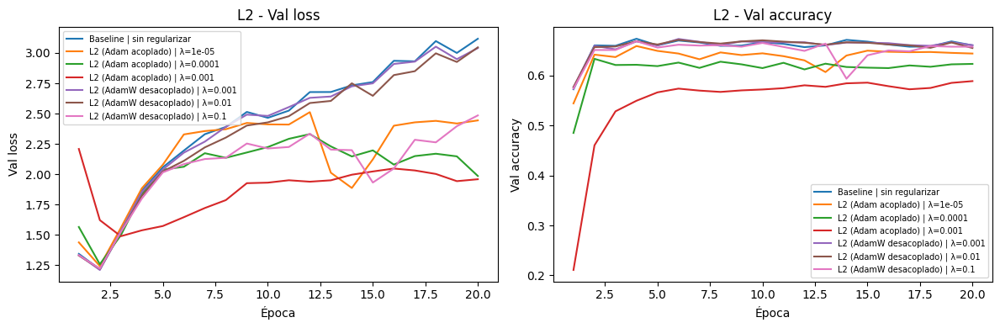

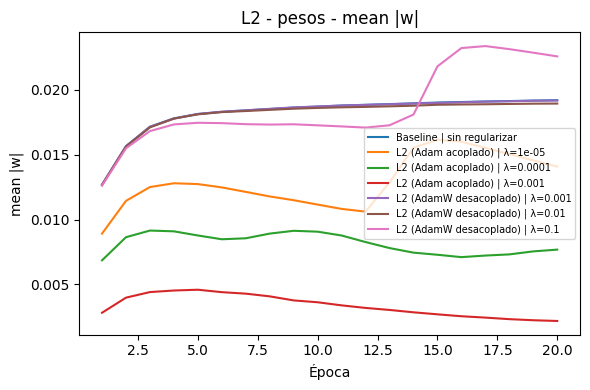

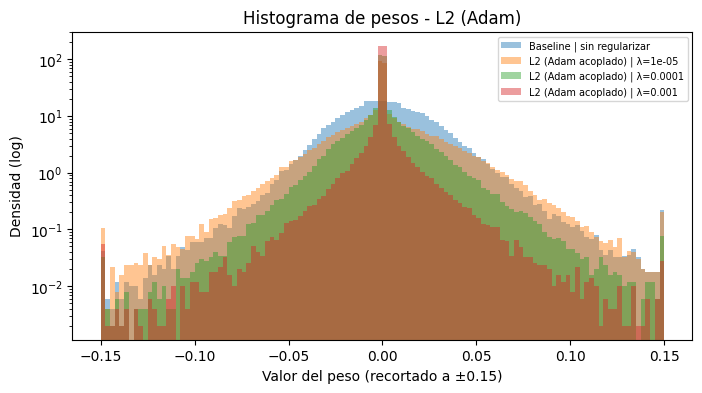

In [ ]:
L2_KEYS = [run_config("L2 (Adam acoplado)", f"λ={lam:g}", opt="adam", weight_decay=lam) for lam in [1e-5, 1e-4, 1e-3]]
ADAMW_KEYS = [run_config("L2 (AdamW desacoplado)", f"λ={lam:g}", opt="adamw", weight_decay=lam) for lam in [1e-3, 1e-2, 1e-1]]
display(summarize([BASE_KEY] + L2_KEYS + ADAMW_KEYS).round(4))
plot_curves([BASE_KEY] + L2_KEYS + ADAMW_KEYS, "L2")
plot_curves([BASE_KEY] + L2_KEYS + ADAMW_KEYS, "L2 - pesos", (("mean_abs_weight", "mean |w|"),))
plot_weight_hist([BASE_KEY] + L2_KEYS, "Histograma de pesos - L2 (Adam)")

## 19. Regularización L1

PyTorch no tiene un parámetro nativo para L1, así que se suma a mano a la loss: $\lambda_1 \sum |w|$ (solo sobre los pesos de las capas `Linear`). El gradiente de este término es $\lambda_1\,\mathrm{sign}(w)$, **constante** en magnitud, a diferencia del de L2, que es proporcional a $w$. Por eso L1 empuja los pesos chicos hasta cero (esparsidad) en vez de achicar todos en proporción. Además del histograma, miramos `frac_casi_cero` (fracción de pesos con $|w| < 10^{-3}$).

L1 suele necesitar λ más chicos que L2. La suma $\sum|w|$ es sobre unos 8 millones de pesos, así que un λ₁ = 1e-4 ya domina la cross-entropy (en la entrega original, con 1e-4 el modelo colapsaba).

**Qué hace este código:** barre λ₁ ∈ {1e-7, 1e-6, 1e-5} con Adam y todo lo demás como el baseline.

listo: L1 | λ1=1e-07
listo: L1 | λ1=1e-06
listo: L1 | λ1=1e-05


,val_final,val_final_std,val_mejor,epoca_mejor,brecha,val_loss_min,mean_abs_w,frac_casi_cero,max_norma_fila,s_por_epoca,ruido_batch,rugos_train,rugos_val,p_vs_base
config,,,,,,,,,,,,,,
Baseline | sin regularizar,0.6645,0.0033,0.6717,7.0000,0.3098,1.1833,0.0218,0.0336,7.9069,1.0764,0.7272,0.0940,0.0248,NaN
L1 | λ1=1e-07,0.6485,0.0098,0.6594,9.0000,0.3260,1.2111,0.0157,0.4703,4.2353,1.3522,0.7322,0.0949,0.0266,0.0952
L1 | λ1=1e-06,0.6297,0.0119,0.6413,13.0000,0.3397,1.2577,0.0087,0.6708,3.9922,1.3471,0.6590,0.0929,0.0334,0.0294
L1 | λ1=1e-05,0.5758,0.0267,0.5759,19.3333,0.3883,1.6775,0.0023,0.9146,4.6541,1.3494,0.5759,0.0649,0.0476,0.0275


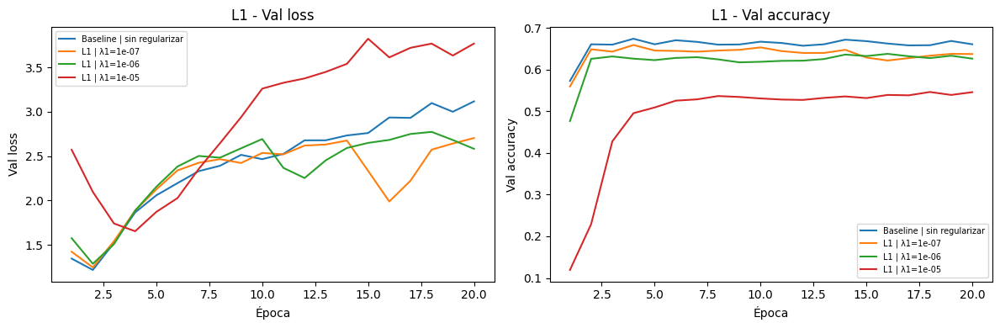

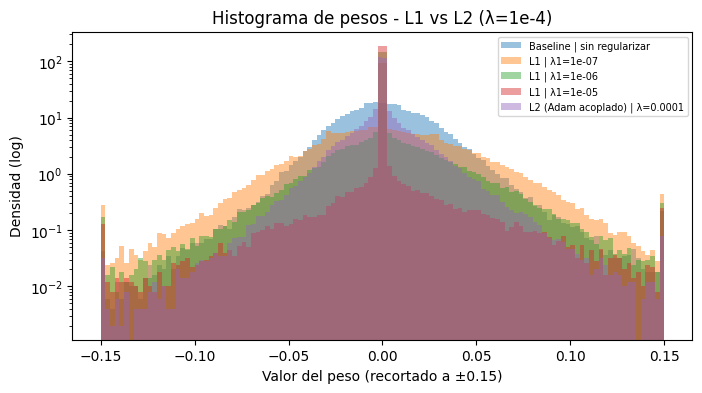

In [ ]:
L1_KEYS = [run_config("L1", f"λ1={lam:g}", l1_lambda=lam) for lam in [1e-7, 1e-6, 1e-5]]
display(summarize([BASE_KEY] + L1_KEYS).round(4))
plot_curves([BASE_KEY] + L1_KEYS, "L1")
plot_weight_hist([BASE_KEY] + L1_KEYS + [L2_KEYS[1]], "Histograma de pesos - L1 vs L2 (λ=1e-4)")

## 20. L1 + L2 (Elastic Net): barrido conjunto

🔧 **Corrección:** antes se probaba un solo punto. Ahora se barre una grilla 3×3, con λ₁ ∈ {1e-7, 1e-6, 1e-5} (L1 en la loss) y λ₂ ∈ {1e-5, 1e-4, 1e-3} (`weight_decay` de Adam, sin bias). Para cada combinación se reporta `val_acc` final, `mean|w|` y `frac_casi_cero`, y se grafican como mapas de calor.

**Qué hace este código:** corre las 9 combinaciones y arma tres tablas pivote (λ₁ en filas, λ₂ en columnas).

listo: L1+L2 | λ1=1e-07, λ2=1e-05
listo: L1+L2 | λ1=1e-07, λ2=0.0001
listo: L1+L2 | λ1=1e-07, λ2=0.001
listo: L1+L2 | λ1=1e-06, λ2=1e-05
listo: L1+L2 | λ1=1e-06, λ2=0.0001
listo: L1+L2 | λ1=1e-06, λ2=0.001
listo: L1+L2 | λ1=1e-05, λ2=1e-05
listo: L1+L2 | λ1=1e-05, λ2=0.0001
listo: L1+L2 | λ1=1e-05, λ2=0.001


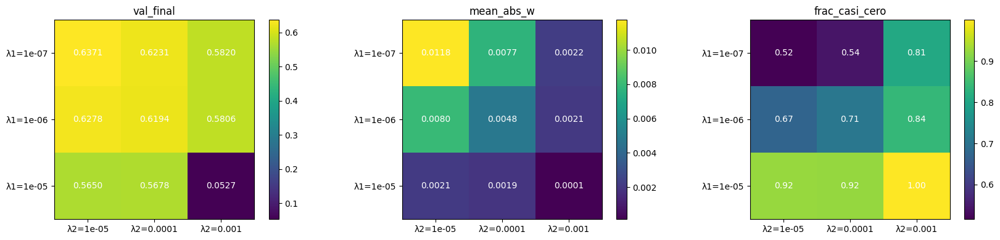

Baseline val_final: 0.6645


,val_final,val_final_std,val_mejor,epoca_mejor,brecha,val_loss_min,mean_abs_w,frac_casi_cero,max_norma_fila,s_por_epoca,ruido_batch,rugos_train,rugos_val,p_vs_base
config,,,,,,,,,,,,,,
"L1+L2 | λ1=1e-07, λ2=1e-05",0.6371,0.0027,0.6581,3.0000,0.3376,1.2171,0.0118,0.5159,3.6990,1.4326,0.7288,0.0950,0.0281,0.0005
"L1+L2 | λ1=1e-07, λ2=0.0001",0.6231,0.0091,0.6410,10.6667,0.3301,1.2525,0.0077,0.5431,3.3856,1.4337,0.5085,0.0935,0.0350,0.0091
"L1+L2 | λ1=1e-07, λ2=0.001",0.5820,0.0117,0.5908,15.0000,0.3770,1.5520,0.0022,0.8072,3.5174,1.4351,0.3910,0.0640,0.0476,0.0041
"L1+L2 | λ1=1e-06, λ2=1e-05",0.6278,0.0127,0.6409,11.3333,0.3345,1.2601,0.0080,0.6713,3.7877,1.4332,0.5917,0.0932,0.0342,0.0308
"L1+L2 | λ1=1e-06, λ2=0.0001",0.6194,0.0072,0.6356,13.0000,0.3466,1.3028,0.0048,0.7079,3.3769,1.4349,0.5817,0.0899,0.0367,0.0029
"L1+L2 | λ1=1e-06, λ2=0.001",0.5806,0.0127,0.5827,19.3333,0.3792,1.5901,0.0021,0.8390,3.5730,1.4350,0.3959,0.0584,0.0463,0.0051
"L1+L2 | λ1=1e-05, λ2=1e-05",0.5650,0.0353,0.5703,17.0000,0.4030,1.6839,0.0021,0.9245,4.5311,1.4361,0.6041,0.0638,0.0467,0.0385
"L1+L2 | λ1=1e-05, λ2=0.0001",0.5678,0.0254,0.5699,17.3333,0.3945,1.6977,0.0019,0.9227,4.4448,1.4356,0.5176,0.0645,0.0472,0.0207
"L1+L2 | λ1=1e-05, λ2=0.001",0.0527,0.0003,0.0530,2.0000,-0.0051,2.9902,0.0001,1.0000,0.3370,1.4344,0.0038,0.0024,0.0004,0.0000


In [ ]:
L1_GRID, L2_GRID = [1e-7, 1e-6, 1e-5], [1e-5, 1e-4, 1e-3]
L1L2_KEYS = {}
for l1 in L1_GRID:
    for l2 in L2_GRID:
        L1L2_KEYS[(l1, l2)] = run_config("L1+L2", f"λ1={l1:g}, λ2={l2:g}", l1_lambda=l1, weight_decay=l2)

s = summarize(list(L1L2_KEYS.values()))
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, col, fmt in zip(axes, ["val_final", "mean_abs_w", "frac_casi_cero"], [".4f", ".4f", ".2f"]):
    mat = pd.DataFrame([[s.loc[L1L2_KEYS[(l1, l2)], col] for l2 in L2_GRID] for l1 in L1_GRID],
                       index=[f"λ1={x:g}" for x in L1_GRID], columns=[f"λ2={x:g}" for x in L2_GRID])
    im = ax.imshow(mat.values, cmap="viridis")
    ax.set_xticks(range(3)); ax.set_xticklabels(mat.columns); ax.set_yticks(range(3)); ax.set_yticklabels(mat.index)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, format(mat.values[i, j], fmt), ha="center", va="center", color="w")
    ax.set_title(col); plt.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()
print("Baseline val_final:", round(summarize([BASE_KEY]).loc[BASE_KEY, "val_final"], 4))
display(s.round(4))

**Análisis de pesos (18–20)**

| Configuración | val_acc final | p vs. base | brecha | mean\|w\| | pesos casi cero | norma máx. por fila |
|---|---|---|---|---|---|---|
| Baseline | 0,6645 ± 0,0033 | – | 0,310 | 0,0218 | 3,4 % | 7,9 |
| L2 Adam λ = 1e-5 | 0,6477 ± 0,0055 | 0,016 | 0,326 | 0,0150 | 38 % | 4,0 |
| L2 Adam λ = 1e-4 | 0,6287 ± 0,0045 | < 0,001 | 0,331 | 0,0079 | 52 % | 3,3 |
| L2 Adam λ = 1e-3 | 0,5849 ± 0,0042 | < 0,001 | 0,369 | 0,0023 | 80 % | 3,3 |
| AdamW λ = 1e-3 | 0,6633 ± 0,0020 | 0,63 | 0,311 | 0,0196 | 3,6 % | 6,9 |
| AdamW λ = 1e-2 | 0,6575 ± 0,0046 | 0,11 | 0,315 | 0,0233 | 3,2 % | 6,9 |
| AdamW λ = 1e-1 | 0,6580 ± 0,0049 | 0,14 | 0,317 | 0,0204 | 3,9 % | 7,8 |
| L1 λ₁ = 1e-7 | 0,6485 ± 0,0098 | 0,095 | 0,326 | 0,0157 | 47 % | 4,2 |
| L1 λ₁ = 1e-6 | 0,6297 ± 0,0119 | 0,029 | 0,340 | 0,0087 | 67 % | 4,0 |
| L1 λ₁ = 1e-5 | 0,5758 ± 0,0267 | 0,028 | 0,388 | 0,0023 | 91 % | 4,7 |

- **L2 con Adam (acoplado).** `mean|w|` baja de 0,0218 (base) a 0,0150, 0,0079 y 0,0023 a medida que sube λ. Lo llamativo es la fracción de pesos casi cero: 38 %, 52 % y 80 %, contra 3,4 % del caso base. Un L2 "de libro" no debería generar esparsidad, porque su gradiente λw se achica cuando w → 0. Acá sí la genera, y es por el acoplamiento con Adam: el término λw pasa por la normalización 1/√v̂. Muchos pesos de la primera capa están conectados a términos de TF-IDF que casi nunca aparecen en un batch, así que el gradiente de la loss respecto de esos pesos es casi siempre cero y v̂ queda dominado por (λw)². Para esos pesos, el paso de Adam es ≈ η·signo(w) sin importar lo chico que sea λ, y los lleva a cero en pocos pasos. Es justamente el problema que motivó AdamW: con el L2 acoplado, el decaimiento efectivo depende de la historia de gradientes de cada peso.
- **AdamW (desacoplado).** No cambió nada: `mean|w|` entre 0,0196 y 0,0233, ≈3,5 % de pesos casi cero, y val_acc igual a la del baseline (p entre 0,11 y 0,63). La cuenta lo explica: el decaimiento por paso es η·λ·|w| ≈ 10⁻³ · 0,1 · 0,02 = 2·10⁻⁶, contra pasos de Adam del orden de η = 10⁻³. Con lr = 1e-3, AdamW necesitaría λ del orden de 1 o más para que se note.
- **L1.** `mean|w|` baja a 0,0157, 0,0087 y 0,0023, y la fracción de pesos casi cero sube a 47 %, 67 % y 91 %. Para un `mean|w|` parecido, L1 deja más pesos en cero que L2: con `mean|w|` = 0,0023 en los dos casos (λ₁ = 1e-5 y λ₂ = 1e-3), L1 tiene 91 % de pesos casi cero y L2 tiene 80 %. Es la esparsidad de Lasso que muestra la cátedra ("todos los pesos contribuyen de igual manera al costo → W esparsos").
- **L1+L2.** El mapa de pesos casi cero depende sobre todo de λ₁ (las filas): 52–81 % con λ₁ = 1e-7, 67–84 % con 1e-6 y 92–100 % con 1e-5. Con λ₁ = 1e-5 y λ₂ = 1e-3 la red colapsa: todos los pesos en cero y val_acc de 0,053, que es el azar para 20 clases. La mejor combinación (λ₁ = 1e-7, λ₂ = 1e-5) dio 0,6371, también por debajo del baseline (p < 0,001).
- **Accuracy.** Ninguna configuración de L1, L2 o L1+L2 superó al baseline. Con 3 semillas, casi todas las diferencias negativas son significativas (p < 0,05); las excepciones son L1 con λ₁ = 1e-7 (p = 0,095) y las tres de AdamW, que empatan con el baseline. La brecha train−val tampoco se achica, sino que sube de 0,310 a entre 0,326 y 0,388. Es decir, achicar los pesos no le sacó sobreajuste a la red, solo le sacó capacidad para ajustar validación. La conclusión de la entrega anterior ("L1/L2 no ayudan") ahora sí está respaldada con semillas.
- **Valor de los pesos y overfitting.** La cátedra señala que *"el valor de los pesos aumenta significativamente cuando hay overfitting"*. En el baseline, la norma máxima de una fila llega a 7,9, y L1 y L2 la bajan a 3,3–4,7. Achicar esos pesos no alcanza para mejorar la validación.

## 21. Dropout

Dropout después de cada activación, con $p$ = probabilidad de **apagar** una neurona (convención de PyTorch). Ojo: en el paper original de Srivastava et al., $p$ es la probabilidad de **retener**. El rango recomendado en clase (20 %–50 % de apagado) corresponde a esta convención. Se barre $p \in \{0.2, 0.5, 0.7, 0.8\}$.

**Qué hace este código:** corre el barrido y muestra la tabla con métricas de ruido, las curvas de validación y las de train vs. val para el baseline y para p = 0.5.

listo: Dropout | p=0.2
listo: Dropout | p=0.5
listo: Dropout | p=0.7
listo: Dropout | p=0.8


,val_final,val_final_std,val_mejor,epoca_mejor,brecha,val_loss_min,mean_abs_w,frac_casi_cero,max_norma_fila,s_por_epoca,ruido_batch,rugos_train,rugos_val,p_vs_base
config,,,,,,,,,,,,,,
Baseline | sin regularizar,0.6645,0.0033,0.6717,7.0000,0.3098,1.1833,0.0218,0.0336,7.9069,1.0764,0.7272,0.0940,0.0248,NaN
Dropout | p=0.2,0.6665,0.0003,0.6729,6.0000,0.3077,1.1408,0.0237,0.0321,5.5636,1.1176,0.7303,0.0948,0.0240,0.3942
Dropout | p=0.5,0.6777,0.0064,0.6838,15.3333,0.2916,1.1414,0.0263,0.0306,4.6930,1.1188,0.6553,0.0946,0.0366,0.0494
Dropout | p=0.7,0.7047,0.0067,0.7081,19.3333,0.2539,1.1138,0.0279,0.0324,4.6738,1.1199,0.6503,0.0821,0.0649,0.0029
Dropout | p=0.8,0.7147,0.0003,0.7156,18.0000,0.1848,1.0724,0.0290,0.0347,4.8187,1.1208,0.3700,0.0541,0.0676,0.0014


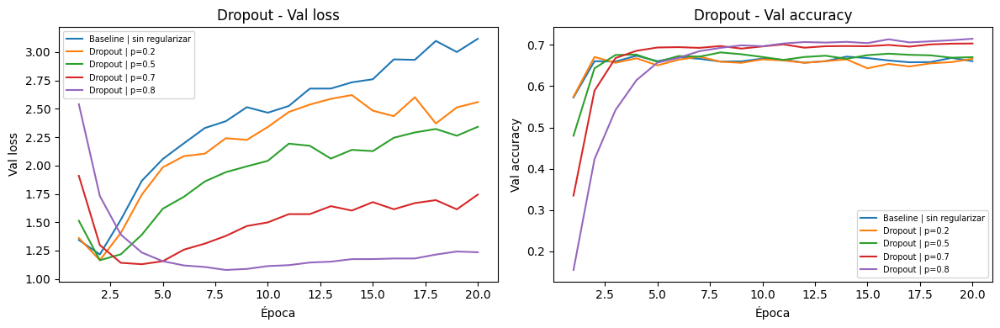

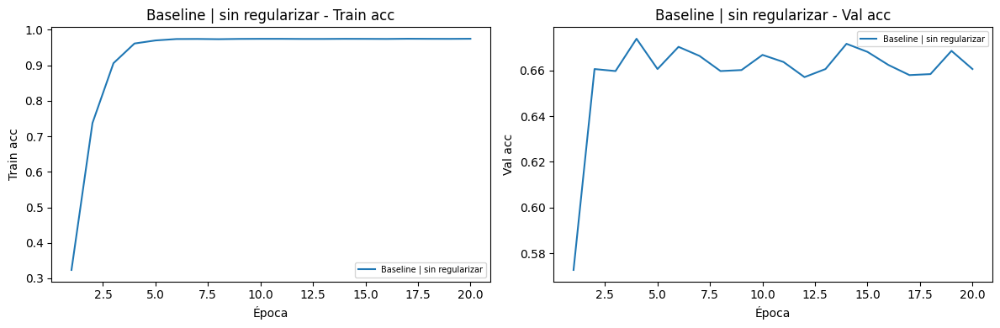

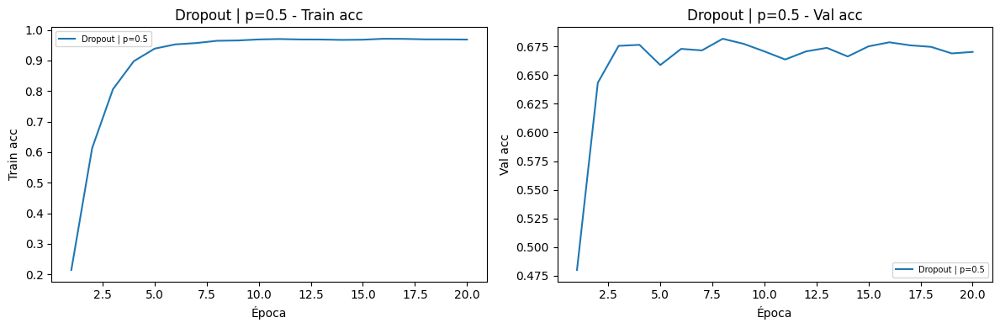

In [ ]:
DO_KEYS = [run_config("Dropout", f"p={p}", model_kwargs={"dropout_rate": p}) for p in [0.2, 0.5, 0.7, 0.8]]
display(summarize([BASE_KEY] + DO_KEYS).round(4))
plot_curves([BASE_KEY] + DO_KEYS, "Dropout")
for k in [BASE_KEY, DO_KEYS[1]]:
    plot_curves([k], k, (("train_acc", "Train acc"), ("val_acc", "Val acc")))

**Análisis de Dropout**

| p | val_acc final | p vs. base | brecha | val_loss mínima | época de la mejor val | mean\|w\| | norma máx. por fila |
|---|---|---|---|---|---|---|---|
| 0 (base) | 0,6645 ± 0,0033 | – | 0,310 | 1,183 | 7,0 | 0,0218 | 7,9 |
| 0,2 | 0,6665 ± 0,0003 | 0,39 | 0,308 | 1,141 | 6,0 | 0,0237 | 5,6 |
| 0,5 | 0,6777 ± 0,0064 | 0,049 | 0,292 | 1,141 | 15,3 | 0,0263 | 4,7 |
| 0,7 | 0,7047 ± 0,0067 | 0,003 | 0,254 | 1,114 | 19,3 | 0,0279 | 4,7 |
| 0,8 | **0,7147 ± 0,0003** | 0,001 | 0,185 | 1,072 | 18,0 | 0,0290 | 4,8 |

- **Dropout es, junto con BatchNorm, la técnica que más ayuda.** La mejora crece con p: con 0,2 no se distingue del baseline, y con 0,8 sube 5,0 pp y la brecha baja de 0,310 a 0,185. En el gráfico se ve la diferencia: la val_loss del baseline sube de 1,18 a 3,1, y con p = 0,8 se queda entre 1,07 y 1,25 durante las 20 épocas.
- **Por qué un p alto funciona aunque esté fuera del rango recomendado (20–50 %).** La cátedra también recomienda usar dropout con *"una red grande, muchos parámetros"*, y este es un caso extremo: 12,4 millones de parámetros para 9051 documentos de train, cuando el barrido de capacidad mostró que la mejor red era 1×64. Con p = 0,8 quedan activas en promedio el 20 % de las neuronas, unas 205 por capa, que es del orden del tamaño que funciona bien en este problema. El dropout alto compensa el sobredimensionamiento. En el rango probado no llegamos a ver underfitting: con p = 0,8 la train_acc final sigue en ≈0,90. Con p = 0,7 y 0,8 la mejor época es la 18–19 de 20, y la val_acc sigue subiendo al final: con dropout hacen falta más épocas, igual que en el ejemplo de la cátedra, donde hubo que pasar de 2000 a 4000.
- **Pesos.** Dropout no achica los pesos: `mean|w|` sube de 0,0218 a 0,0290 a medida que crece p. No penaliza la magnitud, sino que obliga a cada neurona a funcionar sin co-adaptarse con las demás, y los pesos crecen para compensar el apagado. Lo que sí baja es la norma máxima por fila (de 7,9 a 4,7–5,6): ninguna neurona concentra pesos muy grandes. Es lo que la cátedra pide mirar en la escala de los histogramas de pesos.
- **Ruido.** La cátedra dice que con dropout *"el accuracy en train es mucho más ruidoso que en validación"*. En nuestras curvas por época no se ve: la de train_acc con p = 0,5 es suave, y la de val_acc oscila más (entre 0,66 y 0,68). Las métricas numéricas tampoco lo muestran claramente, y revisándolas encontré dos problemas en cómo las definí. `rugos_train` y `rugos_val` (desvío de las diferencias época a época) están dominadas por los saltos de las primeras épocas, cuando la curva todavía sube. Y `ruido_batch` es un coeficiente de variación (desvío/media), así que baja cuando sube la loss media aunque el ruido absoluto no cambie: con p = 0,8 baja a 0,37, pero eso refleja que la loss de train es más alta, no que haya menos ruido. Creo que el ruido en train que describe la cátedra está a nivel de batch y se pierde al promediar la accuracy de una época entera.
- **Tiempo.** Con las mismas 20 épocas, dropout tarda 1,12 s por época contra 1,08 s del baseline (+4 %), el costo de generar las máscaras. La afirmación de la entrega anterior ("más rápido que el base") salía de comparar 15 épocas contra 40.

### 21.1 Dropout + learning rate con SGD + momentum (corregido)

La recomendación de clase (Srivastava et al., 2014) para dropout es **subir el lr (×10 a ×100), usar momentum alto (entre 0,9 y 0,99) y combinarlo con max-norm** (valores de c en el orden de 4 o 5). El motivo: dropout mete ruido en el gradiente, que el momentum alto promedia, y el lr alto compensa que cada sub-red aprenda menos por paso. La tercera pieza es clave: **max-norm** acota la norma de los pesos de cada neurona, y es lo que impide que un lr alto haga crecer los pesos sin control.

En la entrega original se subió el lr ×10 **sin max-norm** y el resultado fue peor (lr = 0.1: 0.559 vs. lr = 0.01: 0.590). Hay tres motivos posibles:
1. **Faltaba max-norm.** Con lr = 0.1 y momentum 0.9, el paso efectivo es $\eta/(1-\mu) = 1$, es decir, 10 veces el de lr = 0.01. Sin un tope, los pesos crecen y la loss oscila; justamente eso se veía en las curvas (train_loss subiendo y bajando).
2. **Momentum 0,9**, en el borde inferior del rango recomendado.
3. **Un único factor ×10** sin probar intermedios.

Para analizarlo se corre una grilla: lr ∈ {0.01 (×1), 0.05 (×5), 0.1 (×10)} × {dropout solo, dropout + max-norm c = 3}, con dropout p = 0.5, SGD con momentum 0.9 y el mismo número de épocas que el resto. Una sola curva no permite ver si un lr diverge u oscila, así que también se mira `rugos_train` y `max_norma_fila`.

**Qué hace este código:** corre las 6 combinaciones y grafica `train_loss` y `val_acc` por época.

listo: Dropout+SGD | lr=0.01
listo: Dropout+SGD | lr=0.01, max-norm c=3
listo: Dropout+SGD | lr=0.05
listo: Dropout+SGD | lr=0.05, max-norm c=3
listo: Dropout+SGD | lr=0.1
listo: Dropout+SGD | lr=0.1, max-norm c=3


,val_final,val_final_std,val_mejor,epoca_mejor,brecha,val_loss_min,mean_abs_w,frac_casi_cero,max_norma_fila,s_por_epoca,ruido_batch,rugos_train,rugos_val,p_vs_base
config,,,,,,,,,,,,,,
Baseline | sin regularizar,0.6645,0.0033,0.6717,7.0,0.3098,1.1833,0.0218,0.0336,7.9069,1.0764,0.7272,0.0940,0.0248,NaN
Dropout+SGD | lr=0.01,0.1195,0.0234,0.1195,20.0,-0.0341,2.9800,0.0068,0.0883,0.6842,0.8137,0.0043,0.0042,0.0159,0.0005
"Dropout+SGD | lr=0.01, max-norm c=3",0.1195,0.0234,0.1195,20.0,-0.0341,2.9800,0.0068,0.0883,0.6842,0.9557,0.0043,0.0042,0.0159,0.0005
Dropout+SGD | lr=0.05,0.4484,0.0360,0.4660,17.0,-0.0445,1.5878,0.0095,0.0783,4.4533,0.8056,0.1028,0.0207,0.0384,0.0087
"Dropout+SGD | lr=0.05, max-norm c=3",0.4270,0.0282,0.4739,18.0,-0.0370,1.5674,0.0094,0.0785,3.0000,0.9601,0.0908,0.0212,0.0362,0.0042
Dropout+SGD | lr=0.1,0.3447,0.0525,0.3715,19.0,-0.0448,1.8413,0.0093,0.0811,9.3131,0.8118,0.0759,0.0154,0.0347,0.0086
"Dropout+SGD | lr=0.1, max-norm c=3",0.1620,0.0233,0.2850,13.0,-0.0351,2.1476,0.0090,0.0822,3.0000,0.9581,0.0462,0.0183,0.0426,0.0006


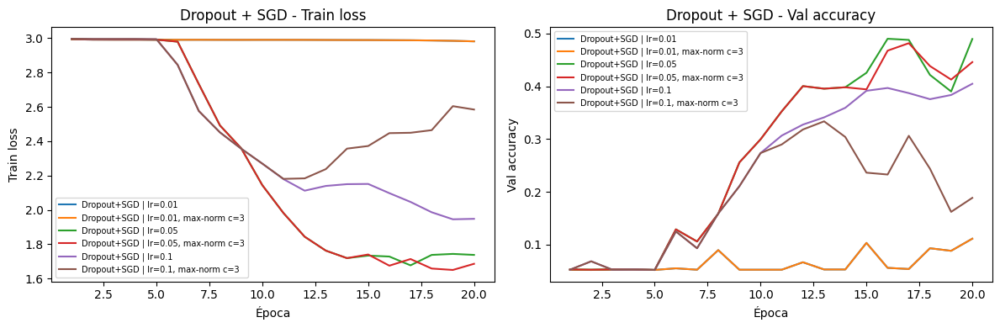

In [ ]:
DOLR_KEYS = []
for lr in [0.01, 0.05, 0.1]:
    for mn in [None, 3.0]:
        label = f"lr={lr:g}" + (", max-norm c=3" if mn else "")
        DOLR_KEYS.append(run_config("Dropout+SGD", label, model_kwargs={"dropout_rate": 0.5},
                                    opt="sgd", lr=lr, momentum=0.9, max_norm=mn))
display(summarize([BASE_KEY] + DOLR_KEYS).round(4))
plot_curves(DOLR_KEYS, "Dropout + SGD", (("train_loss", "Train loss"), ("val_acc", "Val accuracy")))

**Análisis**

| lr | sin max-norm | con max-norm c = 3 |
|---|---|---|
| 0,01 (×1) | 0,1195 ± 0,0234 | 0,1195 ± 0,0234 |
| 0,05 (×5) | **0,4484 ± 0,0360** | 0,4270 ± 0,0282 |
| 0,1 (×10) | 0,3447 ± 0,0525 | 0,1620 ± 0,0233 |

- **Con lr = 0,01 la red no aprende en 20 épocas.** La train_loss se queda en ≈2,99 ≈ ln 20, que es la entropía de adivinar al azar entre 20 clases, y la val_acc en 0,12. Es un plateau inicial: con 3 capas ReLU, la inicialización por defecto de PyTorch y entradas de norma 1 en 10000 dimensiones, la señal se achica capa a capa y al principio los gradientes son muy chicos. Es lo que la cátedra marca en las reglas de entrenamiento ("distinguir esto de que el modelo no aprende, por ejemplo learning rate demasiado grande o demasiado chico") y en la parte de inicialización (arrancar en una zona de la activación donde la derivada sea significativa). Con max-norm da exactamente lo mismo porque la restricción nunca se activa: la norma máxima por fila es 0,68, menor que 3. Sirve como control.
- **Subir el lr ×5 es lo que mejor funciona** (0,4484): la red sale del plateau alrededor de la época 5 y después aprende rápido. Coincide con lo que hizo la cátedra en su ejemplo, donde subió el lr de 0,1 a 0,5 (×5). Con ×10 sale del plateau igual de rápido, pero después es inestable: la train_loss deja de bajar en la época 12 y oscila, y termina peor (0,3447, con 5 pp de desvío entre semillas).
- **Max-norm no ayudó.** Con ×5 da lo mismo (la diferencia es menor que el desvío), y con ×10 empeora mucho (0,1620): la train_loss vuelve a subir desde la época 11. Esperaba lo contrario, porque la recomendación de la cátedra es combinar lr alto con max-norm, y no tengo una explicación cerrada. Una hipótesis es la interacción con el momentum: el buffer de momentum (0,9) sigue empujando en la dirección que max-norm recorta en cada paso, y con lr alto eso genera oscilaciones. Además usamos c = 3, por debajo del 4 o 5 que recomienda la cátedra.
- **¿Por qué en la entrega anterior lr ×10 dio peor que ×1?** Con estos resultados, creo que se combinaban dos efectos. ×10 es demasiado agresivo para esta red (acá también da peor que ×5), y con lr = 0,01 la red necesita muchas épocas para salir del plateau: en la corrida anterior (70 épocas) le alcanzaron y acá (20 épocas) no. La recomendación de la cátedra sí se cumple con el factor ×5: hay un lr óptimo entre los dos extremos.
- **SGD contra Adam.** Todas las corridas con SGD quedan muy por debajo de Adam con las mismas épocas (la mejor da 0,45, contra 0,66 del baseline). Además tienen brecha negativa: la train_acc queda por debajo de la val_acc, porque en train el dropout está activo y en validación no. Con 20 épocas están en underfitting. SGD tarda 0,81 s por época, contra 1,08 s de Adam (no mantiene estimadores de momentos de segundo orden), pero necesita muchas más épocas.

## 22. 🔧 Max-norm

Restricción dura sobre la norma L2 de los pesos que entran a cada neurona: después de cada paso, $\mathbf{w}_i \leftarrow \mathbf{w}_i \cdot \min(1, c/\|\mathbf{w}_i\|_2)$. A diferencia de L2, **no** empuja los pesos hacia cero mientras estén dentro de la bola de radio $c$: solo actúa cuando la norma la supera. Por eso permite lr altos sin que los pesos exploten. La cátedra recomienda valores de $c$ en el orden de 4 o 5, combinado con dropout (Srivastava et al. usan entre 3 y 4).

La escala natural de las filas acá: con la inicialización de PyTorch, cada fila de la primera capa tiene norma $\approx \sqrt{d/(3d)} \approx 0.58$ ($d$ = cantidad de features). Por eso, además de $c$ = 3 y 4, se prueban $c$ = 0.5 y 1, que sí restringen desde el principio. Se prueba max-norm solo y combinado con dropout 0.5 (Adam, lr = 1e-3).

**Qué hace este código:** corre el barrido de c, la combinación con dropout, y compara con el baseline y con dropout 0.5 solo. `max_norma_fila` permite verificar que la restricción se cumple.

listo: Max-norm | c=0.5
listo: Max-norm | c=1.0
listo: Max-norm | c=3.0
listo: Max-norm | c=4.0
listo: Max-norm+Dropout | c=1.0, p=0.5
listo: Max-norm+Dropout | c=3.0, p=0.5


,val_final,val_final_std,val_mejor,epoca_mejor,brecha,val_loss_min,mean_abs_w,frac_casi_cero,max_norma_fila,s_por_epoca,ruido_batch,rugos_train,rugos_val,p_vs_base
config,,,,,,,,,,,,,,
Baseline | sin regularizar,0.6645,0.0033,0.6717,7.0000,0.3098,1.1833,0.0218,0.0336,7.9069,1.0764,0.7272,0.0940,0.0248,NaN
Dropout | p=0.5,0.6777,0.0064,0.6838,15.3333,0.2916,1.1414,0.0263,0.0306,4.6930,1.1188,0.6553,0.0946,0.0366,0.0494
Max-norm | c=0.5,0.4647,0.0102,0.4965,14.6667,0.0386,1.6121,0.0053,0.1725,0.5000,1.2298,0.0992,0.0404,0.0271,0.0003
Max-norm | c=1.0,0.6441,0.0166,0.6544,12.0000,0.2792,1.2297,0.0094,0.1438,1.0000,1.2290,0.3703,0.0804,0.0219,0.1634
Max-norm | c=3.0,0.6469,0.0161,0.6718,7.3333,0.3106,1.1833,0.0235,0.0331,3.0000,1.2310,0.6888,0.0947,0.0244,0.1953
Max-norm | c=4.0,0.6600,0.0038,0.6720,10.0000,0.3146,1.1833,0.0215,0.0339,4.0000,1.2336,0.7331,0.0939,0.0233,0.2026
"Max-norm+Dropout | c=1.0, p=0.5",0.6472,0.0052,0.6541,14.0000,0.2339,1.1892,0.0095,0.1576,1.0000,1.2631,0.3035,0.0807,0.0318,0.0122
"Max-norm+Dropout | c=3.0, p=0.5",0.6701,0.0045,0.6815,15.3333,0.2973,1.1414,0.0242,0.0332,3.0000,1.2698,0.6119,0.0946,0.0366,0.1649


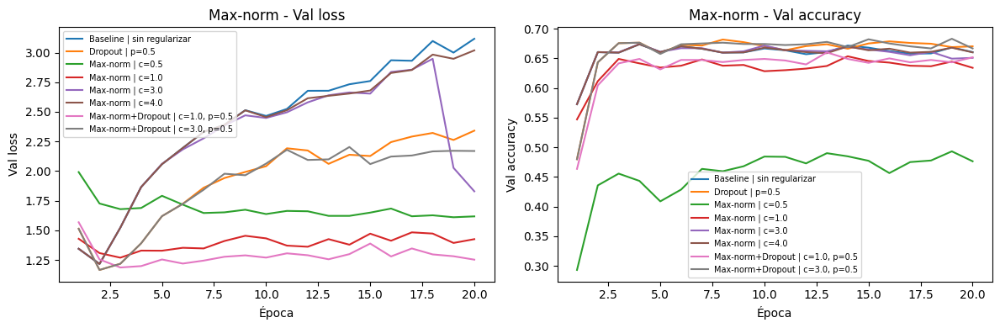

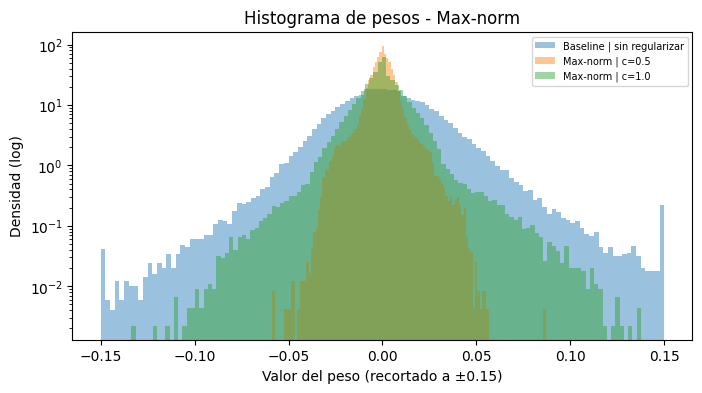

In [ ]:
MN_KEYS = [run_config("Max-norm", f"c={c}", max_norm=c) for c in [0.5, 1.0, 3.0, 4.0]]
MN_DO_KEYS = [run_config("Max-norm+Dropout", f"c={c}, p=0.5", model_kwargs={"dropout_rate": 0.5}, max_norm=c)
              for c in [1.0, 3.0]]
display(summarize([BASE_KEY, DO_KEYS[1]] + MN_KEYS + MN_DO_KEYS).round(4))
plot_curves([BASE_KEY, DO_KEYS[1]] + MN_KEYS + MN_DO_KEYS, "Max-norm")
plot_weight_hist([BASE_KEY, MN_KEYS[0], MN_KEYS[1]], "Histograma de pesos - Max-norm")

**Análisis de max-norm**

| Configuración | val_acc final | p vs. base | brecha | val_loss mínima | mean\|w\| | pesos casi cero |
|---|---|---|---|---|---|---|
| Baseline | 0,6645 ± 0,0033 | – | 0,310 | 1,183 | 0,0218 | 3,4 % |
| c = 0,5 | 0,4647 ± 0,0102 | < 0,001 | 0,039 | 1,612 | 0,0053 | 17 % |
| c = 1 | 0,6441 ± 0,0166 | 0,16 | 0,279 | 1,230 | 0,0094 | 14 % |
| c = 3 | 0,6469 ± 0,0161 | 0,20 | 0,311 | 1,183 | 0,0235 | 3,3 % |
| c = 4 | 0,6600 ± 0,0038 | 0,20 | 0,315 | 1,183 | 0,0215 | 3,4 % |
| Dropout 0,5 solo | 0,6777 ± 0,0064 | 0,049 | 0,292 | 1,141 | 0,0263 | 3,1 % |
| c = 3 + dropout 0,5 | 0,6701 ± 0,0045 | 0,16 | 0,297 | 1,141 | 0,0242 | 3,3 % |

- **La restricción se cumple:** la norma máxima por fila termina exactamente en c en todas las corridas. En el baseline esa norma llega a 7,9, así que con c = 3 y 4 la restricción se activa, pero recién después de varias épocas. Con c ≥ 3 la val_loss mínima es idéntica a la del baseline (1,1833): hasta la época del mínimo ninguna fila había superado c y el entrenamiento fue exactamente el mismo.
- **Accuracy:** con c = 1, 3 y 4 no se distingue del baseline (p entre 0,16 y 0,20). Con c = 0,5 la red queda en underfitting: 0,4647 y brecha de 0,039. Como las entradas tienen norma 1 (normalización L2), c = 0,5 acota cada pre-activación de la primera capa a |w·x| ≤ 0,5, y la red no alcanza a representar el problema.
- **Max-norm + dropout** (c = 3, p = 0,5) da 0,6701, contra 0,6777 de dropout solo: no mejora. La cátedra observa que con max-norm el entrenamiento es *"mucho más estable (menos sensible al valor de dropout)"*, pero también que tuvo que subir las épocas a 10.000. Con 20 épocas no llegamos a ese régimen.
- **Pesos:** con c = 0,5 y 1, `mean|w|` baja a 0,0053 y 0,0094 y aparecen entre 14 y 17 % de pesos casi cero, porque al dividir toda la fila los pesos que ya eran chicos quedan todavía más chicos. Con c = 3 y 4 la distribución es casi igual a la del baseline.
- **Tiempo:** 1,23 s por época contra 1,08 s del baseline (+14 %), por el `renorm` de todas las matrices después de cada paso.

## 23. Batch Normalization

BN normaliza las pre-activaciones por mini-batch. Como se vio en clase, **no** es estrictamente una técnica de regularización sino de estabilización y aceleración del entrenamiento. Su efecto regularizador es un subproducto del ruido en las estadísticas (media y varianza) de cada mini-batch: con batch más chico, las estadísticas son más ruidosas y la regularización algo mayor.

🔧 El baseline usa batch 64, así que la comparación limpia es **BN con batch 64 vs. baseline**. Además se prueban batch 32 y 128 **con y sin BN**, para separar el efecto de BN del efecto del tamaño de batch, que es el control que ya estaba en la entrega original, ahora con semillas.

**Qué hace este código:** corre BN con los tres tamaños de batch y los controles sin BN con 32 y 128. Grafica las curvas y la loss por batch de la última época (ruido).

listo: BatchNorm | bs=32
listo: BatchNorm | bs=64
listo: BatchNorm | bs=128
listo: Control sin BN | bs=32
listo: Control sin BN | bs=128


,val_final,val_final_std,val_mejor,epoca_mejor,brecha,val_loss_min,mean_abs_w,frac_casi_cero,max_norma_fila,s_por_epoca,ruido_batch,rugos_train,rugos_val,p_vs_base
config,,,,,,,,,,,,,,
Baseline | sin regularizar,0.6645,0.0033,0.6717,7.0000,0.3098,1.1833,0.0218,0.0336,7.9069,1.0764,0.7272,0.0940,0.0248,NaN
BatchNorm | bs=32,0.6720,0.0049,0.6907,4.3333,0.2944,1.0816,0.0355,0.0183,4.8624,2.0547,0.9506,0.0682,0.0122,0.1008
BatchNorm | bs=64,0.6894,0.0054,0.7028,2.3333,0.2852,1.0397,0.0213,0.0318,2.9391,1.1538,0.7281,0.0725,0.0134,0.0045
BatchNorm | bs=128,0.7176,0.0046,0.7184,12.0000,0.2569,1.1054,0.0100,0.0667,1.1657,0.7050,0.4969,0.0728,0.0068,0.0002
Control sin BN | bs=32,0.6612,0.0102,0.6717,8.3333,0.3133,1.1926,0.0273,0.0302,7.4869,1.9204,1.0346,0.0894,0.0192,0.6458
Control sin BN | bs=128,0.6562,0.0087,0.6637,11.6667,0.3182,1.1842,0.0180,0.0373,5.7932,0.6776,0.4923,0.0990,0.0325,0.2368


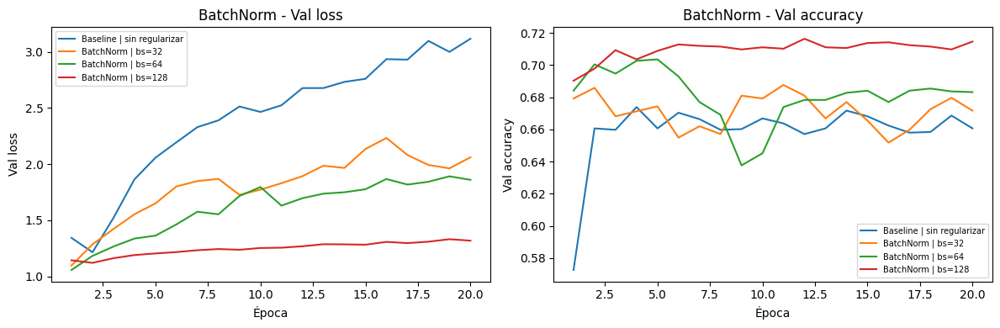

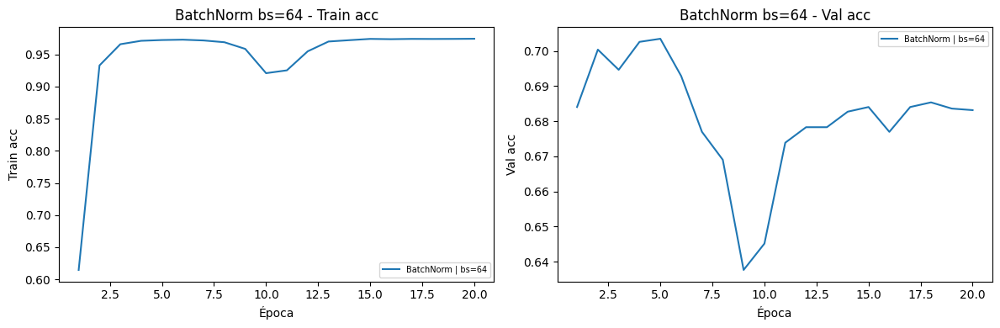

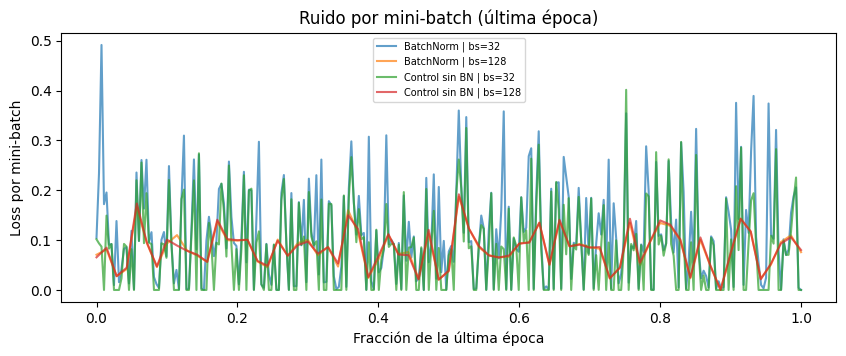

In [ ]:
BN_KEYS = {bs: run_config("BatchNorm", f"bs={bs}", model_kwargs={"use_batchnorm": True}, batch_size=bs)
           for bs in [32, 64, 128]}
NOBN_KEYS = {bs: run_config("Control sin BN", f"bs={bs}", batch_size=bs) for bs in [32, 128]}
NOBN_KEYS[64] = BASE_KEY
display(summarize([BASE_KEY] + list(BN_KEYS.values()) + [NOBN_KEYS[32], NOBN_KEYS[128]]).round(4))
plot_curves([NOBN_KEYS[64]] + list(BN_KEYS.values()), "BatchNorm")
plot_curves([BN_KEYS[64]], "BatchNorm bs=64", (("train_acc", "Train acc"), ("val_acc", "Val acc")))

fig, ax = plt.subplots(figsize=(10, 3.5))
for k in [BN_KEYS[32], BN_KEYS[128], NOBN_KEYS[32], NOBN_KEYS[128]]:
    bl = reg_curves[k]["batch_losses_last"]
    ax.plot(np.linspace(0, 1, len(bl)), bl, label=k, alpha=0.7)
ax.set_xlabel("Fracción de la última época"); ax.set_ylabel("Loss por mini-batch"); ax.legend(fontsize=7)
ax.set_title("Ruido por mini-batch (última época)"); plt.show()

### 23.1 🔧 BatchNorm permite un learning rate más alto

Como se vio en clase, BN reduce la dependencia de cada capa respecto de la escala de las anteriores: la salida de $\mathrm{BN}(Wx)$ no cambia si se escala $W$. Eso hace que el entrenamiento tolere lr más grandes sin divergir. Para probarlo se barre lr ∈ {1e-3, 5e-3, 1e-2, 3e-2} con Adam, **con y sin BN** (batch 64, todo lo demás igual).

**Qué hace este código:** corre las 8 combinaciones (lr = 1e-3 sin BN es el baseline y lr = 1e-3 con BN ya está en 23) y grafica `val_acc` final y `train_loss` contra el lr.

listo: BatchNorm | bs=64, lr=0.005
listo: Sin BN (lr alto) | lr=0.005
listo: BatchNorm | bs=64, lr=0.01
listo: Sin BN (lr alto) | lr=0.01
listo: BatchNorm | bs=64, lr=0.03
listo: Sin BN (lr alto) | lr=0.03


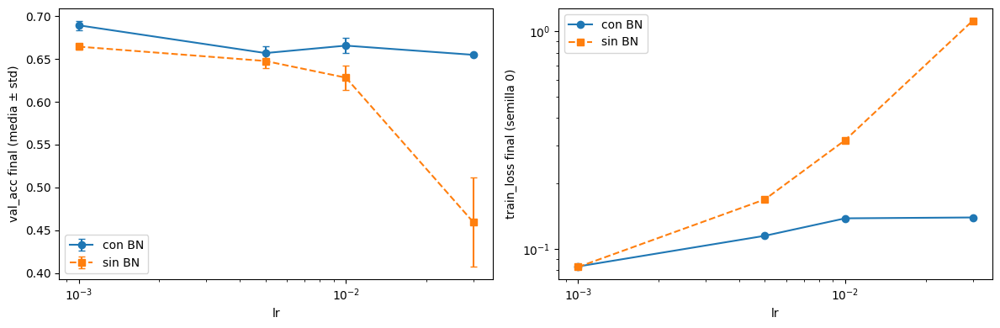

,val_final,val_final_std,val_mejor,epoca_mejor,brecha,val_loss_min,mean_abs_w,frac_casi_cero,max_norma_fila,s_por_epoca,ruido_batch,rugos_train,rugos_val,p_vs_base
config,,,,,,,,,,,,,,
Baseline | sin regularizar,0.6645,0.0033,0.6717,7.0000,0.3098,1.1833,0.0218,0.0336,7.9069,1.0764,0.7272,0.0940,0.0248,NaN
BatchNorm | bs=64,0.6894,0.0054,0.7028,2.3333,0.2852,1.0397,0.0213,0.0318,2.9391,1.1538,0.7281,0.0725,0.0134,0.0045
"BatchNorm | bs=64, lr=0.005",0.6569,0.0083,0.6830,2.0000,0.3077,1.1226,0.1008,0.0068,16.2721,1.1515,0.6403,0.0666,0.0095,0.2526
Sin BN (lr alto) | lr=0.005,0.6477,0.0084,0.6770,4.3333,0.3192,1.1877,0.0675,0.0326,20.3661,1.0871,1.0883,0.0900,0.0278,0.0596
"BatchNorm | bs=64, lr=0.01",0.6656,0.0088,0.6821,7.6667,0.2982,1.1315,0.1948,0.0036,34.5926,1.1482,0.6812,0.0700,0.0093,0.8439
Sin BN (lr alto) | lr=0.01,0.6282,0.0144,0.6620,3.0000,0.3329,1.2772,0.0773,0.0505,37.5430,1.0834,1.1437,0.0902,0.0222,0.0427
"BatchNorm | bs=64, lr=0.03",0.6549,0.0009,0.6692,9.6667,0.3054,1.1735,0.5280,0.0015,105.4925,1.1495,0.7111,0.0719,0.0112,0.0308
Sin BN (lr alto) | lr=0.03,0.4594,0.0523,0.6150,4.0000,0.2976,1.4875,0.1483,0.0575,138.6328,1.0828,0.6943,0.0761,0.0430,0.0207


In [ ]:
BNLR_KEYS = {(1e-3, True): BN_KEYS[64], (1e-3, False): BASE_KEY}
for lr in [5e-3, 1e-2, 3e-2]:
    BNLR_KEYS[(lr, True)] = run_config("BatchNorm", f"bs=64, lr={lr:g}", model_kwargs={"use_batchnorm": True}, lr=lr)
    BNLR_KEYS[(lr, False)] = run_config("Sin BN (lr alto)", f"lr={lr:g}", lr=lr)

s = summarize(list(BNLR_KEYS.values()))
lrs = [1e-3, 5e-3, 1e-2, 3e-2]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for bn, mk in [(True, "o-"), (False, "s--")]:
    keys = [BNLR_KEYS[(lr, bn)] for lr in lrs]
    axes[0].errorbar(lrs, s.loc[keys, "val_final"], yerr=s.loc[keys, "val_final_std"], fmt=mk, capsize=3,
                     label="con BN" if bn else "sin BN")
    axes[1].plot(lrs, [reg_curves[k]["train_loss"][-1] for k in keys], mk, label="con BN" if bn else "sin BN")
for ax, yl in zip(axes, ["val_acc final (media ± std)", "train_loss final (semilla 0)"]):
    ax.set_xscale("log"); ax.set_xlabel("lr"); ax.set_ylabel(yl); ax.legend()
axes[1].set_yscale("log")
plt.tight_layout(); plt.show()
display(s.round(4))

**Análisis de BatchNorm**

| batch | con BN | sin BN | diferencia |
|---|---|---|---|
| 32 | 0,6720 ± 0,0049 | 0,6612 ± 0,0102 | +1,1 pp |
| 64 | 0,6894 ± 0,0054 | 0,6645 ± 0,0033 (baseline) | +2,5 pp (p = 0,005) |
| 128 | **0,7176 ± 0,0046** | 0,6562 ± 0,0087 | +6,1 pp |

- **Efecto propio de BN.** Con el mismo batch, BN mejora en los tres casos, y con batch 64 (la comparación limpia contra el baseline) la diferencia es significativa. Sin BN, cambiar el batch casi no cambia el resultado (de 0,656 a 0,665), como ya habíamos visto en el control de la entrega anterior: la mejora no viene del batch. BN con batch 128 es la mejor configuración de toda la Parte 3.
- **Batch chico y regularización.** La cátedra explica el efecto regularizador de BN por el ruido en las estadísticas del mini-batch, que es mayor con batches chicos. Si eso fuera lo dominante, bs = 32 debería regularizar más. Acá pasó al revés: la mejora de BN crece con el batch. Creo que en este modelo pesa más el efecto de estabilización, que la cátedra señala como el principal (*"estrictamente BatchNormalization no es una técnica de regularización sino de aceleración del entrenamiento"*), que el ruido. Con batch 128 hay menos pasos por época y la norma de los pesos queda mucho más chica (norma máxima por fila de 1,2, contra 4,9 con bs = 32).
- **Convergencia.** Con batch 64, BN llega a su mejor validación en la época 2,3 en promedio, contra la 7 del baseline: es el efecto de aceleración.
- **Ruido.** Las curvas de validación con BN son mucho más suaves: `rugos_val` de 0,007 a 0,013, contra 0,019 a 0,033 sin BN. Coincide con lo que dice la cátedra (validación menos ruidosa). La loss por mini-batch de la última época depende del batch y no de BN: con batch 32 va de 0 a ≈0,5 y con 128 de 0 a ≈0,2, con y sin BN.
- **Validación por encima de train: no se observa.** La brecha con BN sigue siendo de 0,26 a 0,29. Con una red tan sobredimensionada el sobreajuste domina, y la train_acc llega a ≈0,97 igual.
- **lr más alto (23.1):**

| lr | con BN | sin BN |
|---|---|---|
| 0,001 | 0,6894 ± 0,0054 | 0,6645 ± 0,0033 |
| 0,005 | 0,6569 ± 0,0083 | 0,6477 ± 0,0084 |
| 0,01 | 0,6656 ± 0,0088 | 0,6282 ± 0,0144 |
| 0,03 | 0,6549 ± 0,0009 | 0,4594 ± 0,0523 |

  Sin BN, con lr = 0,03 el entrenamiento se rompe: val_acc de 0,46 con 5 pp de desvío entre semillas. Con BN y ese mismo lr la red sigue en 0,65, con un desvío casi nulo. BN sí permite trabajar con un lr 30 veces más alto sin que el entrenamiento se desestabilice. Lo que no pasó es que el lr alto mejore el resultado: el mejor sigue siendo lr = 0,001. Con Adam es esperable, porque ya adapta el paso de cada parámetro. Acá también se ve la invariancia de escala de BN: con lr alto los pesos crecen muchísimo (`mean|w|` de 0,53 y norma máxima por fila de 105 con lr = 0,03) sin que la salida se rompa, porque BN vuelve a normalizar las pre-activaciones. A medida que los pesos crecen, el paso efectivo se achica solo.
- **Pesos y tiempo.** Con batch 64 y lr = 0,001, BN deja `mean|w|` igual que el baseline (0,0213 contra 0,0218). Con el mismo batch, BN agrega entre 4 y 7 % de tiempo por época (1,15 s contra 1,08 s con batch 64). El batch pesa mucho más: 2,05 s por época con 32 contra 0,71 s con 128.

## 24. Comparación controlada: performance, tiempos, pesos y ruido

Todas las filas tienen **las mismas épocas** (`EPOCHS_REG`), el mismo split y las mismas semillas, así que el ranking es válido. Columnas: media de `val_acc` final ± desvío entre semillas, p-valor de Welch contra el baseline, brecha train−val, `mean|w|`, fracción de pesos casi cero, s/época y métricas de ruido.

**Qué hace este código:** arma la tabla de todas las configuraciones ordenada por `val_final` y grafica `val_final` con barras de error, `mean|w|` vs. `val_final` y s/época.

,val_final,val_final_std,val_mejor,epoca_mejor,brecha,val_loss_min,mean_abs_w,frac_casi_cero,max_norma_fila,s_por_epoca,ruido_batch,rugos_train,rugos_val,p_vs_base
config,,,,,,,,,,,,,,
BatchNorm | bs=128,0.7176,0.0046,0.7184,12.0000,0.2569,1.1054,0.0100,0.0667,1.1657,0.7050,0.4969,0.0728,0.0068,0.0002
Dropout | p=0.8,0.7147,0.0003,0.7156,18.0000,0.1848,1.0724,0.0290,0.0347,4.8187,1.1208,0.3700,0.0541,0.0676,0.0014
Dropout | p=0.7,0.7047,0.0067,0.7081,19.3333,0.2539,1.1138,0.0279,0.0324,4.6738,1.1199,0.6503,0.0821,0.0649,0.0029
BatchNorm | bs=64,0.6894,0.0054,0.7028,2.3333,0.2852,1.0397,0.0213,0.0318,2.9391,1.1538,0.7281,0.0725,0.0134,0.0045
Dropout | p=0.5,0.6777,0.0064,0.6838,15.3333,0.2916,1.1414,0.0263,0.0306,4.6930,1.1188,0.6553,0.0946,0.0366,0.0494
BatchNorm | bs=32,0.6720,0.0049,0.6907,4.3333,0.2944,1.0816,0.0355,0.0183,4.8624,2.0547,0.9506,0.0682,0.0122,0.1008
"Max-norm+Dropout | c=3.0, p=0.5",0.6701,0.0045,0.6815,15.3333,0.2973,1.1414,0.0242,0.0332,3.0000,1.2698,0.6119,0.0946,0.0366,0.1649
Dropout | p=0.2,0.6665,0.0003,0.6729,6.0000,0.3077,1.1408,0.0237,0.0321,5.5636,1.1176,0.7303,0.0948,0.0240,0.3942
"BatchNorm | bs=64, lr=0.01",0.6656,0.0088,0.6821,7.6667,0.2982,1.1315,0.1948,0.0036,34.5926,1.1482,0.6812,0.0700,0.0093,0.8439


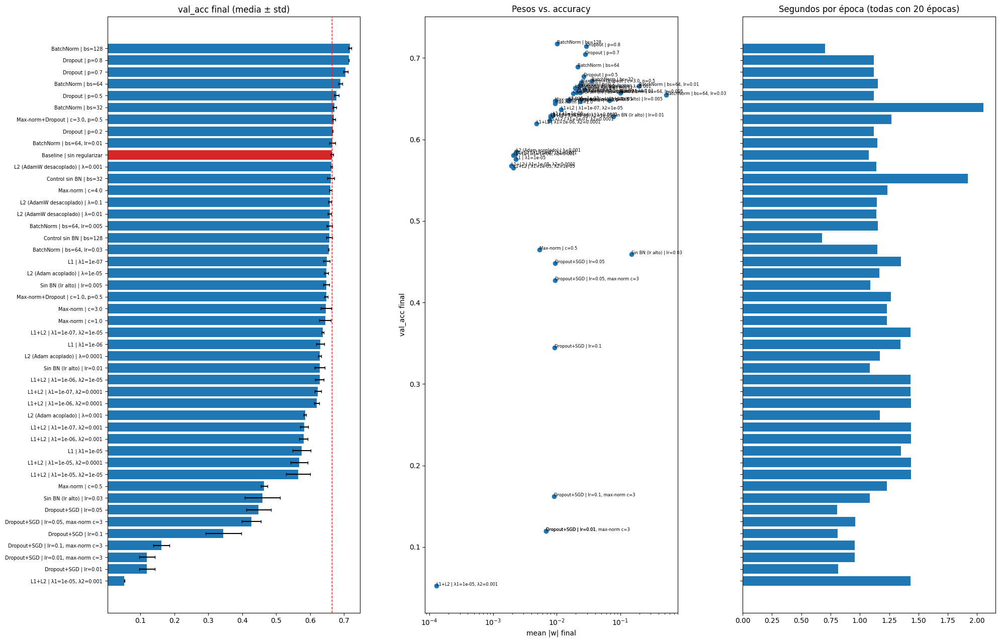

In [ ]:
tabla_reg = summarize().sort_values("val_final", ascending=False)
pd.set_option("display.max_rows", 100)
display(tabla_reg.round(4))
pd.DataFrame(reg_rows).to_csv(f"{RESULTS_DIR}/tp3_regularizacion_por_semilla.csv", index=False)
tabla_reg.to_csv(f"{RESULTS_DIR}/tp3_regularizacion_resumen.csv")

fig, axes = plt.subplots(1, 3, figsize=(20, max(6, 0.28 * len(tabla_reg))))
ypos = np.arange(len(tabla_reg))
base_val = tabla_reg.loc[BASE_KEY, "val_final"]
axes[0].barh(ypos, tabla_reg["val_final"], xerr=tabla_reg["val_final_std"], capsize=2,
             color=["tab:red" if k == BASE_KEY else "tab:blue" for k in tabla_reg.index])
axes[0].axvline(base_val, color="tab:red", ls="--", lw=1)
axes[0].set_yticks(ypos); axes[0].set_yticklabels(tabla_reg.index, fontsize=7); axes[0].invert_yaxis()
axes[0].set_xlim(tabla_reg["val_final"].min() - 0.05, tabla_reg["val_final"].max() + 0.03)
axes[0].set_title("val_acc final (media ± std)")
axes[1].scatter(tabla_reg["mean_abs_w"], tabla_reg["val_final"])
for k, r in tabla_reg.iterrows():
    axes[1].annotate(k, (r["mean_abs_w"], r["val_final"]), fontsize=6)
axes[1].set_xscale("log"); axes[1].set_xlabel("mean |w| final"); axes[1].set_ylabel("val_acc final")
axes[1].set_title("Pesos vs. accuracy")
axes[2].barh(ypos, tabla_reg["s_por_epoca"]); axes[2].set_yticks(ypos); axes[2].set_yticklabels([])
axes[2].invert_yaxis(); axes[2].set_title(f"Segundos por época (todas con {EPOCHS_REG} épocas)")
plt.tight_layout(); plt.show()

## 25. 🔧 Búsqueda conjunta en Optuna con las técnicas como hiperparámetros

Lo que pide la consigna es incluir las técnicas como **hiperparámetros posibles** del TP de clasificación. Los barridos de 17 a 23 varían una dimensión por vez y sirven para entender cada técnica, pero no muestran **interacciones**: por ejemplo, si dropout y L2 se pisan, o si BN habilita un lr más alto que después cambia el óptimo. Por eso se suma una búsqueda conjunta.

Espacio de búsqueda (preprocesamiento fijo en el mejor del MLP, ya vectorizado en la sección 13):
- Arquitectura: 1 a 3 capas de {64, 256, 1024} neuronas, activación ReLU / LeakyReLU.
- Optimizador: Adam (L2 acoplado) o AdamW (decoupled), `lr` en escala log, `weight_decay` en escala log (o 0).
- L1: λ₁ en escala log (o 0).
- Dropout p ∈ [0, 0.8].
- BatchNorm sí/no.
- Max-norm: sin restricción o c ∈ [0.5, 4] (log).
- `batch_size` ∈ {32, 64, 128}.

Usa el mismo presupuesto que las búsquedas del TP2 (`N_TRIALS`, `EPOCHS_SEARCH` con early stopping), la semilla del sampler y `MedianPruner`. Al final se calcula la **importancia de cada hiperparámetro** con el evaluador por defecto de `optuna.importance`.

**Qué hace este código:** `objective_reg` arma el modelo con los HP del trial y entrena con un loop que soporta L1, max-norm, early stopping y pruning. Se reutiliza `train_reg` época a época para no duplicar código.

[I 2026-11-19 19:39:32,120] A new study created in memory with name: mlp_regularizado
[I 2026-11-19 19:39:36,196] Trial 0 finished with value: 0.6844896155545735 and parameters: {'n_layers': 2, 'units_l0': 64, 'units_l1': 64, 'activation': 'relu', 'optimizer': 'adam', 'lr': 0.025268782075084553, 'use_weight_decay': False, 'use_l1': True, 'l1_lambda': 8.179499475211672e-08, 'dropout': 0.4198051453057903, 'batchnorm': False, 'use_max_norm': False, 'batch_size': 128}. Best is trial 0 with value: 0.6844896155545735.
[I 2026-11-19 19:39:58,121] Trial 1 finished with value: 0.7087936367653557 and parameters: {'n_layers': 3, 'units_l0': 1024, 'units_l1': 256, 'units_l2': 1024, 'activation': 'relu', 'optimizer': 'adamw', 'lr': 0.0012311503632415643, 'use_weight_decay': True, 'weight_decay': 1.485739280627925e-06, 'use_l1': False, 'dropout': 0.5300178274831856, 'batchnorm': True, 'use_max_norm': False, 'batch_size': 32}. Best is trial 1 with value: 0.7087936367653557.
[I 2026-11-19 19:40:02,537

Mejor val (regularizado): 0.7503 | tiempo: 164.8 s
Mejores HP: {'n_layers': 1, 'units_l0': 64, 'activation': 'relu', 'optimizer': 'adamw', 'lr': 0.005774961180596589, 'use_weight_decay': True, 'weight_decay': 9.079035567843734e-06, 'use_l1': False, 'dropout': 0.48614847005043, 'batchnorm': False, 'use_max_norm': False, 'batch_size': 128}


,number,value,datetime_start,datetime_complete,duration,params_activation,params_batch_size,params_batchnorm,params_dropout,params_l1_lambda,...,params_units_l2,params_use_l1,params_use_max_norm,params_use_weight_decay,params_weight_decay,user_attrs_best_epoch,user_attrs_mean_abs_w,user_attrs_train_time_sec,system_attrs_tpe:relative_params:0,state
31,31,0.750331,2026-11-19 19:41:55.703245,2026-11-19 19:41:59.464649,0 days 00:00:03.761404,relu,128,False,0.385659,NaN,...,NaN,False,False,True,0.000100,6.0,0.132718,3.718105,"{""activation"": ""relu"", ""batch_size"": 128, ""bat...",COMPLETE
21,21,0.750331,2026-11-19 19:41:29.313950,2026-11-19 19:41:32.565419,0 days 00:00:03.251469,relu,128,False,0.486148,NaN,...,NaN,False,False,True,0.000009,4.0,0.141486,3.208861,"{""activation"": ""relu"", ""batch_size"": 128, ""bat...",COMPLETE
28,28,0.749006,2026-11-19 19:41:49.313679,2026-11-19 19:41:53.341585,0 days 00:00:04.027906,relu,128,False,0.634076,NaN,...,NaN,False,False,False,NaN,7.0,0.126835,3.995496,"{""activation"": ""relu"", ""batch_size"": 128, ""bat...",COMPLETE
22,22,0.748564,2026-11-19 19:41:32.566793,2026-11-19 19:41:36.969394,0 days 00:00:04.402601,relu,128,False,0.585633,NaN,...,NaN,False,False,True,0.000007,8.0,0.113545,4.359881,"{""activation"": ""relu"", ""batch_size"": 128, ""bat...",COMPLETE
17,17,0.748122,2026-11-19 19:41:08.976680,2026-11-19 19:41:14.267227,0 days 00:00:05.290547,relu,128,False,0.765702,NaN,...,NaN,False,False,True,0.000034,9.0,0.037839,5.170478,"{""activation"": ""relu"", ""batch_size"": 128, ""bat...",COMPLETE
6,6,0.747680,2026-11-19 19:40:12.893432,2026-11-19 19:40:16.558936,0 days 00:00:03.665504,relu,128,False,0.472714,NaN,...,NaN,False,False,True,0.000040,4.0,0.061261,3.552123,NaN,COMPLETE
34,34,0.747680,2026-11-19 19:42:06.470689,2026-11-19 19:42:10.077001,0 days 00:00:03.606312,relu,128,False,0.461608,NaN,...,NaN,False,False,False,NaN,6.0,0.138158,3.570743,"{""activation"": ""relu"", ""batch_size"": 128, ""bat...",COMPLETE
33,33,0.746796,2026-11-19 19:42:03.637845,2026-11-19 19:42:06.469306,0 days 00:00:02.831461,relu,128,False,0.299178,NaN,...,NaN,False,False,True,0.000100,4.0,0.146700,2.794020,"{""activation"": ""relu"", ""batch_size"": 128, ""bat...",COMPLETE
14,14,0.745913,2026-11-19 19:40:52.991750,2026-11-19 19:41:02.749278,0 days 00:00:09.757528,leaky_relu,32,False,0.160765,1.670030e-08,...,NaN,True,False,False,NaN,10.0,0.075706,9.712128,"{""activation"": ""leaky_relu"", ""batch_size"": 32,...",COMPLETE
8,8,0.743261,2026-11-19 19:40:23.422606,2026-11-19 19:40:29.203094,0 days 00:00:05.780488,leaky_relu,32,False,0.260320,5.149289e-08,...,NaN,True,False,False,NaN,3.0,0.113436,5.752699,NaN,COMPLETE


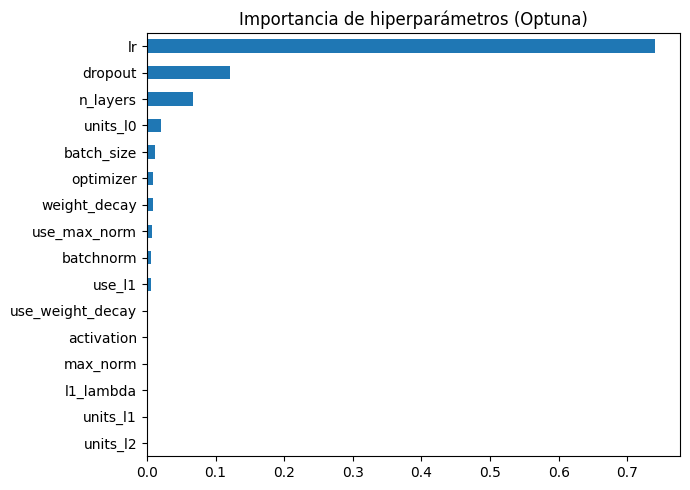

In [ ]:
def objective_reg(trial):
    n_layers = trial.suggest_int("n_layers", 1, 3)
    hidden = [trial.suggest_categorical(f"units_l{i}", [64, 256, 1024]) for i in range(n_layers)]
    activation = trial.suggest_categorical("activation", ["relu", "leaky_relu"])
    opt_name = trial.suggest_categorical("optimizer", ["adam", "adamw"])
    lr = trial.suggest_float("lr", 1e-4, 3e-2, log=True)
    use_wd = trial.suggest_categorical("use_weight_decay", [False, True])
    wd = trial.suggest_float("weight_decay", 1e-6, 1e-1, log=True) if use_wd else 0.0
    use_l1 = trial.suggest_categorical("use_l1", [False, True])
    l1 = trial.suggest_float("l1_lambda", 1e-8, 1e-5, log=True) if use_l1 else 0.0
    dropout = trial.suggest_float("dropout", 0.0, 0.8)
    use_bn = trial.suggest_categorical("batchnorm", [False, True])
    use_mn = trial.suggest_categorical("use_max_norm", [False, True])
    max_norm = trial.suggest_float("max_norm", 0.5, 4.0, log=True) if use_mn else None
    bs = trial.suggest_categorical("batch_size", [32, 64, 128])

    set_seed(SEED)
    model = RegularizedMLP(INPUT_DIM_REG, hidden, activation, NUM_CLASSES, dropout_rate=dropout, use_batchnorm=use_bn)
    decay = [p for n, p in model.named_parameters() if n.endswith(".weight") and p.dim() > 1]
    no_decay = [p for n, p in model.named_parameters() if not (n.endswith(".weight") and p.dim() > 1)]
    groups = [{"params": decay, "weight_decay": wd}, {"params": no_decay, "weight_decay": 0.0}]
    optimizer = (optim.Adam if opt_name == "adam" else optim.AdamW)(groups, lr=lr)
    tr_loader, va_loader = make_loader(ds_tr_of, bs, True, SEED), make_loader(ds_val_of, bs, False)

    best, best_ep, since_best, t0 = -1.0, 0, 0, time.perf_counter()
    for epoch in range(EPOCHS_SEARCH):
        h = train_reg(model, tr_loader, va_loader, optimizer, 1, l1_lambda=l1, max_norm=max_norm)
        va = h["val_acc"][-1]
        if va > best:
            best, best_ep, since_best = va, epoch + 1, 0
        else:
            since_best += 1
        trial.report(va, epoch)
        if trial.should_prune():
            trial.set_user_attr("train_time_sec", time.perf_counter() - t0)
            raise optuna.TrialPruned()
        if since_best >= PATIENCE_SEARCH:
            break
    trial.set_user_attr("train_time_sec", time.perf_counter() - t0)
    trial.set_user_attr("best_epoch", best_ep)
    trial.set_user_attr("mean_abs_w", get_weight_stats(model)["mean_abs"])
    return best


study_reg = optuna.create_study(direction="maximize", study_name="mlp_regularizado",
                                sampler=optuna.samplers.TPESampler(seed=SEED),
                                pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=2))
t0 = time.perf_counter()
study_reg.optimize(objective_reg, n_trials=N_TRIALS)
wall_time_reg = time.perf_counter() - t0
print("Mejor val (regularizado):", round(study_reg.best_value, 4), "| tiempo:", round(wall_time_reg, 1), "s")
print("Mejores HP:", study_reg.best_params)
df_reg_trials = study_reg.trials_dataframe()
df_reg_trials.to_csv(f"{RESULTS_DIR}/tp3_optuna_trials.csv", index=False)
display(df_reg_trials.sort_values("value", ascending=False).head(10))

try:
    importances = optuna.importance.get_param_importances(study_reg)
    pd.Series(importances).sort_values().plot.barh(figsize=(7, 5), title="Importancia de hiperparámetros (Optuna)")
    plt.tight_layout(); plt.show()
except Exception as e:
    print("No se pudo calcular la importancia:", e)

## 26. 🔧 Modelo regularizado final: semillas y test

Se reentrena la mejor configuración de la sección 25 con el protocolo final (`MAX_EPOCHS_FINAL` épocas, early stopping con `PATIENCE_FINAL` sobre la validación y restauración de la mejor época) y con las 5 semillas de `SEEDS`. Después se evalúa **en test**. Se compara contra la softmax (Parte 1) y el MLP sin regularizar (Parte 2) con el mismo protocolo, y con test de Welch.

**Qué hace este código:** reconstruye modelo y optimizador desde `study_reg.best_params`, entrena época a época con early stopping, restaura los mejores pesos, evalúa en test y arma la tabla comparativa final.

In [ ]:
bp = study_reg.best_params
hidden_best = [bp[f"units_l{i}"] for i in range(bp["n_layers"])]
wd_best = bp.get("weight_decay", 0.0) if bp["use_weight_decay"] else 0.0
l1_best = bp.get("l1_lambda", 0.0) if bp["use_l1"] else 0.0
mn_best = bp.get("max_norm") if bp["use_max_norm"] else None
test_loader_of = make_loader(ds_test_of, bp["batch_size"], False)

seed_rows_reg = []
for seed in SEEDS:
    set_seed(seed)
    m = RegularizedMLP(INPUT_DIM_REG, hidden_best, bp["activation"], NUM_CLASSES,
                       dropout_rate=bp["dropout"], use_batchnorm=bp["batchnorm"])
    decay = [p for n, p in m.named_parameters() if n.endswith(".weight") and p.dim() > 1]
    no_decay = [p for n, p in m.named_parameters() if not (n.endswith(".weight") and p.dim() > 1)]
    opt = (optim.Adam if bp["optimizer"] == "adam" else optim.AdamW)(
        [{"params": decay, "weight_decay": wd_best}, {"params": no_decay, "weight_decay": 0.0}], lr=bp["lr"])
    tr_loader = make_loader(ds_tr_of, bp["batch_size"], True, seed)
    va_loader = make_loader(ds_val_of, bp["batch_size"], False)
    best, best_ep, since, best_state, t0, t_best = -1.0, 0, 0, None, time.perf_counter(), 0.0
    for epoch in range(MAX_EPOCHS_FINAL):
        h = train_reg(m, tr_loader, va_loader, opt, 1, l1_lambda=l1_best, max_norm=mn_best)
        if h["val_acc"][-1] > best:
            best, best_ep, since = h["val_acc"][-1], epoch + 1, 0
            best_state, t_best = copy.deepcopy(m.state_dict()), time.perf_counter() - t0
        else:
            since += 1
        if since >= PATIENCE_FINAL:
            break
    t_total = time.perf_counter() - t0
    m.load_state_dict(best_state)
    acc_test, preds_reg, labels_reg = evaluate(m, test_loader_of)
    ws = get_weight_stats(m)
    seed_rows_reg.append({"seed": seed, "val_acc": best, "test_acc": acc_test, "best_epoch": best_ep,
                          "train_time_sec": t_total, "time_to_best_sec": t_best, "mean_abs_w": ws["mean_abs"]})
df_seeds_reg = pd.DataFrame(seed_rows_reg)
df_seeds_reg.to_csv(f"{RESULTS_DIR}/tp3_reg_seeds.csv", index=False)
display(df_seeds_reg.round(4))

comparacion_final = pd.DataFrame({
    name: {"val_media": d.val_acc.mean(), "val_std": d.val_acc.std(), "test_media": d.test_acc.mean(),
           "test_std": d.test_acc.std(), "epoca_mejor_media": d.best_epoch.mean(),
           "t_entrenamiento_media_s": d.train_time_sec.mean()}
    for name, d in [("softmax (TP1)", df_seeds_softmax_disk), ("MLP sin regularizar (TP2)", df_seeds_mlp),
                    ("MLP regularizado (TP3)", df_seeds_reg)]}).T
display(comparacion_final.round(4))
for name, d in [("softmax", df_seeds_softmax_disk), ("MLP sin reg.", df_seeds_mlp)]:
    t, p = stats.ttest_ind(df_seeds_reg.test_acc, d.test_acc, equal_var=False)
    print(f"test: regularizado - {name} = {100*(df_seeds_reg.test_acc.mean() - d.test_acc.mean()):+.2f} pp (p = {p:.3f})")
print("\n(Último modelo, semilla", SEEDS[-1], ")")
print(classification_report(labels_reg, preds_reg, target_names=class_names, digits=3))

,seed,val_acc,test_acc,best_epoch,train_time_sec,time_to_best_sec,mean_abs_w
0,0,0.7477,0.6818,4,3.6191,1.5951,0.1149
1,1,0.7455,0.6741,7,4.7783,2.7717,0.1433
2,2,0.7415,0.6811,4,4.1086,1.7790,0.1148
3,3,0.7477,0.6811,6,4.4981,2.4824,0.1339
4,4,0.7446,0.6827,5,4.0011,2.0151,0.1252


,val_media,val_std,test_media,test_std,epoca_mejor_media,t_entrenamiento_media_s
softmax (TP1),0.7401,0.0039,0.6691,0.0016,2.8,3.5920
MLP sin regularizar (TP2),0.7504,0.0012,0.6871,0.0035,6.0,6.3737
MLP regularizado (TP3),0.7454,0.0026,0.6801,0.0035,5.2,4.2010


test: regularizado - softmax = +1.10 pp (p = 0.001)
test: regularizado - MLP sin reg. = -0.70 pp (p = 0.013)

(Último modelo, semilla 4 )
                          precision    recall  f1-score   support

             alt.atheism      0.487     0.567     0.524       319
           comp.graphics      0.615     0.653     0.633       389
 comp.os.ms-windows.misc      0.618     0.584     0.601       394
comp.sys.ibm.pc.hardware      0.645     0.630     0.637       392
   comp.sys.mac.hardware      0.719     0.717     0.718       385
          comp.windows.x      0.807     0.666     0.730       395
            misc.forsale      0.762     0.787     0.774       390
               rec.autos      0.481     0.737     0.582       396
         rec.motorcycles      0.719     0.726     0.723       398
      rec.sport.baseball      0.893     0.796     0.842       397
        rec.sport.hockey      0.889     0.887     0.888       399
               sci.crypt      0.801     0.712     0.754       396
   

## 27. Análisis final

**Ranking controlado (24).** Todas las configuraciones tienen las mismas 20 épocas, el mismo split y las mismas 3 semillas. Las que superan al baseline (0,6645 ± 0,0033) con p < 0,05 son:

1. BatchNorm, batch 128: 0,7176 ± 0,0046
2. Dropout p = 0,8: 0,7147 ± 0,0003
3. Dropout p = 0,7: 0,7047 ± 0,0067
4. BatchNorm, batch 64: 0,6894 ± 0,0054
5. Dropout p = 0,5: 0,6777 ± 0,0064

BN con batch 128 y dropout 0,8 no se distinguen entre sí. Dropout 0,2, max-norm con c ≥ 1, max-norm + dropout y AdamW empatan con el baseline. Todas las configuraciones de L1, L2 acoplado y L1+L2 quedan por debajo, y también todas las de SGD. Esto corrige el ranking de la entrega anterior: aquella comparación tenía épocas distintas y una sola corrida, y ahora las diferencias se contrastan con el ruido entre semillas.

**Valores absolutos de los pesos.** Cada técnica actúa sobre los pesos de forma distinta:
- L2 con Adam achica los pesos y, por el acoplamiento con la normalización de Adam, deja entre 38 y 80 % en casi cero.
- AdamW, con λ razonables, casi no los toca.
- L1 los vuelve esparsos (hasta 91 % casi cero).
- Max-norm acota la norma de cada neurona.
- Dropout los hace crecer un poco (0,029 contra 0,022).
- BN los deja iguales con lr bajo, y con lr alto los deja crecer sin que importe.

Las técnicas que más achican los pesos (L1, L2) son justamente las que peor generalizan. En esta red, el sobreajuste no viene de que los pesos sean grandes, sino de que hay más unidades de las que el problema necesita.

**Tiempos.** Todas con las mismas 20 épocas:

| Técnica | s/época | vs. baseline |
|---|---|---|
| Baseline (Adam, batch 64) | 1,08 | – |
| Dropout | 1,12 | +4 % |
| AdamW | 1,14 | +6 % |
| BatchNorm (batch 64) | 1,15 | +7 % |
| L2 (Adam) | 1,17 | +8 % |
| Max-norm | 1,23 | +14 % |
| L1 | 1,35 | +25 % |
| L1+L2 | 1,43 | +33 % |
| SGD + dropout | 0,81 | −25 % |
| Sin BN, batch 32 / 128 | 1,92 / 0,68 | +78 % / −37 % |

L1 es la técnica más cara, porque calcula Σ|w| sobre 12 millones de pesos en cada paso y agrega ese término al grafo de backpropagation. De todas formas, el tamaño de batch pesa más que cualquier técnica, porque define la cantidad de pasos por época.

**Learning rate.**
- Con dropout y SGD, subir el lr ×5 funciona (de 0,12 a 0,45) porque saca a la red del plateau inicial, pero ×10 ya es inestable, y max-norm no lo corrigió (21.1).
- BN permite subir el lr ×30 sin que el entrenamiento se rompa (0,65 contra 0,46 sin BN), aunque con Adam eso no mejora el resultado (23.1).
- En la búsqueda conjunta, el lr fue por lejos el hiperparámetro más importante (25).

**Ruido en las curvas.**
- BN suaviza mucho la curva de validación: `rugos_val` baja aproximadamente a la mitad.
- Achicar el batch aumenta el ruido de la loss por mini-batch, con y sin BN.
- Con dropout, el ruido en train que describe la cátedra no se ve en las curvas por época. Las métricas que definimos no lo capturan bien, por los problemas que comento en la sección 21.

**Búsqueda conjunta (25).** De 40 trials, el pruner cortó 17 y la búsqueda tardó 164,8 s. La mejor configuración fue una red 1×64 con ReLU, AdamW con lr ≈ 5,8·10⁻³, dropout ≈ 0,49 y batch 128, sin BN, sin max-norm y sin L1, y con weight decay de 9·10⁻⁶, que por la cuenta de la sección 18 no tiene efecto práctico. Los 8 mejores trials tienen todos una sola capa (64 o 256 neuronas), ReLU, batch 128 y dropout entre 0,30 y 0,77, y ninguno usa BN, max-norm ni L1. Según la importancia de Optuna, el lr explica ≈74 % de la variación, el dropout ≈12 % y la cantidad de capas ≈7 %; el resto queda por debajo del 3 %. Con la arquitectura libre, Optuna prefirió achicar la red antes que regularizar una grande, y de las técnicas solo conservó dropout.

**Modelo final (26).**

| | val (5 semillas) | test (5 semillas) | época de la mejor val | tiempo |
|---|---|---|---|---|
| Softmax (TP1) | 0,7401 ± 0,0039 | 0,6691 ± 0,0016 | 2,8 | 3,6 s |
| MLP sin regularizar (TP2) | 0,7504 ± 0,0012 | **0,6871 ± 0,0035** | 6,0 | 6,4 s |
| MLP regularizado (TP3) | 0,7454 ± 0,0026 | 0,6801 ± 0,0035 | 5,2 | 4,2 s |

El modelo regularizado le gana a la softmax (+1,1 pp en test, p = 0,001), pero queda 0,7 pp por debajo del MLP sin regularizar (p = 0,013). Creo que lo explican dos cosas:
- El mejor trial de la búsqueda (0,7503) es el máximo de 40 trials con una sola semilla. Con 5 semillas baja a 0,7454: parte de lo que lo hacía "el mejor" era suerte, un sesgo de selección de quedarse con el máximo.
- El MLP de la Parte 2 ya era una red chica (1×256) con early stopping, y eso es justamente lo que la cátedra propone para alta varianza ("achicar red, early stop, regularización"). La regularización ayudó mucho donde había sobreajuste (la red 3×1024 pasó de 0,6645 a 0,7176), pero no superó a una red del tamaño adecuado. Incluso la mejor red 3×1024 regularizada (0,7176) queda por debajo de una 1×64 sin regularizar (mejor val de 0,7499 en la sección 13).

**Conclusión.** En este problema (TF-IDF de 10000 términos y unos 9000 documentos de train), lo que más controla el sobreajuste es el tamaño de la red. Entre las técnicas:
- Dropout y BatchNorm mejoran claramente a la red sobredimensionada.
- Max-norm y AdamW, con valores razonables, no cambian el resultado.
- L1, L2 acoplado y su combinación lo empeoran, aunque achican los pesos.

Creo que se debe a que el sobreajuste de esta red viene del exceso de unidades y no de la magnitud de los pesos (el baseline sobreajusta con `mean|w|` = 0,02). Penalizar los pesos de la primera capa apaga sobre todo las conexiones con los términos poco frecuentes, que probablemente sean de los más específicos de cada categoría.